# Audit v11 Current Best Prompt Summary

This notebook reads the existing audit-v11 artifact CSVs and:

- selects the current best prompt family automatically from the finished conditions;
- shows only that prompt family in the downstream method comparison;
- reports spec F1 and both original-text and extracted-code LLM judge results separately;
- prints LaTeX tables for the current results, with the best values bolded.

The current-best prompt family is selected by the highest Structured
score on the **Original segmentation text** LLM judge aggregate table.


In [1]:
from pathlib import Path
import csv
import json
import math
import random

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 20,
    'axes.labelsize': 17,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 14,
    'figure.titlesize': 22,
})

try:
    from IPython.display import display, Markdown
except Exception:
    display = print
    Markdown = lambda x: x

ROOT_DIR = Path('/mnt/md0/weiqiuy/surgent')
OUT_DIR = ROOT_DIR / 'notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary'
OUT_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS = {
    'base': {
        'label': 'Base prompts',
        'artifact_dir': ROOT_DIR / 'notebooks/artifacts/qwen3.5_audit_v11_seg_extract_spec_eval',
    },
    'cvs_context': {
        'label': 'CVS-context prompts (frozen)',
        'artifact_dir': ROOT_DIR / 'notebooks/artifacts/qwen3.5_audit_v11_seg_extract_spec_eval_with_cvs_context',
    },
    'cvsctx_v2': {
        'label': 'CVS-context v2',
        'artifact_dir': ROOT_DIR / 'notebooks/artifacts/qwen3.5_audit_v11_seg_extract_spec_eval_cvsctx_v2__baseline',
    },
    'cvsctx_v3': {
        'label': 'CVS-context v3 (debug5)',
        'artifact_dir': ROOT_DIR / 'notebooks/artifacts/qwen3.5_audit_v11_seg_extract_spec_eval_cvsctx_v3__debug5',
    },
}

METHOD_ORDER = ['description_only', 'hint_questions', 'structured_prediction', 'structured_prediction_deterministic']
METHOD_LABELS = {
    'description_only': 'Description',
    'hint_questions': 'Hint',
    'structured_prediction': 'Structured',
    'structured_prediction_deterministic': 'Structured Deterministic',
}
ACTOR_ORDER = ['left', 'right', 'camera', 'other']
ACTOR_LABELS = {
    'left': 'Left',
    'right': 'Right',
    'camera': 'Camera',
    'other': 'Other',
    'aggregate': 'Aggregate',
}
PRIMARY_METHOD = 'structured_prediction'
PRIMARY_CANDIDATE = 'original_text'

print('repo root:', ROOT_DIR)
print('output dir:', OUT_DIR)
for key, meta in ARTIFACTS.items():
    print(f'{key}: {meta["artifact_dir"]}')


repo root: /mnt/md0/weiqiuy/surgent
output dir: /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary
base: /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_seg_extract_spec_eval
cvs_context: /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_seg_extract_spec_eval_with_cvs_context
cvsctx_v2: /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_seg_extract_spec_eval_cvsctx_v2__baseline
cvsctx_v3: /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_seg_extract_spec_eval_cvsctx_v3__debug5


In [2]:
def normalize_method(method):
    return str(method).removesuffix('_cvs_context')


def candidate_kind_from_label(value):
    mapping = {
        'Extracted code JSON': 'extracted_json',
        'Original segmentation text': 'original_text',
        'wrong_tool': 'wrong_tool',
    }
    return mapping.get(str(value), str(value))


def read_csv_artifact(condition, filename):
    path = ARTIFACTS[condition]['artifact_dir'] / filename
    if not path.exists():
        raise FileNotFoundError(path)
    return pd.read_csv(path)


def read_json_artifact(condition, filename):
    path = ARTIFACTS[condition]['artifact_dir'] / filename
    if not path.exists():
        raise FileNotFoundError(path)
    return json.loads(path.read_text())


def load_spec_overall_long(condition):
    df = read_csv_artifact(condition, 'spec_f1_overall_aggregate.csv').copy()
    score_col = 'aggregate mean F1' if 'aggregate mean F1' in df.columns else 'f1_mean_avg'
    rows_col = 'rows' if 'rows' in df.columns else 'n_rows'
    out = df.rename(columns={score_col: 'spec_f1', rows_col: 'n_rows'})
    out['base_method'] = out['method'].map(normalize_method)
    out['condition'] = condition
    return out[['condition', 'method', 'base_method', 'spec_f1', 'n_rows']]


def load_spec_actor_long(condition):
    df = read_csv_artifact(condition, 'spec_f1_actor_aggregate_table.csv').copy()
    out = df.melt(id_vars=['actor'], var_name='method', value_name='mean_f1')
    out['base_method'] = out['method'].map(normalize_method)
    out['condition'] = condition
    return out[['condition', 'actor', 'method', 'base_method', 'mean_f1']]


def load_spec_detail_long(condition):
    df = read_csv_artifact(condition, 'spec_eval_summary.csv').copy()
    out = df.copy()
    out['base_method'] = out['method'].map(normalize_method)
    out['condition'] = condition
    out['iou'] = pd.to_numeric(out['iou'], errors='coerce')
    out['f1_mean'] = pd.to_numeric(out['f1_mean'], errors='coerce')
    return out[['condition', 'actor', 'granularity', 'iou', 'method', 'base_method', 'f1_mean']]


def load_spec_results_map(condition):
    raw = read_json_artifact(condition, 'spec_eval_results.json')
    return {normalize_method(method): rows for method, rows in raw.items()}


def load_judge_aggregate_long(condition):
    df = read_csv_artifact(condition, 'llm_judge_aggregate_table.csv').copy()
    out = df.melt(id_vars=['candidate'], var_name='method', value_name='mean_score')
    out['candidate_kind'] = out['candidate'].map(candidate_kind_from_label)
    out['base_method'] = out['method'].map(normalize_method)
    out['condition'] = condition
    out['mean_score'] = pd.to_numeric(out['mean_score'], errors='coerce')
    return out[['condition', 'candidate_kind', 'candidate', 'method', 'base_method', 'mean_score']]


def load_judge_summary_long(condition):
    df = read_csv_artifact(condition, 'llm_judge_summary.csv').copy()
    out = df.copy()
    out['base_method'] = out['method'].map(normalize_method)
    out['condition'] = condition
    out['mean_score'] = pd.to_numeric(out['mean_score'], errors='coerce')
    return out[['condition', 'candidate_kind', 'rubric_item', 'method', 'base_method', 'n', 'mean_score']]


def bold_best_per_row(df, fmt='{:.3f}'):
    rendered = df.copy().astype(object)
    numeric_df = rendered.apply(pd.to_numeric, errors='coerce')
    for idx in rendered.index:
        row = numeric_df.loc[idx]
        if row.notna().sum() == 0:
            continue
        best = row.max()
        for col in rendered.columns:
            val = numeric_df.loc[idx, col]
            if pd.isna(val):
                rendered.loc[idx, col] = ''
            elif val == best:
                rendered.loc[idx, col] = f'\\\\textbf{{{fmt.format(float(val))}}}'
            else:
                rendered.loc[idx, col] = fmt.format(float(val))
    return rendered


def bold_best_per_col(df, fmt='{:.3f}'):
    rendered = df.copy().astype(object)
    numeric_df = rendered.apply(pd.to_numeric, errors='coerce')
    for col in rendered.columns:
        series = numeric_df[col]
        if series.notna().sum() == 0:
            rendered[col] = ''
            continue
        best = series.max()
        new_vals = []
        for idx, val in series.items():
            if pd.isna(val):
                new_vals.append('')
            elif val == best:
                new_vals.append(f'\\\\textbf{{{fmt.format(float(val))}}}')
            else:
                new_vals.append(fmt.format(float(val)))
        rendered[col] = new_vals
    return rendered


def latex_table(df, index=True, caption=None, label=None):
    return df.to_latex(index=index, escape=False, caption=caption, label=label)


def rubric_actor_order_key(rubric_item):
    text = str(rubric_item)
    actor_rank = len(ACTOR_ORDER)
    for idx, actor in enumerate(ACTOR_ORDER):
        if text.startswith(f'{actor}_'):
            actor_rank = idx
            break
    return (actor_rank, text)


def f1_lookup(spec_detail, base_method, actor, granularity, iou):
    rows = spec_detail[
        (spec_detail['base_method'] == base_method)
        & (spec_detail['actor'] == actor)
        & (spec_detail['granularity'] == granularity)
        & (spec_detail['iou'] == iou)
    ]['f1_mean']
    if len(rows) == 0:
        return '--'
    return f'{float(rows.iloc[0]):.3f}'


def f1_lookup_float(spec_detail, base_method, actor, granularity, iou):
    rows = spec_detail[
        (spec_detail['base_method'] == base_method)
        & (spec_detail['actor'] == actor)
        & (spec_detail['granularity'] == granularity)
        & (spec_detail['iou'] == iou)
    ]['f1_mean']
    if len(rows) == 0:
        return None
    return float(rows.iloc[0])


def bootstrap_strategy_summary(spec_results_map, base_method, *, n_boot=1000, seed=0):
    method_rows = spec_results_map.get(base_method, [])
    selected = []
    for row in method_rows:
        if row.get('actor') not in {'left', 'right', 'camera'}:
            continue
        if row.get('granularity') not in {'exact', 'medium', 'coarse'}:
            continue
        if float(row.get('iou')) not in {0.10, 0.25, 0.50}:
            continue
        values = [float(d['f1']) for d in row.get('details', [])]
        if values:
            selected.append(values)
    if not selected:
        return {'mean': None, 'std': None, 'lo': None, 'hi': None}

    def avg(xs):
        return sum(xs) / len(xs) if xs else float('nan')

    observed = avg([avg(values) for values in selected])
    rng = random.Random(seed)
    samples = []
    for _ in range(n_boot):
        cell_means = []
        for values in selected:
            resampled = [values[rng.randrange(len(values))] for _ in range(len(values))]
            cell_means.append(avg(resampled))
        samples.append(avg(cell_means))
    mu = avg(samples)
    var = avg([(x - mu) ** 2 for x in samples])
    std = var ** 0.5
    ordered = sorted(samples)
    lo = ordered[int(0.025 * (len(ordered) - 1))]
    hi = ordered[int(0.975 * (len(ordered) - 1))]
    return {'mean': observed, 'std': std, 'lo': lo, 'hi': hi}


def build_three_actor_caption(spec_results_map):
    strategy_labels = [
        ('description_only', 'Direct'),
        ('hint_questions', 'Hint-guided'),
        ('structured_prediction', 'Structured'),
    ]
    parts = []
    for base_method, label in strategy_labels:
        stats = bootstrap_strategy_summary(spec_results_map, base_method, n_boot=1000, seed=7)
        if stats['mean'] is None:
            parts.append(f'{label}: unavailable')
        else:
            parts.append(
                f"{label} average {stats['mean']:.3f} ["
                f"{stats['lo']:.3f}, {stats['hi']:.3f}]"
            )
    joined = '; '.join(parts)
    return (
        'Actor-specific segment-level F1 for the current best prompt family on audit-v11. '
        'For Left, exact uses the full retraction-direction code, medium collapses to direction only, and coarse collapses to maintain versus change. '
        'For Right, exact uses tool, action, target, and context together, medium uses tool, action, and target, and coarse uses action and target only. '
        'For Camera, exact distinguishes the full camera action code, medium collapses to zoom versus reposition versus no-change, and coarse collapses to change versus no-change. '
        'F1@10, F1@25, and F1@50 mean F1 at IoU thresholds 0.10, 0.25, and 0.50 respectively. '
        'Across the 27 displayed left/right/camera cells, 1000-sample bootstrap 95\\% confidence intervals for each strategy average are: '
        + joined + '.'
    )


def build_three_actor_latex(spec_detail, spec_results_map):
    strategy_labels = [
        ('description_only', 'Direct'),
        ('hint_questions', 'Hint-guided'),
        ('structured_prediction', 'Structured'),
    ]
    granularity_labels = [
        ('exact', 'Exact'),
        ('medium', 'Medium'),
        ('coarse', 'Coarse'),
    ]
    lines = [
        r'\begin{table*}[t]',
        r'\centering',
        rf'\caption{{{build_three_actor_caption(spec_results_map)}}}',
        r'\label{tab:auditv11_three_actor_f1}',
        r'\resizebox{\textwidth}{!}{%',
        r'\begin{tabular}{ll ccc ccc ccc}',
        r'\toprule',
        r'& & \multicolumn{3}{c}{Left Instrument} & \multicolumn{3}{c}{Right Instrument} & \multicolumn{3}{c}{Camera} \\',
        r'\cmidrule(lr){3-5} \cmidrule(lr){6-8} \cmidrule(lr){9-11}',
        r'Strategy & Granularity & F1@10 & F1@25 & F1@50 & F1@10 & F1@25 & F1@50 & F1@10 & F1@25 & F1@50 \\',
        r'\midrule',
    ]
    best_lookup = {}
    for granularity, _ in granularity_labels:
        for actor in ['left', 'right', 'camera']:
            for iou in [0.10, 0.25, 0.50]:
                vals = [
                    f1_lookup_float(spec_detail, base_method, actor, granularity, iou)
                    for base_method, _ in strategy_labels
                ]
                vals = [v for v in vals if v is not None]
                best_lookup[(granularity, actor, iou)] = max(vals) if vals else None

    def render_cell(base_method, actor, granularity, iou):
        value = f1_lookup_float(spec_detail, base_method, actor, granularity, iou)
        if value is None:
            return '--'
        text = f'{value:.3f}'
        best = best_lookup.get((granularity, actor, iou))
        if best is not None and value == best:
            return rf'\textbf{{{text}}}'
        return text

    for s_idx, (base_method, strategy_name) in enumerate(strategy_labels):
        lines.append(rf'\multirow{{3}}{{*}}{{{strategy_name}}}')
        for granularity, display_label in granularity_labels:
            left10 = render_cell(base_method, 'left', granularity, 0.10)
            left25 = render_cell(base_method, 'left', granularity, 0.25)
            left50 = render_cell(base_method, 'left', granularity, 0.50)
            right10 = render_cell(base_method, 'right', granularity, 0.10)
            right25 = render_cell(base_method, 'right', granularity, 0.25)
            right50 = render_cell(base_method, 'right', granularity, 0.50)
            cam10 = render_cell(base_method, 'camera', granularity, 0.10)
            cam25 = render_cell(base_method, 'camera', granularity, 0.25)
            cam50 = render_cell(base_method, 'camera', granularity, 0.50)
            lines.append(
                f"  & {display_label} & {left10} & {left25} & {left50} & {right10} & {right25} & {right50} & {cam10} & {cam25} & {cam50} \\\\"
            )
        if s_idx != len(strategy_labels) - 1:
            lines.append(r'\midrule')
    lines.extend([
        r'\bottomrule',
        r'\end{tabular}',
        r'}',
        r'\end{table*}',
    ])
    return '\n'.join(lines)


def bootstrap_actor_metric(spec_results_map, base_method, actor=None, *, n_boot=1000, seed=0):
    method_rows = spec_results_map.get(base_method, [])
    selected = []
    for row in method_rows:
        if actor is not None and row.get('actor') != actor:
            continue
        values = [float(d['f1']) for d in row.get('details', [])]
        if values:
            selected.append(values)
    if not selected:
        return {'mean': None, 'std': None, 'lo': None, 'hi': None}

    def avg(xs):
        return sum(xs) / len(xs) if xs else float('nan')

    observed = avg([avg(values) for values in selected])
    rng = random.Random(seed)
    samples = []
    for _ in range(n_boot):
        cell_means = []
        for values in selected:
            resampled = [values[rng.randrange(len(values))] for _ in range(len(values))]
            cell_means.append(avg(resampled))
        samples.append(avg(cell_means))
    mu = avg(samples)
    var = avg([(x - mu) ** 2 for x in samples])
    std = var ** 0.5
    ordered = sorted(samples)
    lo = ordered[int(0.025 * (len(ordered) - 1))]
    hi = ordered[int(0.975 * (len(ordered) - 1))]
    return {'mean': observed, 'std': std, 'lo': lo, 'hi': hi}


def bootstrap_actor_granularity_metric(spec_results_map, base_method, actor, granularity, *, n_boot=1000, seed=0):
    method_rows = spec_results_map.get(base_method, [])
    selected = []
    for row in method_rows:
        if row.get('actor') != actor:
            continue
        if row.get('granularity') != granularity:
            continue
        values = [float(d['f1']) for d in row.get('details', [])]
        if values:
            selected.append(values)
    if not selected:
        return {'mean': None, 'std': None, 'lo': None, 'hi': None}

    def avg(xs):
        return sum(xs) / len(xs) if xs else float('nan')

    observed = avg([avg(values) for values in selected])
    rng = random.Random(seed)
    samples = []
    for _ in range(n_boot):
        cell_means = []
        for values in selected:
            resampled = [values[rng.randrange(len(values))] for _ in range(len(values))]
            cell_means.append(avg(resampled))
        samples.append(avg(cell_means))
    mu = avg(samples)
    var = avg([(x - mu) ** 2 for x in samples])
    std = var ** 0.5
    ordered = sorted(samples)
    lo = ordered[int(0.025 * (len(ordered) - 1))]
    hi = ordered[int(0.975 * (len(ordered) - 1))]
    return {'mean': observed, 'std': std, 'lo': lo, 'hi': hi}


In [3]:
spec_overall_all = pd.concat([load_spec_overall_long(condition) for condition in ARTIFACTS], ignore_index=True)
spec_actor_all = pd.concat([load_spec_actor_long(condition) for condition in ARTIFACTS], ignore_index=True)
spec_detail_all = pd.concat([load_spec_detail_long(condition) for condition in ARTIFACTS], ignore_index=True)
spec_results_all = {condition: load_spec_results_map(condition) for condition in ARTIFACTS}
judge_agg_all = pd.concat([load_judge_aggregate_long(condition) for condition in ARTIFACTS], ignore_index=True)
judge_summary_all = pd.concat([load_judge_summary_long(condition) for condition in ARTIFACTS], ignore_index=True)

selection_df = (
    judge_agg_all[
        (judge_agg_all['candidate_kind'] == PRIMARY_CANDIDATE)
        & (judge_agg_all['base_method'] == PRIMARY_METHOD)
    ][['condition', 'mean_score']]
    .dropna()
    .sort_values(['mean_score', 'condition'], ascending=[False, True])
    .reset_index(drop=True)
)

display(Markdown('## Prompt Family Selection'))
display(selection_df)

CURRENT_BEST_CONDITION = selection_df.iloc[0]['condition']
CURRENT_BEST_LABEL = ARTIFACTS[CURRENT_BEST_CONDITION]['label']

print('Current best prompt family:', CURRENT_BEST_CONDITION, '|', CURRENT_BEST_LABEL)


## Prompt Family Selection

,condition,mean_score
0,cvsctx_v3,0.547475
1,cvs_context,0.529293
2,base,0.520707
3,cvsctx_v2,0.509091


Current best prompt family: cvsctx_v3 | CVS-context v3 (debug5)


In [4]:
spec_overall = spec_overall_all[spec_overall_all['condition'] == CURRENT_BEST_CONDITION].copy()
spec_actor = spec_actor_all[spec_actor_all['condition'] == CURRENT_BEST_CONDITION].copy()
spec_detail = spec_detail_all[spec_detail_all['condition'] == CURRENT_BEST_CONDITION].copy()
spec_results_map = spec_results_all[CURRENT_BEST_CONDITION]
judge_agg = judge_agg_all[judge_agg_all['condition'] == CURRENT_BEST_CONDITION].copy()
judge_summary = judge_summary_all[judge_summary_all['condition'] == CURRENT_BEST_CONDITION].copy()

method_summary = (
    spec_overall[['base_method', 'spec_f1']]
    .merge(
        judge_agg[judge_agg['candidate_kind'] == 'extracted_json'][['base_method', 'mean_score']].rename(columns={'mean_score': 'judge_extracted'}),
        on='base_method',
        how='left',
    )
    .merge(
        judge_agg[judge_agg['candidate_kind'] == 'original_text'][['base_method', 'mean_score']].rename(columns={'mean_score': 'judge_original'}),
        on='base_method',
        how='left',
    )
)
method_summary['method_label'] = method_summary['base_method'].map(METHOD_LABELS)
method_summary = method_summary.set_index('method_label').reindex([METHOD_LABELS[m] for m in METHOD_ORDER])
method_summary = method_summary.rename(columns={'spec_f1': 'Spec F1', 'judge_extracted': 'Judge Extracted', 'judge_original': 'Judge Original'})

best_method_label = method_summary['Judge Original'].idxmax()

display(Markdown(f'## Current Best Prompt Family: `{CURRENT_BEST_LABEL}`'))
display(Markdown('Primary metric for prompt-family selection: Structured on the original-text judge aggregate'))
display(Markdown(f'Current best method inside this prompt family on the same primary metric: **{best_method_label}**'))

display(Markdown('### Method Summary'))
display(method_summary)

method_summary_latex = bold_best_per_col(method_summary[['Spec F1', 'Judge Extracted', 'Judge Original']])
print('LaTeX: method summary')
print(latex_table(method_summary_latex, index=True, caption='Method-level summary for the current best audit-v11 prompt family on the audit-v11 segmentation benchmark, evaluated against human-validated ground truth. Spec F1 reports the aggregate segment-level F1 from the canonical taxonomy evaluation, while Judge Extracted and Judge Original report the LLM-judge scores for extracted code JSON and original segmentation text respectively. Best result per metric column is bolded.', label='tab:auditv11_current_best_method_summary'))


## Current Best Prompt Family: `CVS-context v3 (debug5)`

Primary metric for prompt-family selection: Structured on the original-text judge aggregate

Current best method inside this prompt family on the same primary metric: **Hint**

### Method Summary

,base_method,Spec F1,Judge Extracted,Judge Original
method_label,,,,
Description,description_only,0.199274,0.473737,0.575077
Hint,hint_questions,0.282316,0.497475,0.652525
Structured,structured_prediction,0.323317,0.498990,0.547475
Structured Deterministic,structured_prediction_deterministic,0.276174,0.492929,0.539394


LaTeX: method summary
\begin{table}
\caption{Method-level summary for the current best audit-v11 prompt family on the audit-v11 segmentation benchmark, evaluated against human-validated ground truth. Spec F1 reports the aggregate segment-level F1 from the canonical taxonomy evaluation, while Judge Extracted and Judge Original report the LLM-judge scores for extracted code JSON and original segmentation text respectively. Best result per metric column is bolded.}
\label{tab:auditv11_current_best_method_summary}
\begin{tabular}{llll}
\toprule
 & Spec F1 & Judge Extracted & Judge Original \\
method_label &  &  &  \\
\midrule
Description & 0.199 & 0.474 & 0.575 \\
Hint & 0.282 & 0.497 & \\textbf{0.653} \\
Structured & \\textbf{0.323} & \\textbf{0.499} & 0.547 \\
Structured Deterministic & 0.276 & 0.493 & 0.539 \\
\bottomrule
\end{tabular}
\end{table}



In [5]:
display(Markdown('## Spec F1 Results'))

spec_overall_table = (
    spec_overall[['base_method', 'spec_f1']]
    .assign(method_label=lambda df: df['base_method'].map(METHOD_LABELS))
    .set_index('method_label')[['spec_f1']]
    .reindex([METHOD_LABELS[m] for m in METHOD_ORDER])
)
spec_overall_table = spec_overall_table.rename(columns={'spec_f1': 'Spec F1'})
display(Markdown('### Overall Aggregate F1'))
display(spec_overall_table)
spec_overall_latex = bold_best_per_col(spec_overall_table)
print('LaTeX: spec overall F1')
print(latex_table(spec_overall_latex, index=True, caption='Overall aggregate segment-level F1 for methods within the current best audit-v11 prompt family, evaluated against human-validated ground truth using the canonical taxonomy-based specification. Best result is bolded.', label='tab:auditv11_current_best_spec_overall'))

spec_actor_table = (
    spec_actor
    .pivot_table(index='base_method', columns='actor', values='mean_f1', aggfunc='mean')
    .reindex(index=METHOD_ORDER, columns=ACTOR_ORDER)
)
spec_actor_table['aggregate'] = (
    spec_overall.set_index('base_method').reindex(METHOD_ORDER)['spec_f1']
)
spec_actor_table.index = [METHOD_LABELS[m] for m in spec_actor_table.index]
spec_actor_table = spec_actor_table.rename(columns=ACTOR_LABELS)
spec_actor_table = spec_actor_table[[ACTOR_LABELS[a] for a in ACTOR_ORDER] + [ACTOR_LABELS['aggregate']]]
display(Markdown('### Actor-Level F1'))
display(spec_actor_table)
spec_actor_latex = bold_best_per_col(spec_actor_table)
print('LaTeX: spec actor F1')
print(latex_table(spec_actor_latex, index=True, caption='Actor-wise segment-level F1 for methods within the current best audit-v11 prompt family, evaluated against human-validated ground truth using the canonical taxonomy-based specification. Columns report left, right, camera, other, and aggregate performance; best result per column is bolded.', label='tab:auditv11_current_best_spec_actor'))


## Spec F1 Results

### Overall Aggregate F1

,Spec F1
method_label,
Description,0.199274
Hint,0.282316
Structured,0.323317
Structured Deterministic,0.276174


LaTeX: spec overall F1
\begin{table}
\caption{Overall aggregate segment-level F1 for methods within the current best audit-v11 prompt family, evaluated against human-validated ground truth using the canonical taxonomy-based specification. Best result is bolded.}
\label{tab:auditv11_current_best_spec_overall}
\begin{tabular}{ll}
\toprule
 & Spec F1 \\
method_label &  \\
\midrule
Description & 0.199 \\
Hint & 0.282 \\
Structured & \\textbf{0.323} \\
Structured Deterministic & 0.276 \\
\bottomrule
\end{tabular}
\end{table}



### Actor-Level F1

actor,Left,Right,Camera,Other,Aggregate
Description,0.143423,0.171176,0.016314,1.0,0.199274
Hint,0.413602,0.211525,0.130742,0.555556,0.282316
Structured,0.587771,0.210848,0.167994,0.333333,0.323317
Structured Deterministic,0.555643,0.211936,0.153,0.0,0.276174


LaTeX: spec actor F1
\begin{table}
\caption{Actor-wise segment-level F1 for methods within the current best audit-v11 prompt family, evaluated against human-validated ground truth using the canonical taxonomy-based specification. Columns report left, right, camera, other, and aggregate performance; best result per column is bolded.}
\label{tab:auditv11_current_best_spec_actor}
\begin{tabular}{llllll}
\toprule
actor & Left & Right & Camera & Other & Aggregate \\
\midrule
Description & 0.143 & 0.171 & 0.016 & \\textbf{1.000} & 0.199 \\
Hint & 0.414 & 0.212 & 0.131 & 0.556 & 0.282 \\
Structured & \\textbf{0.588} & 0.211 & \\textbf{0.168} & 0.333 & \\textbf{0.323} \\
Structured Deterministic & 0.556 & \\textbf{0.212} & 0.153 & 0.000 & 0.276 \\
\bottomrule
\end{tabular}
\end{table}



### Actor-Level F1 Chart

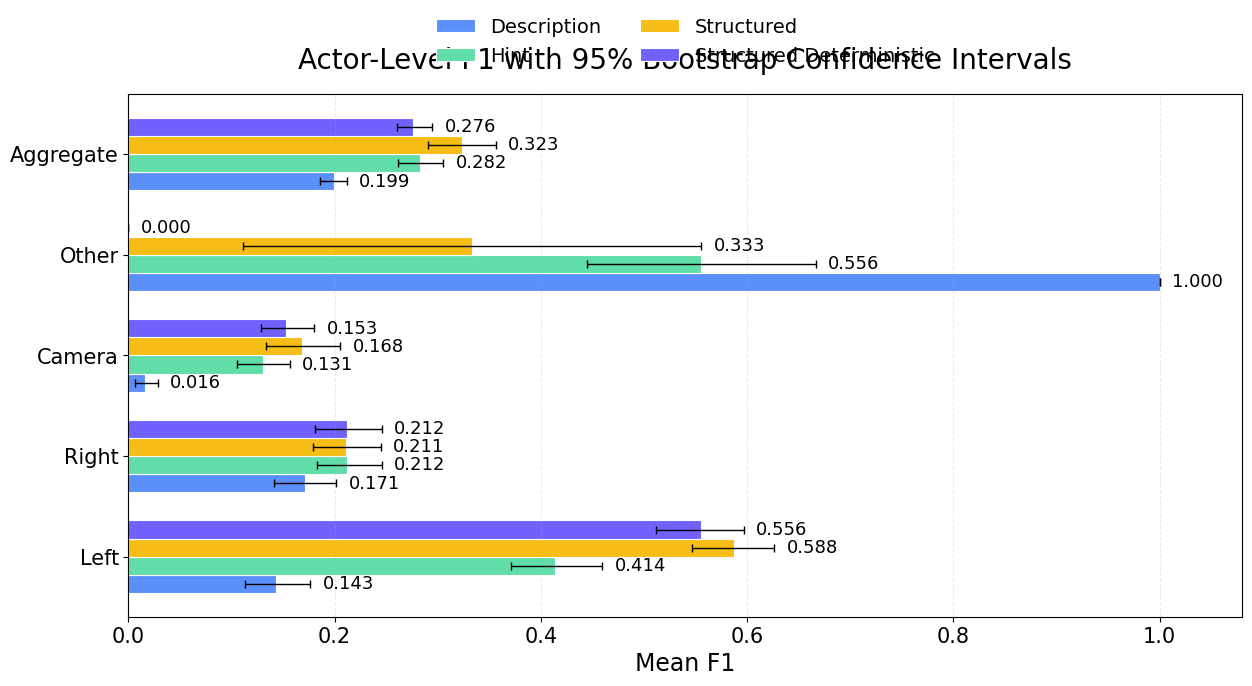

In [6]:
display(Markdown('### Actor-Level F1 Chart'))

plot_columns = ['Left', 'Right', 'Camera', 'Other', 'Aggregate']
plot_actor_map = {
    'Left': 'left',
    'Right': 'right',
    'Camera': 'camera',
    'Other': 'other',
    'Aggregate': None,
}
plot_method_labels = [METHOD_LABELS[m] for m in METHOD_ORDER]
plot_colors = ['#5B8FF9', '#61DDAA', '#F6BD16', '#7262FD']

ci_rows = []
for base_method in METHOD_ORDER:
    for col in plot_columns:
        stats = bootstrap_actor_metric(
            spec_results_map,
            base_method,
            actor=plot_actor_map[col],
            n_boot=1000,
            seed=11,
        )
        ci_rows.append(
            {
                'method_label': METHOD_LABELS[base_method],
                'column': col,
                'mean': stats['mean'],
                'lo': stats['lo'],
                'hi': stats['hi'],
            }
        )

df_ci = pd.DataFrame(ci_rows)

fig, ax = plt.subplots(figsize=(12.8, 7.2))
y = list(range(len(plot_columns)))
bar_width = 0.18
offsets = [-1.5, -0.5, 0.5, 1.5]

for idx, base_method in enumerate(METHOD_ORDER):
    method_label = METHOD_LABELS[base_method]
    sub = df_ci[df_ci['method_label'] == method_label].set_index('column').reindex(plot_columns)
    means = sub['mean'].tolist()
    los = sub['lo'].tolist()
    his = sub['hi'].tolist()
    yerr_lower = [m - lo if m is not None and lo is not None else 0 for m, lo in zip(means, los)]
    yerr_upper = [hi - m if m is not None and hi is not None else 0 for m, hi in zip(means, his)]
    ypos = [yi + offsets[idx] * bar_width for yi in y]
    bars = ax.barh(
        ypos,
        means,
        height=bar_width,
        label=method_label,
        color=plot_colors[idx],
        edgecolor='white',
        linewidth=0.8,
        xerr=[yerr_lower, yerr_upper],
        capsize=3,
        error_kw={'elinewidth': 1, 'capthick': 1},
    )
    for rect, mean, err_hi in zip(bars, means, yerr_upper):
        if mean is None:
            continue
        ax.text(
            mean + err_hi + 0.012,
            rect.get_y() + rect.get_height() / 2,
            f'{mean:.3f}',
            ha='left',
            va='center',
            fontsize=13,
        )

ax.set_yticks(y)
ax.set_yticklabels(plot_columns, fontsize=15)
ax.set_xlabel('Mean F1', fontsize=17)
ax.set_title('Actor-Level F1 with 95% Bootstrap Confidence Intervals', fontsize=20, pad=18)
ax.set_xlim(0, max(df_ci['hi'].max() + 0.08, 1.05))
ax.grid(axis='x', linestyle='--', alpha=0.25)
ax.legend(ncols=2, frameon=False, loc='upper center', bbox_to_anchor=(0.5, 1.18), fontsize=14)
plt.tight_layout()
plt.show()


### Slide-Ready F1 by Granularity

#### Coarse

actor_label,Camera,Left,Right
method_label,,,
Description,0.028880,0.216475,0.276204
Hint,0.163388,0.541375,0.302652
Structured deterministic,0.225185,0.555293,0.338307
Structured LLM extract,0.244915,0.565761,0.337497
Structured LLM extract + tool fix,0.244915,0.565761,0.337497


#### Medium

actor_label,Camera,Left,Right
method_label,,,
Description,0.013007,0.113602,0.205224
Hint,0.119902,0.399547,0.251698
Structured deterministic,0.138928,0.615487,0.250503
Structured LLM extract,0.142761,0.673170,0.249693
Structured LLM extract + tool fix,0.142761,0.673170,0.303426


#### Fine / exact

actor_label,Camera,Left,Right
method_label,,,
Description,0.007055,0.100192,0.032099
Hint,0.108936,0.299884,0.080223
Structured deterministic,0.094889,0.496150,0.047000
Structured LLM extract,0.116306,0.524382,0.045354
Structured LLM extract + tool fix,0.116306,0.524382,0.055583


saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/slide_ready_f1_by_granularity_5way.png
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/slide_ready_f1_by_granularity_5way.pdf


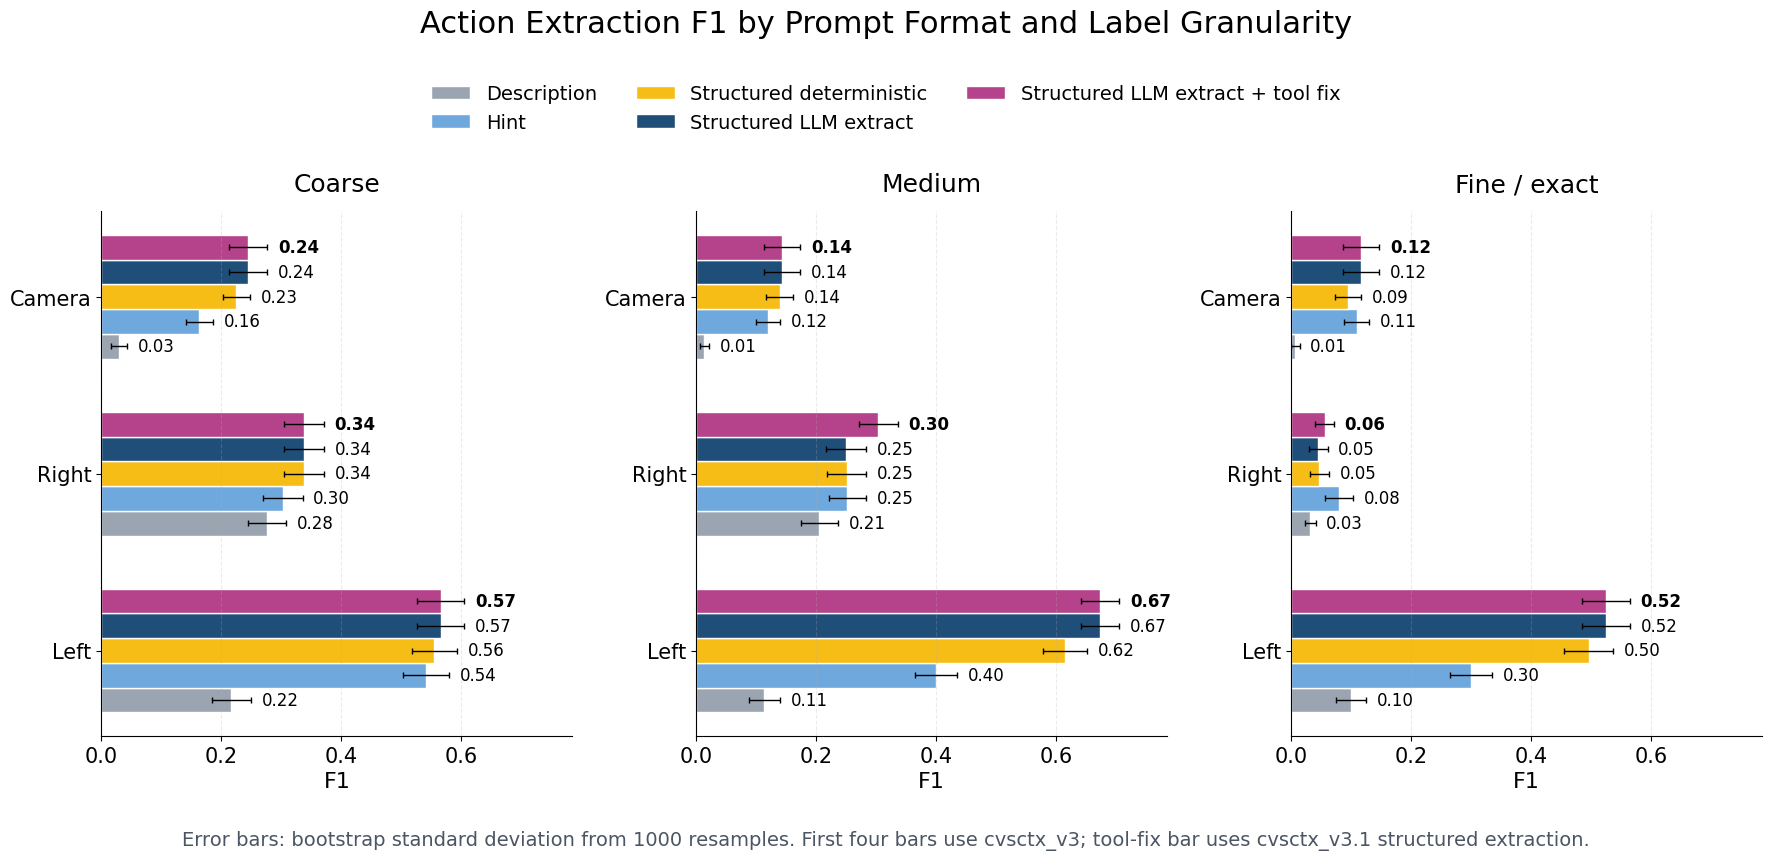

#### Average over coarse, medium, and fine / exact

actor_label,Camera,Left,Right
method_label,,,
Description,0.016314,0.143423,0.171176
Hint,0.130742,0.413602,0.211525
Structured deterministic,0.153000,0.555643,0.211936
Structured LLM extract,0.167994,0.587771,0.210848
Structured LLM extract + tool fix,0.167994,0.587771,0.232169


saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/slide_ready_f1_avg_granularity_5way.png
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/slide_ready_f1_avg_granularity_5way.pdf


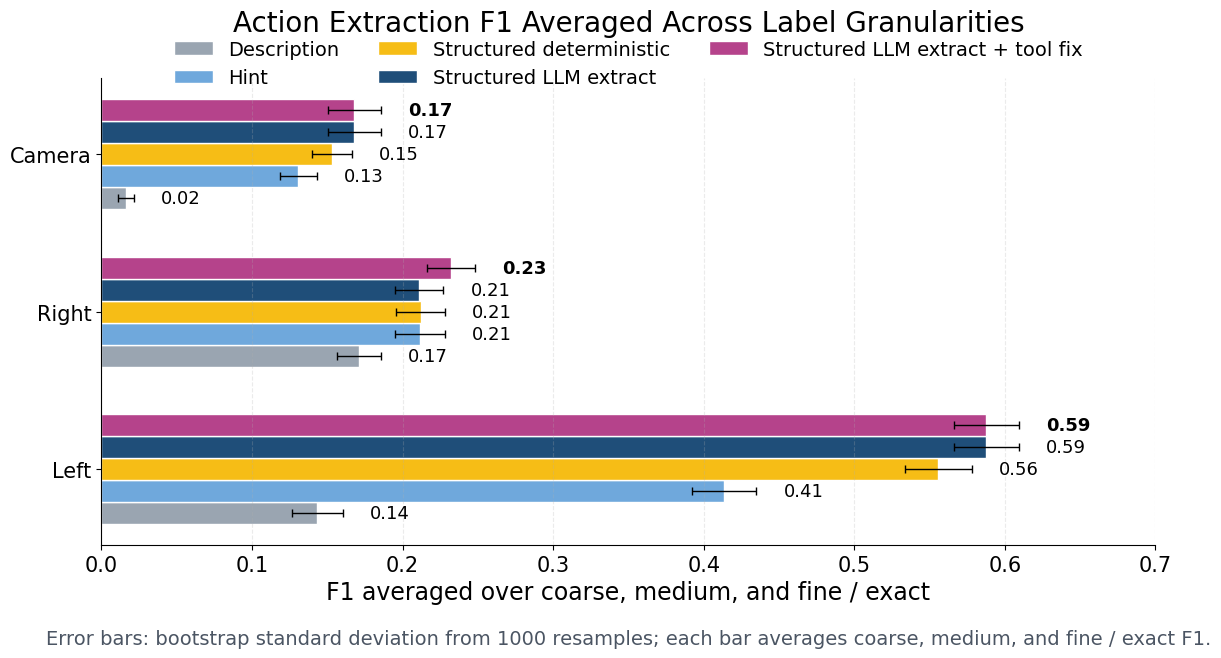

#### Average over granularities at IoU 0.1

actor_label,Camera,Left,Right
method_label,,,
Description,0.033069,0.155045,0.192551
Hint,0.203287,0.442688,0.237708
Structured deterministic,0.197625,0.589116,0.239972
Structured LLM extract,0.224236,0.623746,0.239158
Structured LLM extract + tool fix,0.224236,0.623746,0.262243


#### Average over granularities at IoU 0.25

actor_label,Camera,Left,Right
method_label,,,
Description,0.011905,0.149298,0.181205
Hint,0.118376,0.418120,0.222356
Structured deterministic,0.163102,0.546349,0.214105
Structured LLM extract,0.174985,0.577143,0.215212
Structured LLM extract + tool fix,0.174985,0.577143,0.236532


#### Average over granularities at IoU 0.5

actor_label,Camera,Left,Right
method_label,,,
Description,0.003968,0.125926,0.139771
Hint,0.070563,0.379998,0.174510
Structured deterministic,0.098275,0.531465,0.181732
Structured LLM extract,0.104762,0.562424,0.178174
Structured LLM extract + tool fix,0.104762,0.562424,0.197731


saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/slide_ready_f1_by_iou_threshold_5way.png
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/slide_ready_f1_by_iou_threshold_5way.pdf


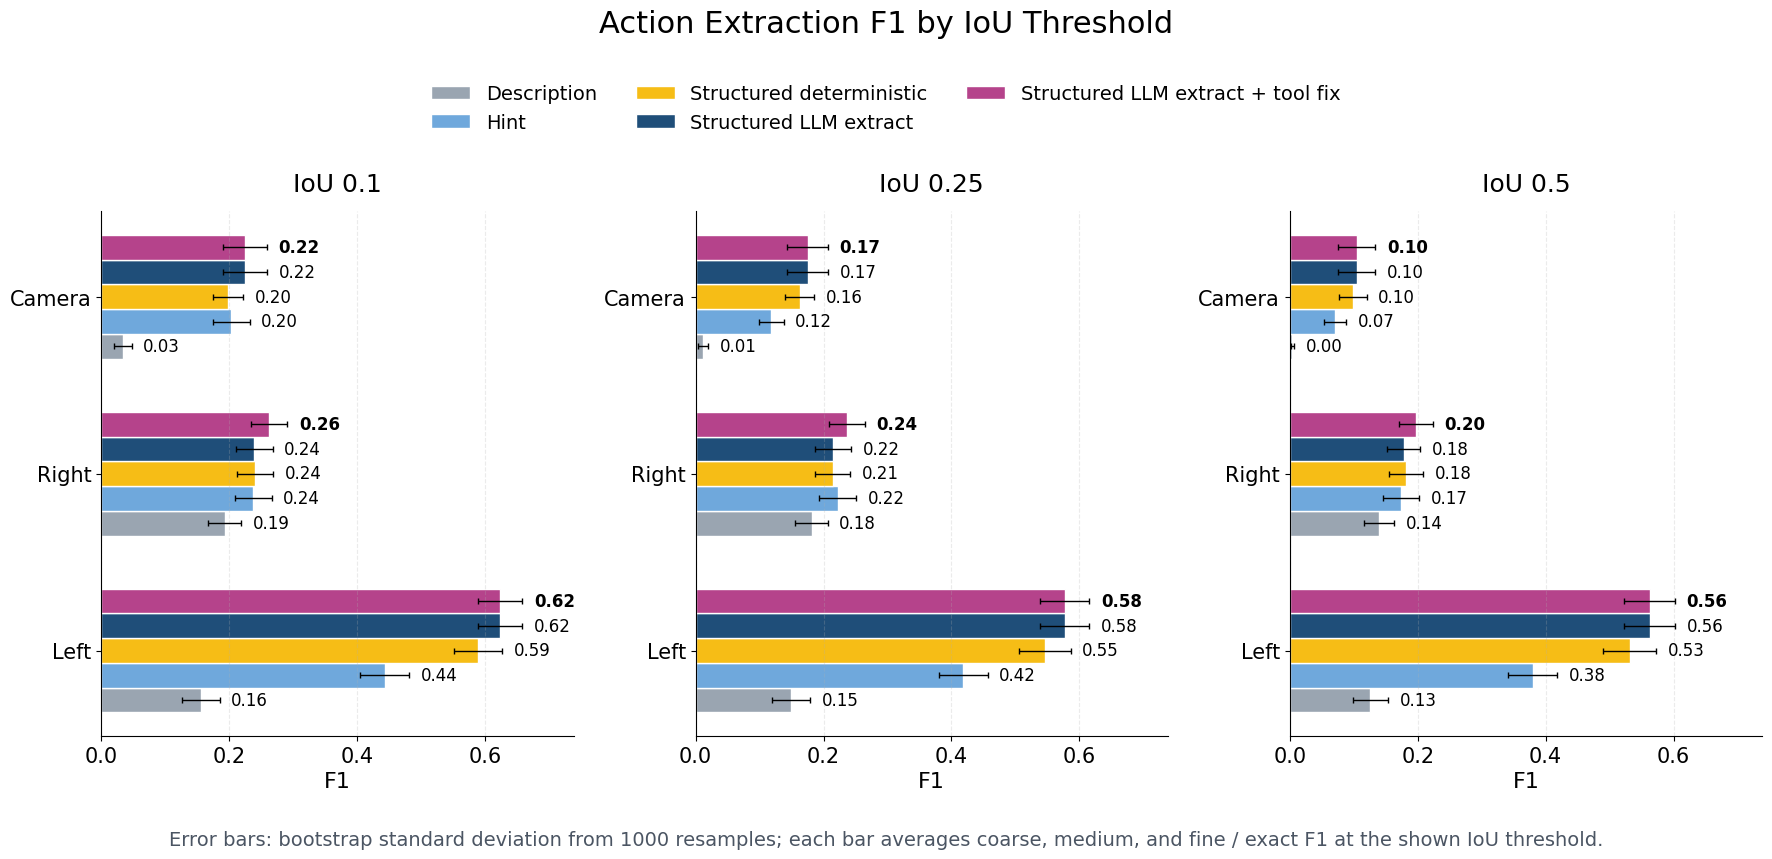

saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/slide_ready_coarse_f1.png
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/slide_ready_coarse_f1.pdf
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/slide_ready_coarse_f1_5way.png
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/slide_ready_coarse_f1_5way.pdf


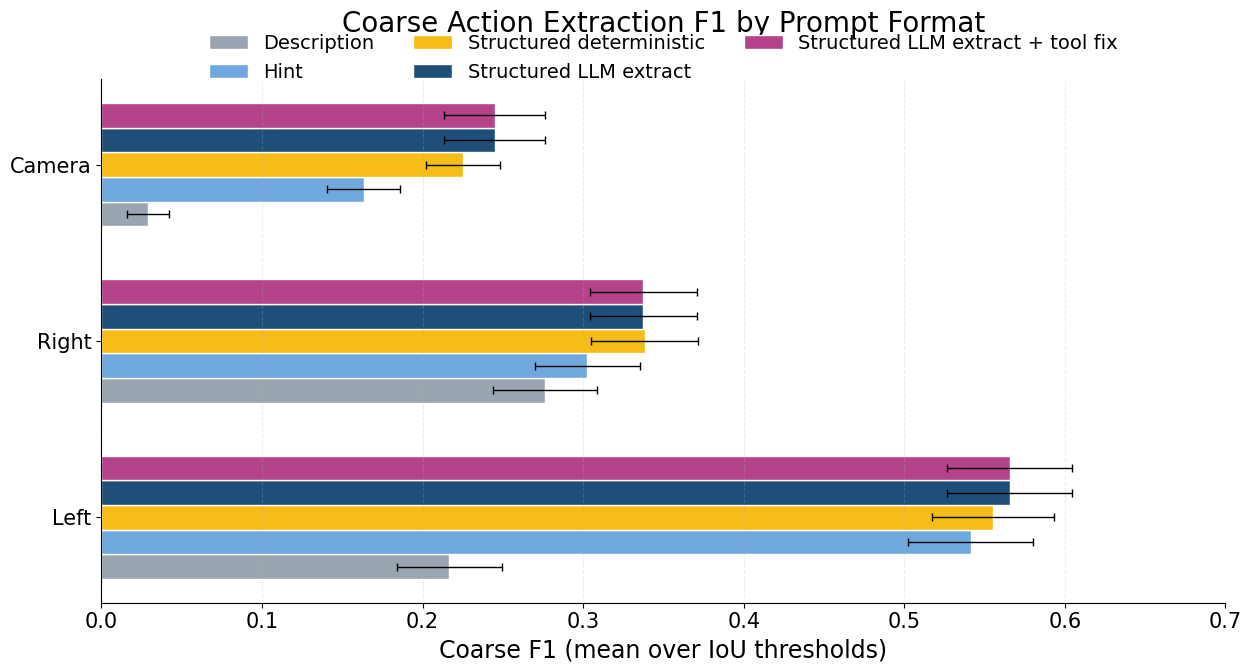

In [7]:
display(Markdown('### Slide-Ready F1 by Granularity'))

slide_entries = [
    {
        'id': 'description',
        'method': 'description_only',
        'method_label': 'Description',
        'results_map': spec_results_map,
    },
    {
        'id': 'hint',
        'method': 'hint_questions',
        'method_label': 'Hint',
        'results_map': spec_results_map,
    },
    {
        'id': 'structured_deterministic',
        'method': 'structured_prediction_deterministic',
        'method_label': 'Structured deterministic',
        'results_map': spec_results_map,
    },
    {
        'id': 'structured_llm_extract',
        'method': 'structured_prediction',
        'method_label': 'Structured LLM extract',
        'results_map': spec_results_map,
    },
    {
        'id': 'structured_llm_extract_tool_fix',
        'method': 'structured_prediction',
        'method_label': 'Structured LLM extract + tool fix',
        'results_map': {
            normalize_method(method): rows
            for method, rows in json.loads(
                (ROOT_DIR / 'notebooks/artifacts/qwen3.5_audit_v11_seg_extract_spec_eval_cvsctx_v3_1/spec_eval_results.json').read_text()
            ).items()
        },
    },
]
slide_actors = ['left', 'right', 'camera']
slide_actor_labels = {'left': 'Left', 'right': 'Right', 'camera': 'Camera'}
slide_granularities = ['coarse', 'medium', 'exact']
slide_granularity_labels = {'coarse': 'Coarse', 'medium': 'Medium', 'exact': 'Fine / exact'}



def bootstrap_actor_granularity_average_std(results_map, method, actor, granularities, n_boot=1000, seed=23):
    method_rows = results_map.get(method, [])
    selected = []
    for granularity in granularities:
        granularity_values = []
        for row in method_rows:
            if row.get('actor') != actor or row.get('granularity') != granularity:
                continue
            values = [float(d['f1']) for d in row.get('details', [])]
            if values:
                granularity_values.append(values)
        if not granularity_values:
            return {'mean': None, 'std': None}
        selected.append(granularity_values)

    def avg(xs):
        return sum(xs) / len(xs) if xs else float('nan')

    observed = avg([avg([avg(values) for values in granularity_values]) for granularity_values in selected])
    rng = random.Random(seed)
    samples = []
    for _ in range(n_boot):
        granularity_means = []
        for granularity_values in selected:
            cell_means = []
            for values in granularity_values:
                resampled = [values[rng.randrange(len(values))] for _ in range(len(values))]
                cell_means.append(avg(resampled))
            granularity_means.append(avg(cell_means))
        samples.append(avg(granularity_means))
    mu = avg(samples)
    var = avg([(x - mu) ** 2 for x in samples])
    return {'mean': observed, 'std': var ** 0.5}

slide_colors = {
    'description': '#9AA5B1',
    'hint': '#6FA8DC',
    'structured_deterministic': '#F6BD16',
    'structured_llm_extract': '#1F4E79',
    'structured_llm_extract_tool_fix': '#B5438B',
}

slide_rows = []
for granularity in slide_granularities:
    for entry in slide_entries:
        for actor in slide_actors:
            stats = bootstrap_actor_granularity_metric(
                entry['results_map'],
                entry['method'],
                actor,
                granularity,
                n_boot=1000,
                seed=17,
            )
            slide_rows.append(
                {
                    'granularity': granularity,
                    'granularity_label': slide_granularity_labels[granularity],
                    'series_id': entry['id'],
                    'method': entry['method'],
                    'method_label': entry['method_label'],
                    'actor': actor,
                    'actor_label': slide_actor_labels[actor],
                    'mean': stats['mean'],
                    'std': stats['std'],
                }
            )

df_slide = pd.DataFrame(slide_rows)
for granularity in slide_granularities:
    display(Markdown(f'#### {slide_granularity_labels[granularity]}'))
    display(
        df_slide[df_slide['granularity'] == granularity]
        .pivot_table(index='method_label', columns='actor_label', values='mean')
        .reindex([entry['method_label'] for entry in slide_entries])
    )

fig, axes = plt.subplots(1, len(slide_granularities), figsize=(18.0, 7.2), sharex=True)
x = list(range(len(slide_actors)))
bar_width = 0.14
offsets = [i - (len(slide_entries) - 1) / 2 for i in range(len(slide_entries))]
ymax = max((df_slide['mean'] + df_slide['std']).max() + 0.08, 0.7)

for ax, granularity in zip(axes, slide_granularities):
    gran_df = df_slide[df_slide['granularity'] == granularity]
    for idx, entry in enumerate(slide_entries):
        sub = gran_df[gran_df['series_id'] == entry['id']].set_index('actor').reindex(slide_actors)
        means = sub['mean'].tolist()
        stds = sub['std'].tolist()
        yerr = [s if pd.notna(s) else 0 for s in stds]
        ypos = [yi + offsets[idx] * bar_width for yi in x]
        bars = ax.barh(
            ypos,
            means,
            height=bar_width,
            label=entry['method_label'],
            color=slide_colors[entry['id']],
            edgecolor='white',
            linewidth=1.0,
            xerr=yerr,
            capsize=2.5,
            error_kw={'elinewidth': 1, 'capthick': 1},
        )
        for bar_idx, (rect, mean) in enumerate(zip(bars, means)):
            if mean is None:
                continue
            ax.text(
                mean + yerr[bar_idx] + 0.018,
                rect.get_y() + rect.get_height() / 2,
                f'{mean:.2f}',
                ha='left',
                va='center',
                fontsize=12,
                fontweight='bold' if entry['id'] == 'structured_llm_extract_tool_fix' else 'normal',
            )
    ax.set_title(slide_granularity_labels[granularity], fontsize=18, pad=14)
    ax.set_yticks(x)
    ax.set_yticklabels([slide_actor_labels[a] for a in slide_actors], fontsize=15)
    ax.set_xlim(0, ymax)
    ax.set_xlabel('F1', fontsize=16)
    ax.grid(axis='x', linestyle='--', alpha=0.25)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncols=3, frameon=False, loc='upper center', bbox_to_anchor=(0.5, 1.04), fontsize=14)
fig.suptitle('Action Extraction F1 by Prompt Format and Label Granularity', fontsize=22, y=1.12)
fig.text(
    0.5,
    -0.02,
    'Error bars: bootstrap standard deviation from 1000 resamples. First four bars use cvsctx_v3; tool-fix bar uses cvsctx_v3.1 structured extraction.',
    ha='center',
    va='top',
    fontsize=14,
    color='#4B5563',
)
plt.tight_layout()
slide_all_png = OUT_DIR / 'slide_ready_f1_by_granularity_5way.png'
slide_all_pdf = OUT_DIR / 'slide_ready_f1_by_granularity_5way.pdf'
fig.savefig(slide_all_png, dpi=300, bbox_inches='tight')
fig.savefig(slide_all_pdf, bbox_inches='tight')
print('saved', slide_all_png)
print('saved', slide_all_pdf)
plt.show()



# Average the three label granularities for a compact slide version.
df_slide_avg = (
    df_slide
    .groupby(['series_id', 'method_label', 'actor', 'actor_label'], as_index=False)
    .agg(mean=('mean', 'mean'))
)

# Bootstrap the average directly so the interval reflects resampling plus averaging over coarse/medium/exact.
avg_rows = []
for entry in slide_entries:
    for actor in slide_actors:
        stats = bootstrap_actor_granularity_average_std(
            entry['results_map'],
            entry['method'],
            actor,
            slide_granularities,
            n_boot=1000,
            seed=23,
        )
        avg_rows.append({
            'series_id': entry['id'],
            'method': entry['method'],
            'method_label': entry['method_label'],
            'actor': actor,
            'actor_label': slide_actor_labels[actor],
            'mean': stats['mean'],
            'std': stats['std'],
        })

df_slide_avg_boot = pd.DataFrame(avg_rows)
display(Markdown('#### Average over coarse, medium, and fine / exact'))
display(
    df_slide_avg_boot
    .pivot_table(index='method_label', columns='actor_label', values='mean')
    .reindex([entry['method_label'] for entry in slide_entries])
)

fig, ax = plt.subplots(figsize=(12.8, 7.0))
x = list(range(len(slide_actors)))
for idx, entry in enumerate(slide_entries):
    sub = df_slide_avg_boot[df_slide_avg_boot['series_id'] == entry['id']].set_index('actor').reindex(slide_actors)
    means = sub['mean'].tolist()
    stds = sub['std'].tolist()
    yerr = [s if pd.notna(s) else 0 for s in stds]
    ypos = [yi + offsets[idx] * bar_width for yi in x]
    bars = ax.barh(
        ypos,
        means,
        height=bar_width,
        label=entry['method_label'],
        color=slide_colors[entry['id']],
        edgecolor='white',
        linewidth=1.0,
        xerr=yerr,
        capsize=3,
        error_kw={'elinewidth': 1, 'capthick': 1},
    )
    for bar_idx, (rect, mean) in enumerate(zip(bars, means)):
        if pd.isna(mean):
            continue
        ax.text(
            mean + yerr[bar_idx] + 0.018,
            rect.get_y() + rect.get_height() / 2,
            f'{mean:.2f}',
            ha='left',
            va='center',
            fontsize=13,
            fontweight='bold' if entry['id'] == 'structured_llm_extract_tool_fix' else 'normal',
        )

ax.set_yticks(x)
ax.set_yticklabels([slide_actor_labels[a] for a in slide_actors], fontsize=15)
ax.set_xlabel('F1 averaged over coarse, medium, and fine / exact', fontsize=17)
ax.set_title('Action Extraction F1 Averaged Across Label Granularities', fontsize=20, pad=34)
ax.set_xlim(0, max((df_slide_avg_boot['mean'] + df_slide_avg_boot['std']).max() + 0.08, 0.7))
ax.grid(axis='x', linestyle='--', alpha=0.25)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(ncols=3, frameon=False, loc='upper center', bbox_to_anchor=(0.5, 1.12), fontsize=14)
ax.text(
    0.5,
    -0.18,
    'Error bars: bootstrap standard deviation from 1000 resamples; each bar averages coarse, medium, and fine / exact F1.',
    transform=ax.transAxes,
    ha='center',
    va='top',
    fontsize=14,
    color='#4B5563',
)
plt.tight_layout()
slide_avg_png = OUT_DIR / 'slide_ready_f1_avg_granularity_5way.png'
slide_avg_pdf = OUT_DIR / 'slide_ready_f1_avg_granularity_5way.pdf'
fig.savefig(slide_avg_png, dpi=300, bbox_inches='tight')
fig.savefig(slide_avg_pdf, bbox_inches='tight')
print('saved', slide_avg_png)
print('saved', slide_avg_pdf)
plt.show()



# Break out F1 by IoU threshold, averaging over coarse/medium/exact for each actor.
def bootstrap_actor_iou_average_std(results_map, method, actor, iou, granularities, n_boot=1000, seed=31):
    method_rows = results_map.get(method, [])
    selected = []
    for granularity in granularities:
        matching = []
        for row in method_rows:
            if row.get('actor') != actor or row.get('granularity') != granularity:
                continue
            if abs(float(row.get('iou')) - float(iou)) > 1e-9:
                continue
            values = [float(d['f1']) for d in row.get('details', [])]
            if values:
                matching.append(values)
        if not matching:
            return {'mean': None, 'std': None}
        selected.append(matching)

    def avg(xs):
        return sum(xs) / len(xs) if xs else float('nan')

    observed = avg([avg([avg(values) for values in granularity_values]) for granularity_values in selected])
    rng = random.Random(seed)
    samples = []
    for _ in range(n_boot):
        granularity_means = []
        for granularity_values in selected:
            cell_means = []
            for values in granularity_values:
                n = len(values)
                cell_means.append(avg([values[rng.randrange(n)] for _ in range(n)]))
            granularity_means.append(avg(cell_means))
        samples.append(avg(granularity_means))
    mu = avg(samples)
    var = avg([(x - mu) ** 2 for x in samples])
    return {'mean': observed, 'std': var ** 0.5}

slide_ious = sorted({float(row.get('iou')) for entry in slide_entries for rows in [entry['results_map'].get(entry['method'], [])] for row in rows if row.get('actor') in slide_actors and row.get('granularity') in slide_granularities})
iou_rows = []
for iou in slide_ious:
    for entry in slide_entries:
        for actor in slide_actors:
            stats = bootstrap_actor_iou_average_std(
                entry['results_map'],
                entry['method'],
                actor,
                iou,
                slide_granularities,
                n_boot=1000,
                seed=31,
            )
            iou_rows.append({
                'iou': iou,
                'series_id': entry['id'],
                'method': entry['method'],
                'method_label': entry['method_label'],
                'actor': actor,
                'actor_label': slide_actor_labels[actor],
                'mean': stats['mean'],
                'std': stats['std'],
            })

df_slide_iou = pd.DataFrame(iou_rows)
for iou in slide_ious:
    display(Markdown(f'#### Average over granularities at IoU {iou:g}'))
    display(
        df_slide_iou[df_slide_iou['iou'] == iou]
        .pivot_table(index='method_label', columns='actor_label', values='mean')
        .reindex([entry['method_label'] for entry in slide_entries])
    )

fig, axes = plt.subplots(1, len(slide_ious), figsize=(18.0, 7.2), sharex=True)
if len(slide_ious) == 1:
    axes = [axes]
ymax = max((df_slide_iou['mean'] + df_slide_iou['std']).max() + 0.08, 0.7)
for ax, iou in zip(axes, slide_ious):
    iou_df = df_slide_iou[df_slide_iou['iou'] == iou]
    for idx, entry in enumerate(slide_entries):
        sub = iou_df[iou_df['series_id'] == entry['id']].set_index('actor').reindex(slide_actors)
        means = sub['mean'].tolist()
        stds = sub['std'].tolist()
        yerr = [v if pd.notna(v) else 0 for v in stds]
        ypos = [yi + offsets[idx] * bar_width for yi in x]
        bars = ax.barh(
            ypos,
            means,
            height=bar_width,
            label=entry['method_label'],
            color=slide_colors[entry['id']],
            edgecolor='white',
            linewidth=1.0,
            xerr=yerr,
            capsize=2.5,
            error_kw={'elinewidth': 1, 'capthick': 1},
        )
        for bar_idx, (rect, mean) in enumerate(zip(bars, means)):
            if pd.isna(mean):
                continue
            ax.text(
                mean + yerr[bar_idx] + 0.018,
                rect.get_y() + rect.get_height() / 2,
                f'{mean:.2f}',
                ha='left',
                va='center',
                fontsize=12,
                fontweight='bold' if entry['id'] == 'structured_llm_extract_tool_fix' else 'normal',
            )
    ax.set_title(f'IoU {iou:g}', fontsize=18, pad=14)
    ax.set_yticks(x)
    ax.set_yticklabels([slide_actor_labels[a] for a in slide_actors], fontsize=15)
    ax.set_xlim(0, ymax)
    ax.set_xlabel('F1', fontsize=16)
    ax.grid(axis='x', linestyle='--', alpha=0.25)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncols=3, frameon=False, loc='upper center', bbox_to_anchor=(0.5, 1.04), fontsize=14)
fig.suptitle('Action Extraction F1 by IoU Threshold', fontsize=22, y=1.12)
fig.text(
    0.5,
    -0.02,
    'Error bars: bootstrap standard deviation from 1000 resamples; each bar averages coarse, medium, and fine / exact F1 at the shown IoU threshold.',
    ha='center',
    va='top',
    fontsize=14,
    color='#4B5563',
)
plt.tight_layout()
slide_iou_png = OUT_DIR / 'slide_ready_f1_by_iou_threshold_5way.png'
slide_iou_pdf = OUT_DIR / 'slide_ready_f1_by_iou_threshold_5way.pdf'
fig.savefig(slide_iou_png, dpi=300, bbox_inches='tight')
fig.savefig(slide_iou_pdf, bbox_inches='tight')
print('saved', slide_iou_png)
print('saved', slide_iou_pdf)
plt.show()

# Keep the historical coarse-only filenames refreshed for existing slides.
coarse_df = df_slide[df_slide['granularity'] == 'coarse']
fig, ax = plt.subplots(figsize=(12.8, 7.0))
for idx, entry in enumerate(slide_entries):
    sub = coarse_df[coarse_df['series_id'] == entry['id']].set_index('actor').reindex(slide_actors)
    means = sub['mean'].tolist()
    stds = sub['std'].tolist()
    yerr = [s if pd.notna(s) else 0 for s in stds]
    ypos = [yi + offsets[idx] * bar_width for yi in x]
    ax.barh(
        ypos,
        means,
        height=bar_width,
        label=entry['method_label'],
        color=slide_colors[entry['id']],
        edgecolor='white',
        linewidth=1.0,
        xerr=yerr,
        capsize=3,
        error_kw={'elinewidth': 1, 'capthick': 1},
    )
ax.set_yticks(x)
ax.set_yticklabels([slide_actor_labels[a] for a in slide_actors], fontsize=15)
ax.set_xlabel('Coarse F1 (mean over IoU thresholds)', fontsize=17)
ax.set_title('Coarse Action Extraction F1 by Prompt Format', fontsize=20, pad=34)
ax.set_xlim(0, max((coarse_df['mean'] + coarse_df['std']).max() + 0.08, 0.7))
ax.grid(axis='x', linestyle='--', alpha=0.25)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(ncols=3, frameon=False, loc='upper center', bbox_to_anchor=(0.5, 1.12), fontsize=14)
plt.tight_layout()
slide_png = OUT_DIR / 'slide_ready_coarse_f1.png'
slide_pdf = OUT_DIR / 'slide_ready_coarse_f1.pdf'
slide_5way_png = OUT_DIR / 'slide_ready_coarse_f1_5way.png'
slide_5way_pdf = OUT_DIR / 'slide_ready_coarse_f1_5way.pdf'
fig.savefig(slide_png, dpi=300, bbox_inches='tight')
fig.savefig(slide_pdf, bbox_inches='tight')
fig.savefig(slide_5way_png, dpi=300, bbox_inches='tight')
fig.savefig(slide_5way_pdf, bbox_inches='tight')
print('saved', slide_png)
print('saved', slide_pdf)
print('saved', slide_5way_png)
print('saved', slide_5way_pdf)
plt.show()

### 3x3 Actor x Granularity Breakdown

Each panel compares the same five data-generation/extraction methods for one actor and one label granularity. Values are F1 averaged over available IoU thresholds; error bars are bootstrap standard deviations from the existing `df_slide` computation.

method_label                   Description      Hint  \
actor_label granularity_label                          
Left        Coarse                0.216475  0.541375   
            Medium                0.113602  0.399547   
            Fine / exact          0.100192  0.299884   
Right       Coarse                0.276204  0.302652   
            Medium                0.205224  0.251698   
            Fine / exact          0.032099  0.080223   
Camera      Coarse                0.028880  0.163388   
            Medium                0.013007  0.119902   
            Fine / exact          0.007055  0.108936   

method_label                   Structured deterministic  \
actor_label granularity_label                             
Left        Coarse                             0.555293   
            Medium                             0.615487   
            Fine / exact                       0.496150   
Right       Coarse                             0.338307   
            Medium                             0.250503   
            Fine / exact                       0.047000   
Camera      Coarse                             0.225185   
            Medium                             0.138928   
            Fine / exact                       0.094889   

method_label                   Structured LLM extract  \
actor_label granularity_label                           
Left        Coarse                           0.565761   
            Medium                           0.673170   
            Fine / exact                     0.524382   
Right       Coarse                           0.337497   
            Medium                           0.249693   
            Fine / exact                     0.045354   
Camera      Coarse                           0.244915   
            Medium                           0.142761   
            Fine / exact                     0.116306   

method_label                   Structured LLM extract + tool fix  
actor_label granularity_label                                     
Left        Coarse                                      0.565761  
            Medium                                      0.673170  
            Fine / exact                                0.524382  
Right       Coarse                                      0.337497  
            Medium                                      0.303426  
            Fine / exact                                0.055583  
Camera      Coarse                                      0.244915  
            Medium                                      0.142761  
            Fine / exact                                0.116306

saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/slide_ready_f1_actor_granularity_grid_5way.png
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/slide_ready_f1_actor_granularity_grid_5way.pdf


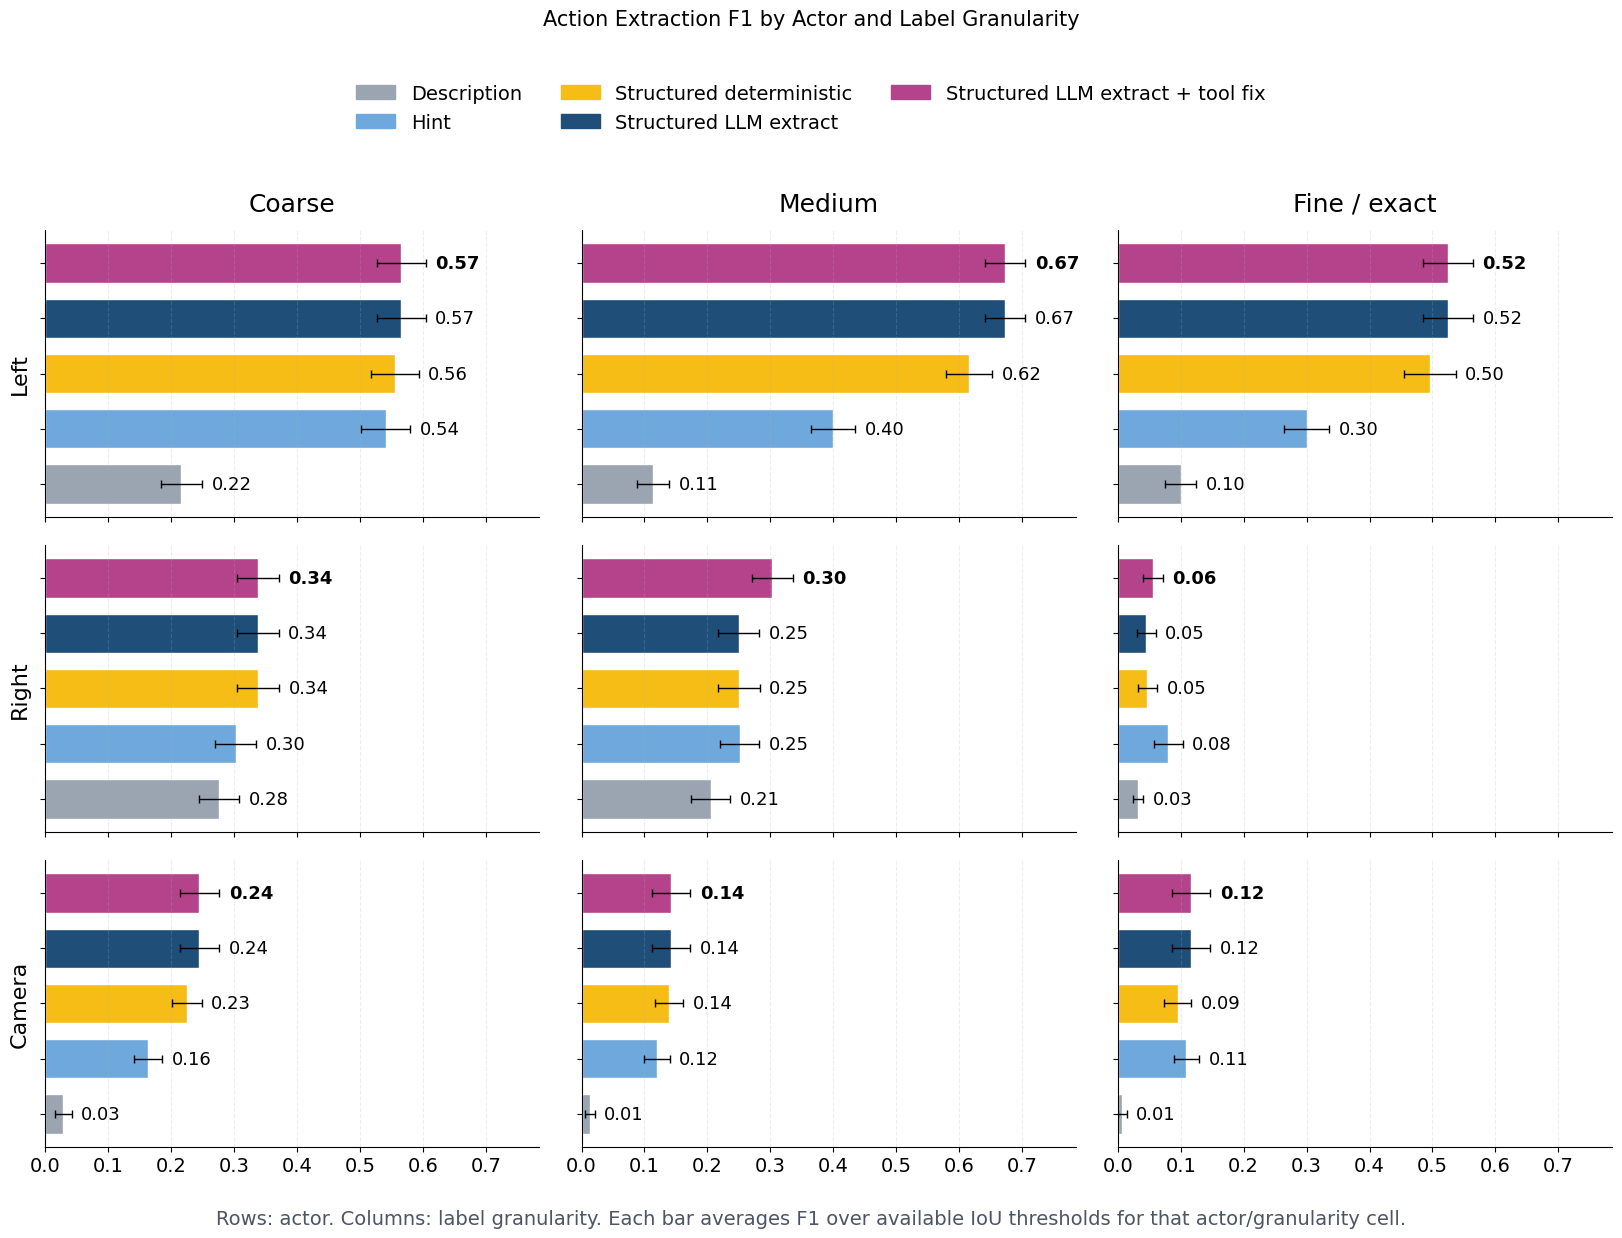

In [8]:
display(Markdown('### 3x3 Actor x Granularity Breakdown'))

display(Markdown('Each panel compares the same five data-generation/extraction methods for one actor and one label granularity. Values are F1 averaged over available IoU thresholds; error bars are bootstrap standard deviations from the existing `df_slide` computation.'))

grid_table = (
    df_slide
    .pivot_table(index=['actor_label', 'granularity_label'], columns='method_label', values='mean')
    .reindex(
        pd.MultiIndex.from_product(
            [[slide_actor_labels[a] for a in slide_actors], [slide_granularity_labels[g] for g in slide_granularities]],
            names=['actor_label', 'granularity_label'],
        )
    )
    .reindex(columns=[entry['method_label'] for entry in slide_entries])
)
display(grid_table)

grid_actor_order = slide_actors
grid_granularity_order = slide_granularities
fig, axes = plt.subplots(
    len(grid_actor_order),
    len(grid_granularity_order),
    figsize=(16.5, 11.5),
    sharex=True,
)
method_x = list(range(len(slide_entries)))
ymax = max((df_slide['mean'] + df_slide['std']).max() + 0.08, 0.7)

for row_idx, actor in enumerate(grid_actor_order):
    for col_idx, granularity in enumerate(grid_granularity_order):
        ax = axes[row_idx][col_idx]
        cell_df = (
            df_slide[
                (df_slide['actor'] == actor)
                & (df_slide['granularity'] == granularity)
            ]
            .set_index('series_id')
            .reindex([entry['id'] for entry in slide_entries])
        )
        means = cell_df['mean'].tolist()
        stds = [v if pd.notna(v) else 0 for v in cell_df['std'].tolist()]
        colors = [slide_colors[entry['id']] for entry in slide_entries]
        bars = ax.barh(
            method_x,
            means,
            height=0.72,
            color=colors,
            edgecolor='white',
            linewidth=1.0,
            xerr=stds,
            capsize=3,
            error_kw={'elinewidth': 1, 'capthick': 1},
        )
        for bar_idx, (rect, mean) in enumerate(zip(bars, means)):
            if pd.isna(mean):
                continue
            ax.text(
                mean + stds[bar_idx] + 0.015,
                rect.get_y() + rect.get_height() / 2,
                f'{mean:.2f}',
                ha='left',
                va='center',
                fontsize=13,
                fontweight='bold' if cell_df.index[bar_idx] == 'structured_llm_extract_tool_fix' else 'normal',
            )
        if row_idx == 0:
            ax.set_title(slide_granularity_labels[granularity], fontsize=18, pad=14)
        if col_idx == 0:
            ax.set_ylabel(slide_actor_labels[actor], fontsize=16)
        ax.set_xlim(0, ymax)
        ax.set_yticks(method_x)
        ax.set_yticklabels([])
        ax.tick_params(axis='x', labelsize=14)
        ax.grid(axis='x', linestyle='--', alpha=0.22)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

legend_handles = [
    plt.Rectangle((0, 0), 1, 1, color=slide_colors[entry['id']])
    for entry in slide_entries
]
legend_labels = [entry['method_label'] for entry in slide_entries]
fig.legend(
    legend_handles,
    legend_labels,
    ncols=3,
    frameon=False,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.02),
    fontsize=14,
)
fig.suptitle('Action Extraction F1 by Actor and Label Granularity', fontsize=15, y=1.07)
fig.text(
    0.5,
    0.01,
    'Rows: actor. Columns: label granularity. Each bar averages F1 over available IoU thresholds for that actor/granularity cell.',
    ha='center',
    va='bottom',
    fontsize=14,
    color='#4B5563',
)
plt.tight_layout(rect=[0, 0.035, 1, 0.97])
grid_png = OUT_DIR / 'slide_ready_f1_actor_granularity_grid_5way.png'
grid_pdf = OUT_DIR / 'slide_ready_f1_actor_granularity_grid_5way.pdf'
fig.savefig(grid_png, dpi=300, bbox_inches='tight')
fig.savefig(grid_pdf, bbox_inches='tight')
print('saved', grid_png)
print('saved', grid_pdf)
plt.show()



### Validation-only 3x3 Actor x Granularity F1 Breakdown

Validation-only 3x3 grid uses `10` videos from seed `20260610`.

method_label                   Description      Hint  \
actor_label granularity_label                          
Left        Coarse                0.254444  0.665370   
            Medium                0.065556  0.378148   
            Fine / exact          0.048889  0.313704   
Right       Coarse                0.285891  0.282301   
            Medium                0.219753  0.218329   
            Fine / exact          0.018519  0.015873   
Camera      Coarse                0.000000  0.254762   
            Medium                0.000000  0.185714   
            Fine / exact          0.000000  0.157143   

method_label                   Structured deterministic  \
actor_label granularity_label                             
Left        Coarse                             0.674141   
            Medium                             0.692525   
            Fine / exact                       0.615960   
Right       Coarse                             0.335265   
            Medium                             0.279789   
            Fine / exact                       0.074074   
Camera      Coarse                             0.239599   
            Medium                             0.153885   
            Fine / exact                       0.100251   

method_label                   Structured LLM extract  \
actor_label granularity_label                           
Left        Coarse                           0.714444   
            Medium                           0.717222   
            Fine / exact                     0.644444   
Right       Coarse                           0.325429   
            Medium                           0.269954   
            Fine / exact                     0.074074   
Camera      Coarse                           0.345918   
            Medium                           0.253061   
            Fine / exact                     0.178231   

method_label                   Structured LLM extract + tool fix  
actor_label granularity_label                                     
Left        Coarse                                      0.714444  
            Medium                                      0.717222  
            Fine / exact                                0.644444  
Right       Coarse                                      0.325429  
            Medium                                      0.294645  
            Fine / exact                                0.074074  
Camera      Coarse                                      0.345918  
            Medium                                      0.253061  
            Fine / exact                                0.178231

saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/validation_slide_ready_f1_actor_granularity_grid_5way_seed20260610.csv
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/validation_slide_ready_f1_actor_granularity_grid_5way_seed20260610.png
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/validation_slide_ready_f1_actor_granularity_grid_5way_seed20260610.pdf


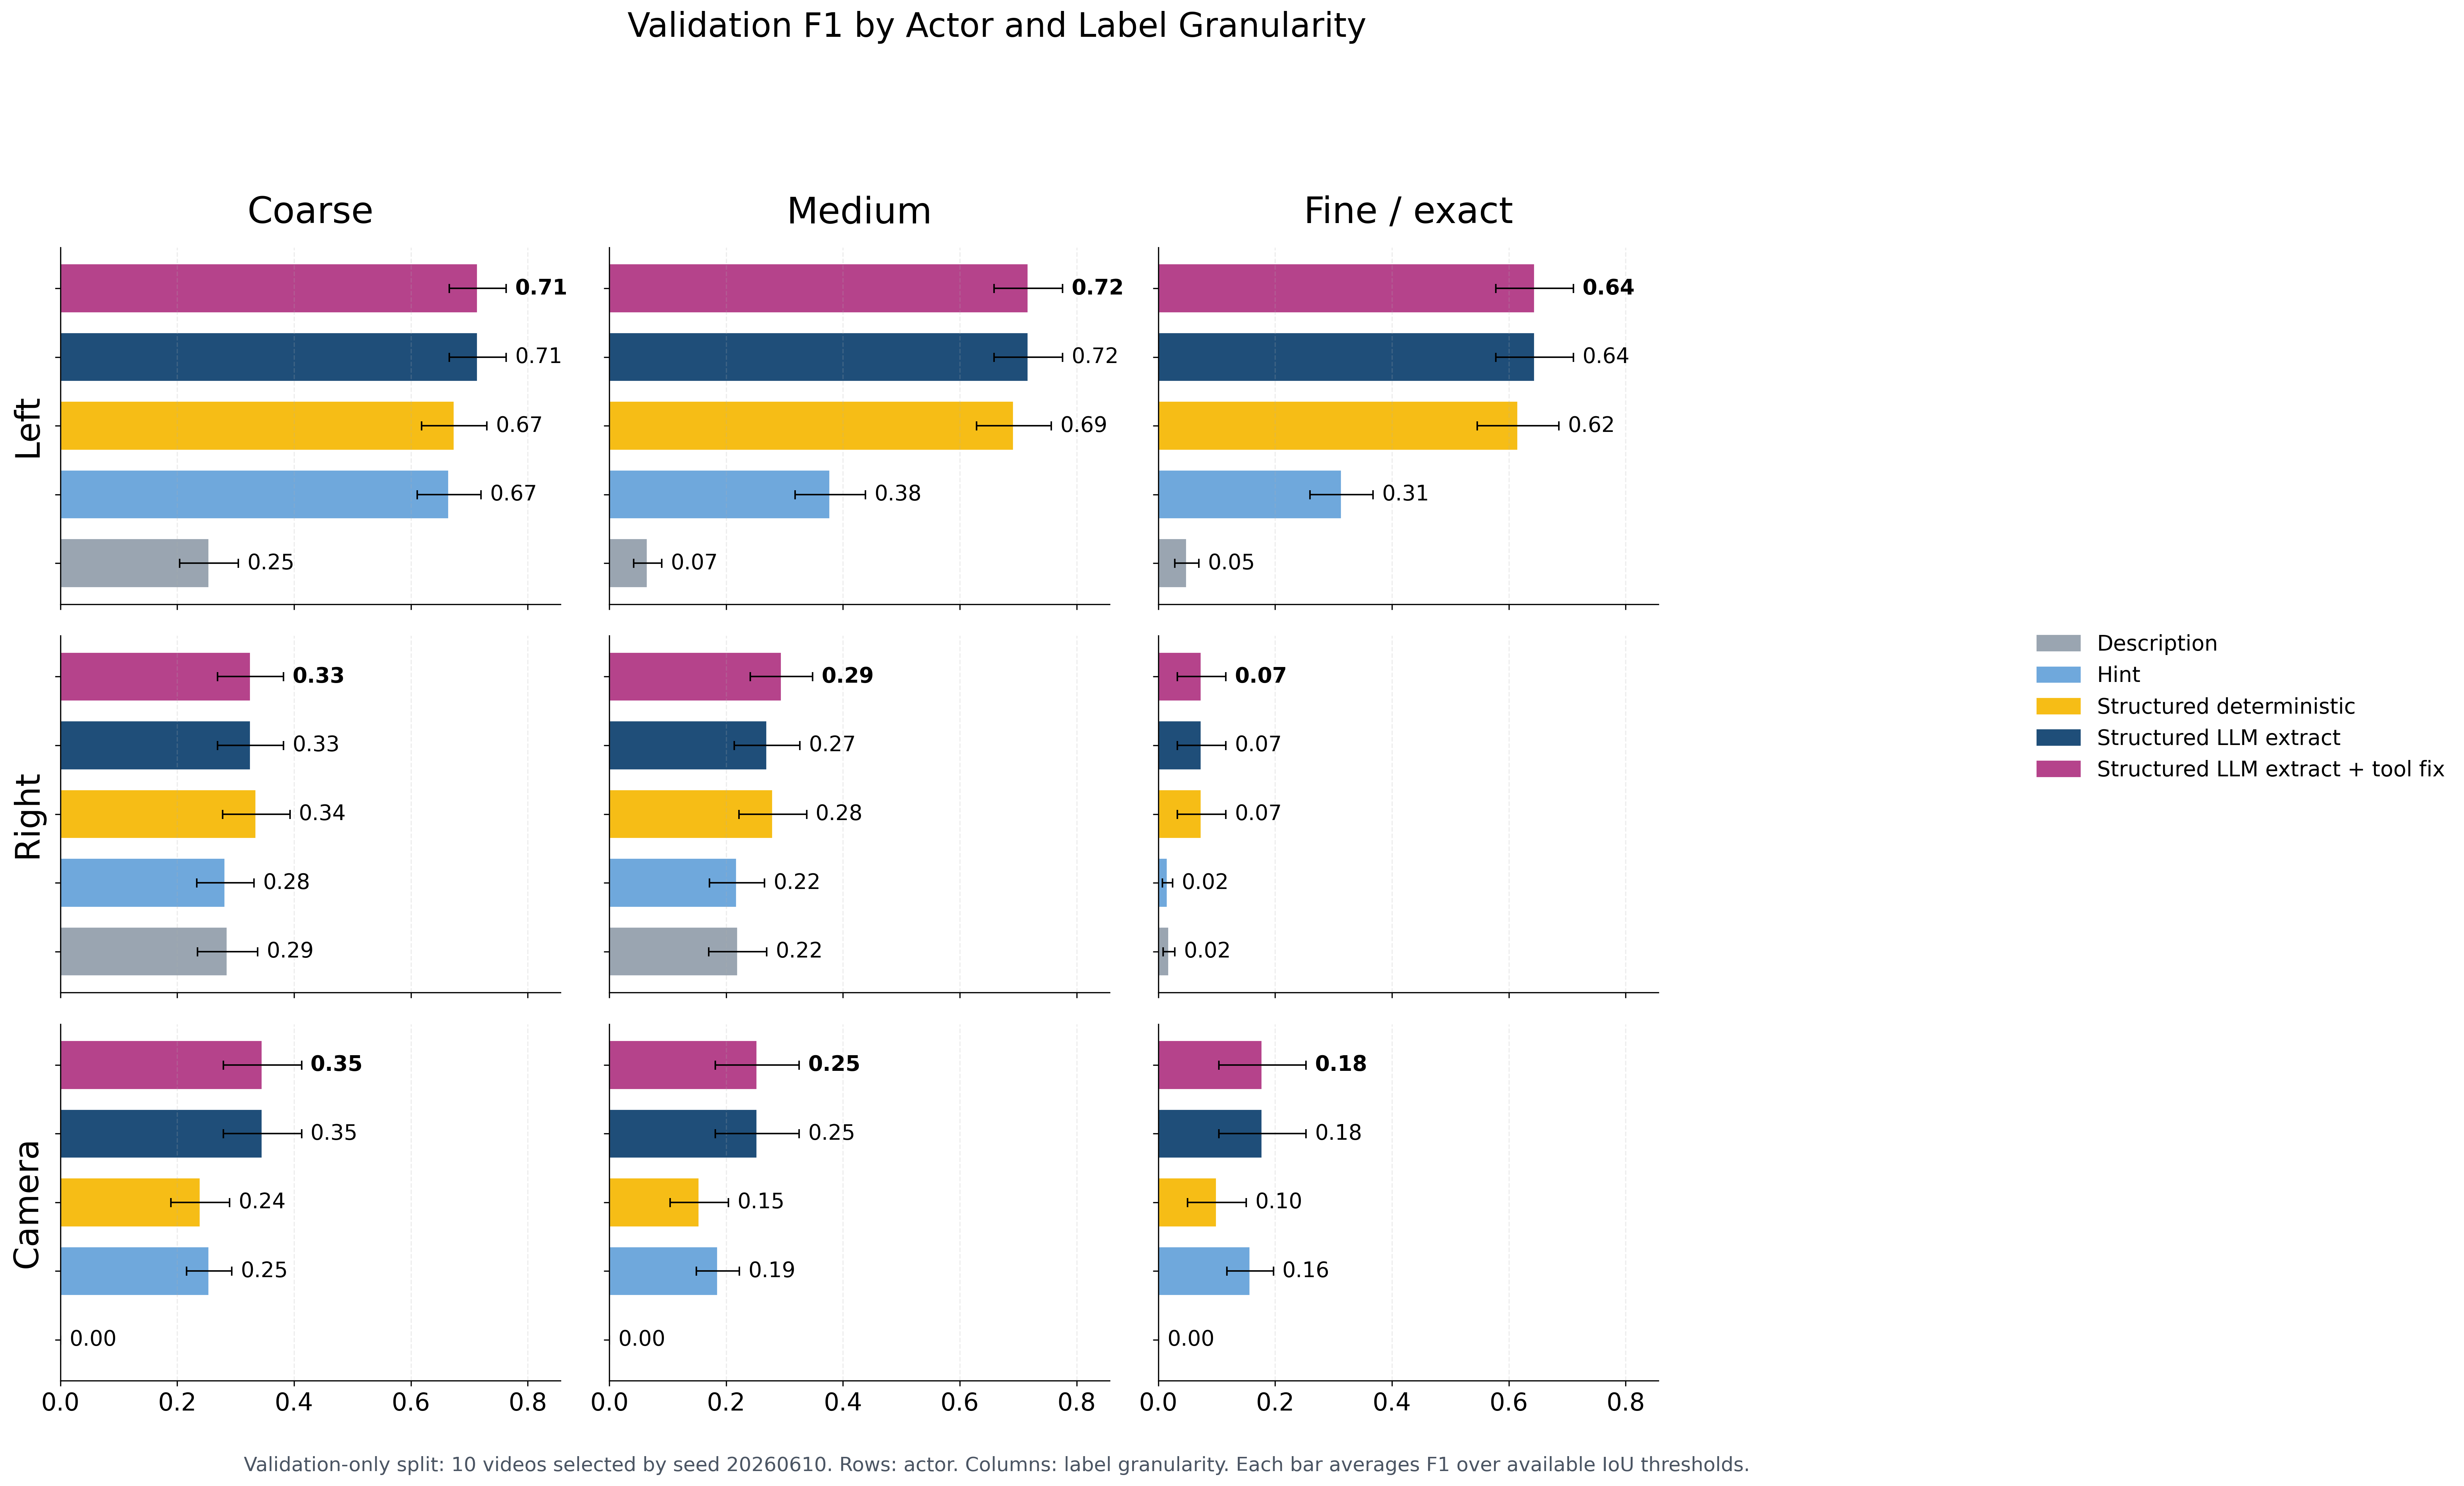

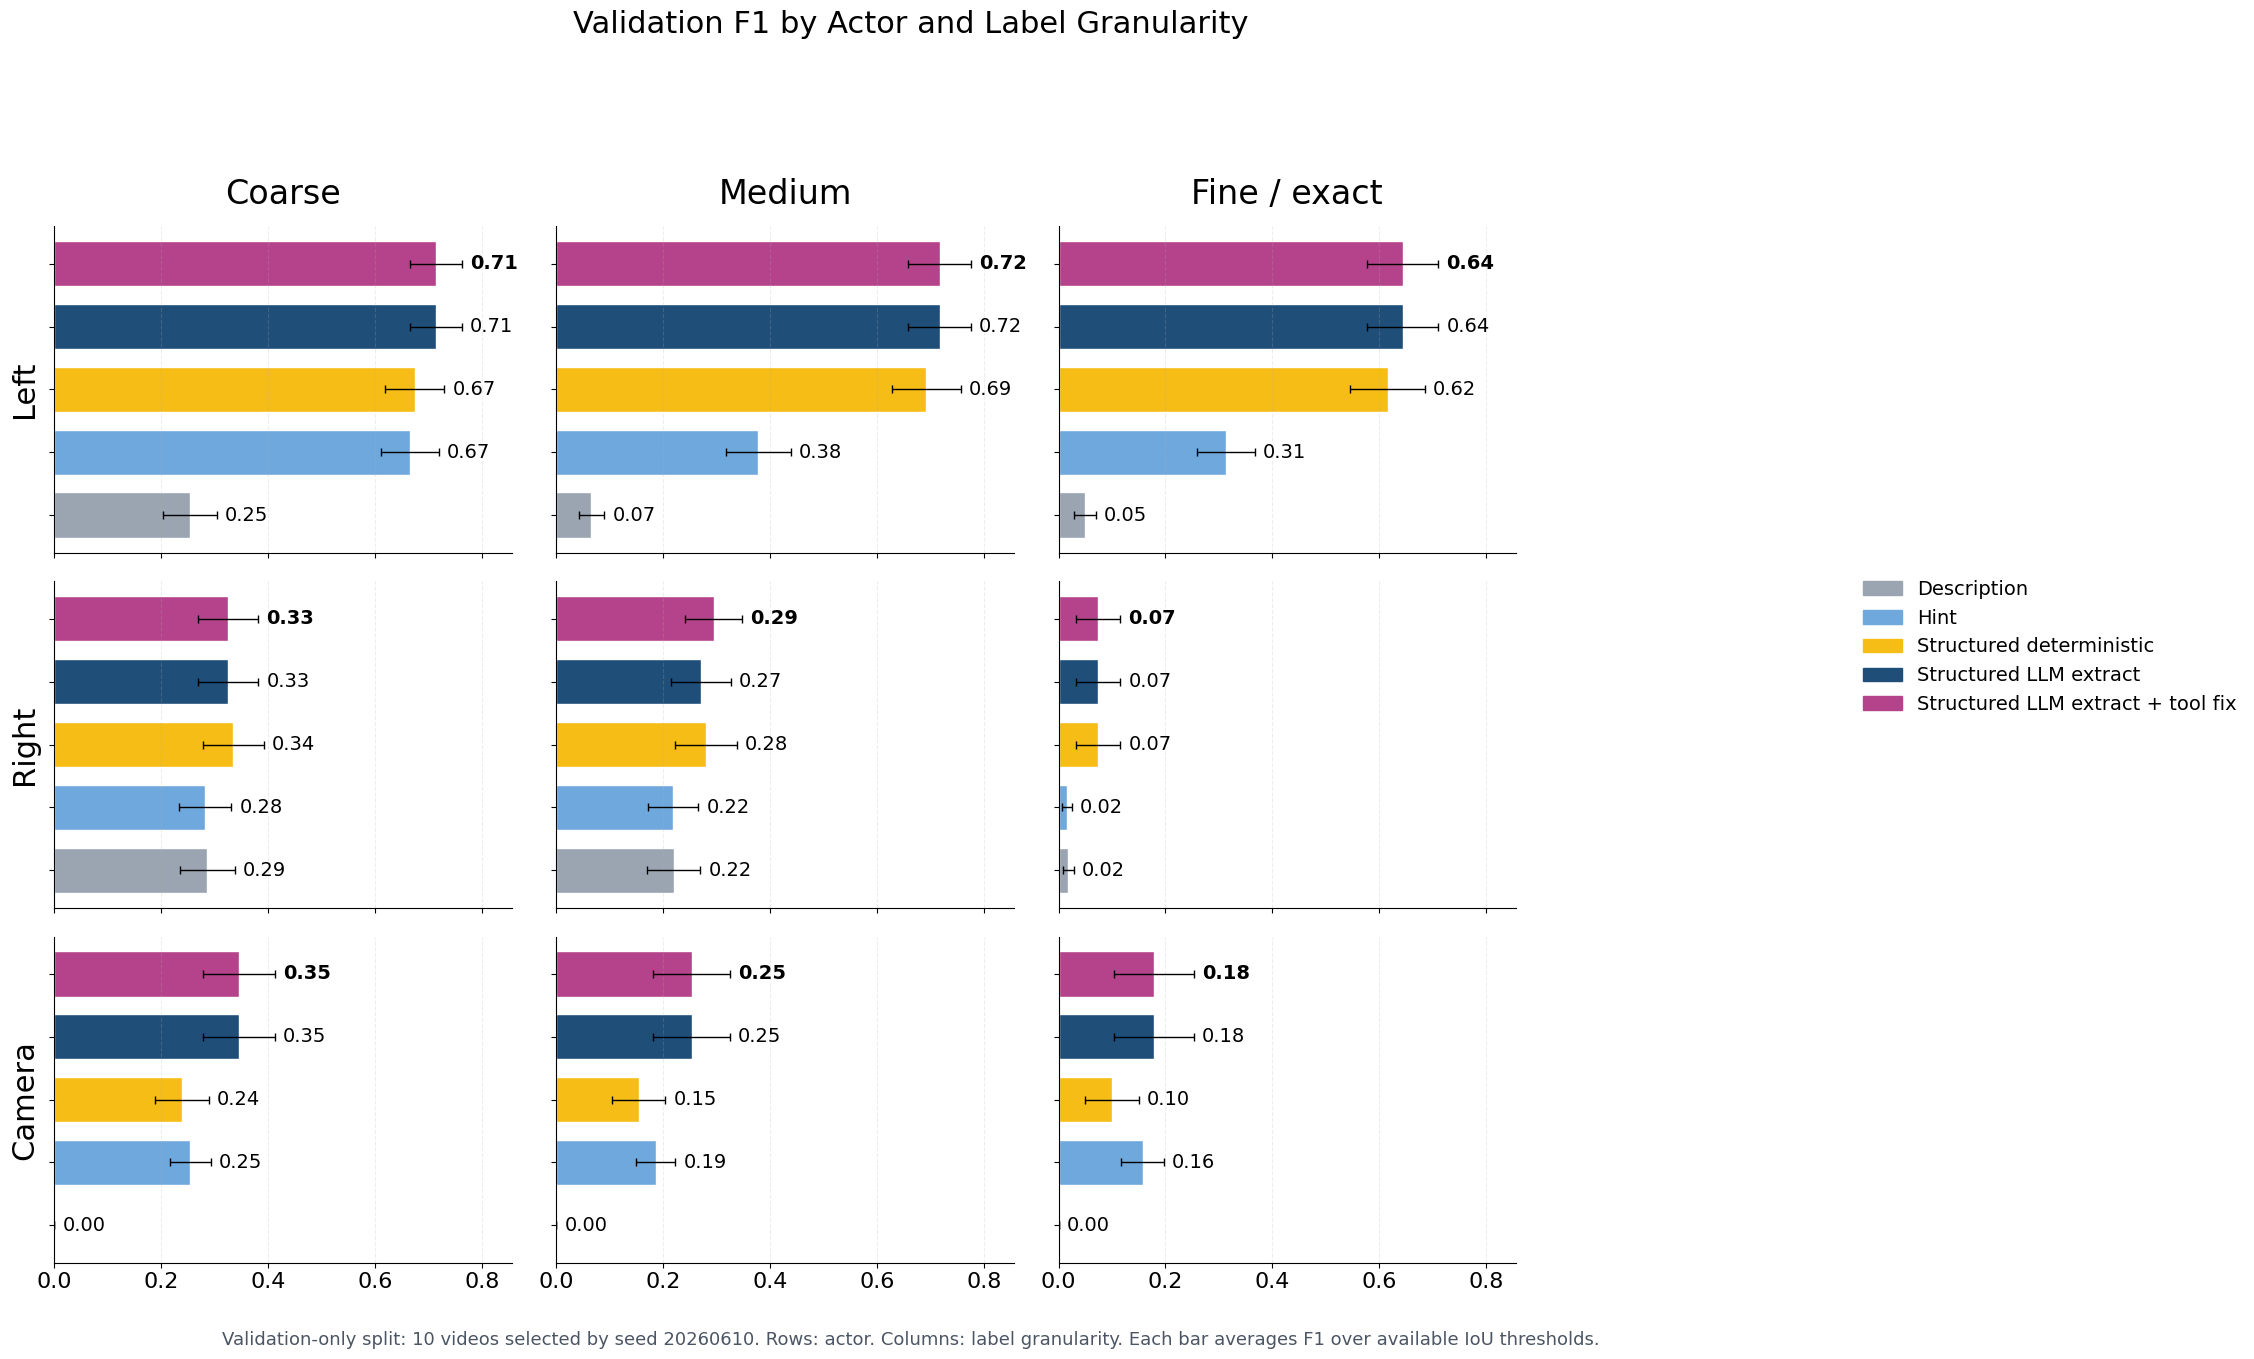

In [9]:
display(Markdown('### Validation-only 3x3 Actor x Granularity F1 Breakdown'))

# Validation-only 3x3 actor/granularity F1 grid using the same seed split as the final section.
# This is the validation-data counterpart to slide_ready_f1_actor_granularity_grid_5way.png.
VALIDATION_GRID_SEED = 20260610
validation_grid_rng = random.Random(VALIDATION_GRID_SEED)
validation_grid_entries = [
    {
        'id': 'description',
        'method': 'description_only',
        'method_label': 'Description',
        'results_map': spec_results_map,
    },
    {
        'id': 'hint',
        'method': 'hint_questions',
        'method_label': 'Hint',
        'results_map': spec_results_map,
    },
    {
        'id': 'structured_deterministic',
        'method': 'structured_prediction_deterministic',
        'method_label': 'Structured deterministic',
        'results_map': spec_results_map,
    },
    {
        'id': 'structured_llm_extract',
        'method': 'structured_prediction',
        'method_label': 'Structured LLM extract',
        'results_map': spec_results_map,
    },
    {
        'id': 'structured_llm_extract_tool_fix',
        'method': 'structured_prediction',
        'method_label': 'Structured LLM extract + tool fix',
        'results_map': {
            normalize_method(method): rows
            for method, rows in json.loads(
                (ROOT_DIR / 'notebooks/artifacts/qwen3.5_audit_v11_seg_extract_spec_eval_cvsctx_v3_1/spec_eval_results.json').read_text()
            ).items()
        },
    },
]
validation_grid_actors = ['left', 'right', 'camera']
validation_grid_granularities = ['coarse', 'medium', 'exact']
validation_grid_actor_labels = {'left': 'Left', 'right': 'Right', 'camera': 'Camera'}
validation_grid_granularity_labels = {'coarse': 'Coarse', 'medium': 'Medium', 'exact': 'Fine / exact'}

validation_grid_videos_all = sorted({
    detail['video_id']
    for entry in validation_grid_entries
    for rows in [entry['results_map'].get(entry['method'], [])]
    for row in rows
    for detail in row.get('details', [])
})
assert len(validation_grid_videos_all) == 30, f'Expected 30 videos, got {len(validation_grid_videos_all)}'
validation_grid_shuffled = validation_grid_videos_all[:]
validation_grid_rng.shuffle(validation_grid_shuffled)
validation_grid_videos = set(validation_grid_shuffled[:10])


def validation_grid_mean_and_std(results_map, method, actor, granularity, video_ids, n_boot=1000, seed=41):
    selected = []
    for row in results_map.get(method, []):
        if row.get('actor') != actor or row.get('granularity') != granularity:
            continue
        values = [float(detail['f1']) for detail in row.get('details', []) if detail.get('video_id') in video_ids]
        if values:
            selected.append(values)
    if not selected:
        return {'mean': None, 'std': None}

    def avg(xs):
        return sum(xs) / len(xs) if xs else float('nan')

    observed = avg([avg(values) for values in selected])
    rng = random.Random(seed)
    samples = []
    for _ in range(n_boot):
        cell_means = []
        for values in selected:
            n = len(values)
            cell_means.append(avg([values[rng.randrange(n)] for _ in range(n)]))
        samples.append(avg(cell_means))
    mu = avg(samples)
    var = avg([(x - mu) ** 2 for x in samples])
    return {'mean': observed, 'std': var ** 0.5}

validation_grid_rows = []
for granularity in validation_grid_granularities:
    for entry in validation_grid_entries:
        for actor in validation_grid_actors:
            stats = validation_grid_mean_and_std(
                entry['results_map'],
                entry['method'],
                actor,
                granularity,
                validation_grid_videos,
                n_boot=1000,
                seed=41,
            )
            validation_grid_rows.append({
                'split_seed': VALIDATION_GRID_SEED,
                'split': 'validation',
                'n_validation_videos': len(validation_grid_videos),
                'granularity': granularity,
                'granularity_label': validation_grid_granularity_labels[granularity],
                'series_id': entry['id'],
                'method': entry['method'],
                'method_label': entry['method_label'],
                'actor': actor,
                'actor_label': validation_grid_actor_labels[actor],
                'mean': stats['mean'],
                'std': stats['std'],
            })

validation_grid_df = pd.DataFrame(validation_grid_rows)
validation_grid_csv = OUT_DIR / 'validation_slide_ready_f1_actor_granularity_grid_5way_seed20260610.csv'
validation_grid_df.to_csv(validation_grid_csv, index=False)

display(Markdown(f'Validation-only 3x3 grid uses `{len(validation_grid_videos)}` videos from seed `{VALIDATION_GRID_SEED}`.'))
display(
    validation_grid_df
    .pivot_table(index=['actor_label', 'granularity_label'], columns='method_label', values='mean')
    .reindex(
        pd.MultiIndex.from_product(
            [[validation_grid_actor_labels[a] for a in validation_grid_actors], [validation_grid_granularity_labels[g] for g in validation_grid_granularities]],
            names=['actor_label', 'granularity_label'],
        )
    )
    .reindex(columns=[entry['method_label'] for entry in validation_grid_entries])
)

fig, axes = plt.subplots(
    len(validation_grid_actors),
    len(validation_grid_granularities),
    figsize=(18.5, 13.0),
    sharex=True,
)
method_x = list(range(len(validation_grid_entries)))
ymax = max((validation_grid_df['mean'] + validation_grid_df['std']).max() + 0.08, 0.7)

for row_idx, actor in enumerate(validation_grid_actors):
    for col_idx, granularity in enumerate(validation_grid_granularities):
        ax = axes[row_idx][col_idx]
        cell_df = (
            validation_grid_df[
                (validation_grid_df['actor'] == actor)
                & (validation_grid_df['granularity'] == granularity)
            ]
            .set_index('series_id')
            .reindex([entry['id'] for entry in validation_grid_entries])
        )
        means = cell_df['mean'].tolist()
        stds = [v if pd.notna(v) else 0 for v in cell_df['std'].tolist()]
        colors = [slide_colors[entry['id']] for entry in validation_grid_entries]
        bars = ax.barh(
            method_x,
            means,
            height=0.72,
            color=colors,
            edgecolor='white',
            linewidth=1.0,
            xerr=stds,
            capsize=3,
            error_kw={'elinewidth': 1, 'capthick': 1},
        )
        for bar_idx, (rect, mean) in enumerate(zip(bars, means)):
            if pd.isna(mean):
                continue
            ax.text(
                mean + stds[bar_idx] + 0.015,
                rect.get_y() + rect.get_height() / 2,
                f'{mean:.2f}',
                ha='left',
                va='center',
                fontsize=14,
                fontweight='bold' if cell_df.index[bar_idx] == 'structured_llm_extract_tool_fix' else 'normal',
            )
        if row_idx == 0:
            ax.set_title(validation_grid_granularity_labels[granularity], fontsize=24, pad=16)
        if col_idx == 0:
            ax.set_ylabel(validation_grid_actor_labels[actor], fontsize=22)
        ax.set_xlim(0, ymax)
        ax.set_yticks(method_x)
        ax.set_yticklabels([])
        ax.tick_params(axis='x', labelsize=16)
        ax.grid(axis='x', linestyle='--', alpha=0.22)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

legend_handles = [
    plt.Rectangle((0, 0), 1, 1, color=slide_colors[entry['id']])
    for entry in validation_grid_entries
]
legend_labels = [entry['method_label'] for entry in validation_grid_entries]
fig.legend(
    legend_handles,
    legend_labels,
    ncols=1,
    frameon=False,
    loc='center left',
    bbox_to_anchor=(1.005, 0.55),
    fontsize=14,
)
fig.suptitle('Validation F1 by Actor and Label Granularity', fontsize=22, y=1.04)
fig.text(
    0.5,
    0.01,
    'Validation-only split: 10 videos selected by seed 20260610. Rows: actor. Columns: label granularity. Each bar averages F1 over available IoU thresholds.',
    ha='center',
    va='bottom',
    fontsize=13,
    color='#4B5563',
)
plt.tight_layout(rect=[0, 0.035, 0.84, 0.97])
validation_grid_png = OUT_DIR / 'validation_slide_ready_f1_actor_granularity_grid_5way_seed20260610.png'
validation_grid_pdf = OUT_DIR / 'validation_slide_ready_f1_actor_granularity_grid_5way_seed20260610.pdf'
fig.savefig(validation_grid_png, dpi=300, bbox_inches='tight')
fig.savefig(validation_grid_pdf, bbox_inches='tight')
print('saved', validation_grid_csv)
print('saved', validation_grid_png)
print('saved', validation_grid_pdf)
display(__import__('IPython.display', fromlist=['Image']).Image(filename=str(validation_grid_png)))
plt.show()






### 3x3 Per-Method Breakdown Correlation

Same 3x3 actor/granularity layout as the F1 breakdown, but each bar reports correlation instead of F1. For each data-generation/extraction method and each actor/granularity cell, Pearson and Spearman are computed across six comparable audit-v11 artifact/prompt-family runs.

,method_id,method_label,actor,actor_label,granularity,granularity_label,n_artifact_points,pearson_r,spearman_r
0,description,Description,left,Left,coarse,Coarse,6,0.847,0.812
1,hint,Hint,left,Left,coarse,Coarse,6,0.975,0.638
2,structured_deterministic,Structured deterministic,left,Left,coarse,Coarse,6,0.923,0.754
3,structured_llm_extract,Structured LLM extract,left,Left,coarse,Coarse,6,0.943,0.551
4,structured_llm_extract_tool_fix,Structured LLM extract + tool fix,left,Left,coarse,Coarse,6,0.943,0.551
5,description,Description,left,Left,medium,Medium,6,0.714,0.406
6,hint,Hint,left,Left,medium,Medium,6,0.962,0.464
7,structured_deterministic,Structured deterministic,left,Left,medium,Medium,6,0.988,0.348
8,structured_llm_extract,Structured LLM extract,left,Left,medium,Medium,6,0.985,0.667
9,structured_llm_extract_tool_fix,Structured LLM extract + tool fix,left,Left,medium,Medium,6,0.985,0.667


saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/per_method_actor_granularity_correlation_points.csv
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/per_method_actor_granularity_correlation.csv
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/per_method_actor_granularity_correlation_grid.png
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/per_method_actor_granularity_correlation_grid.pdf


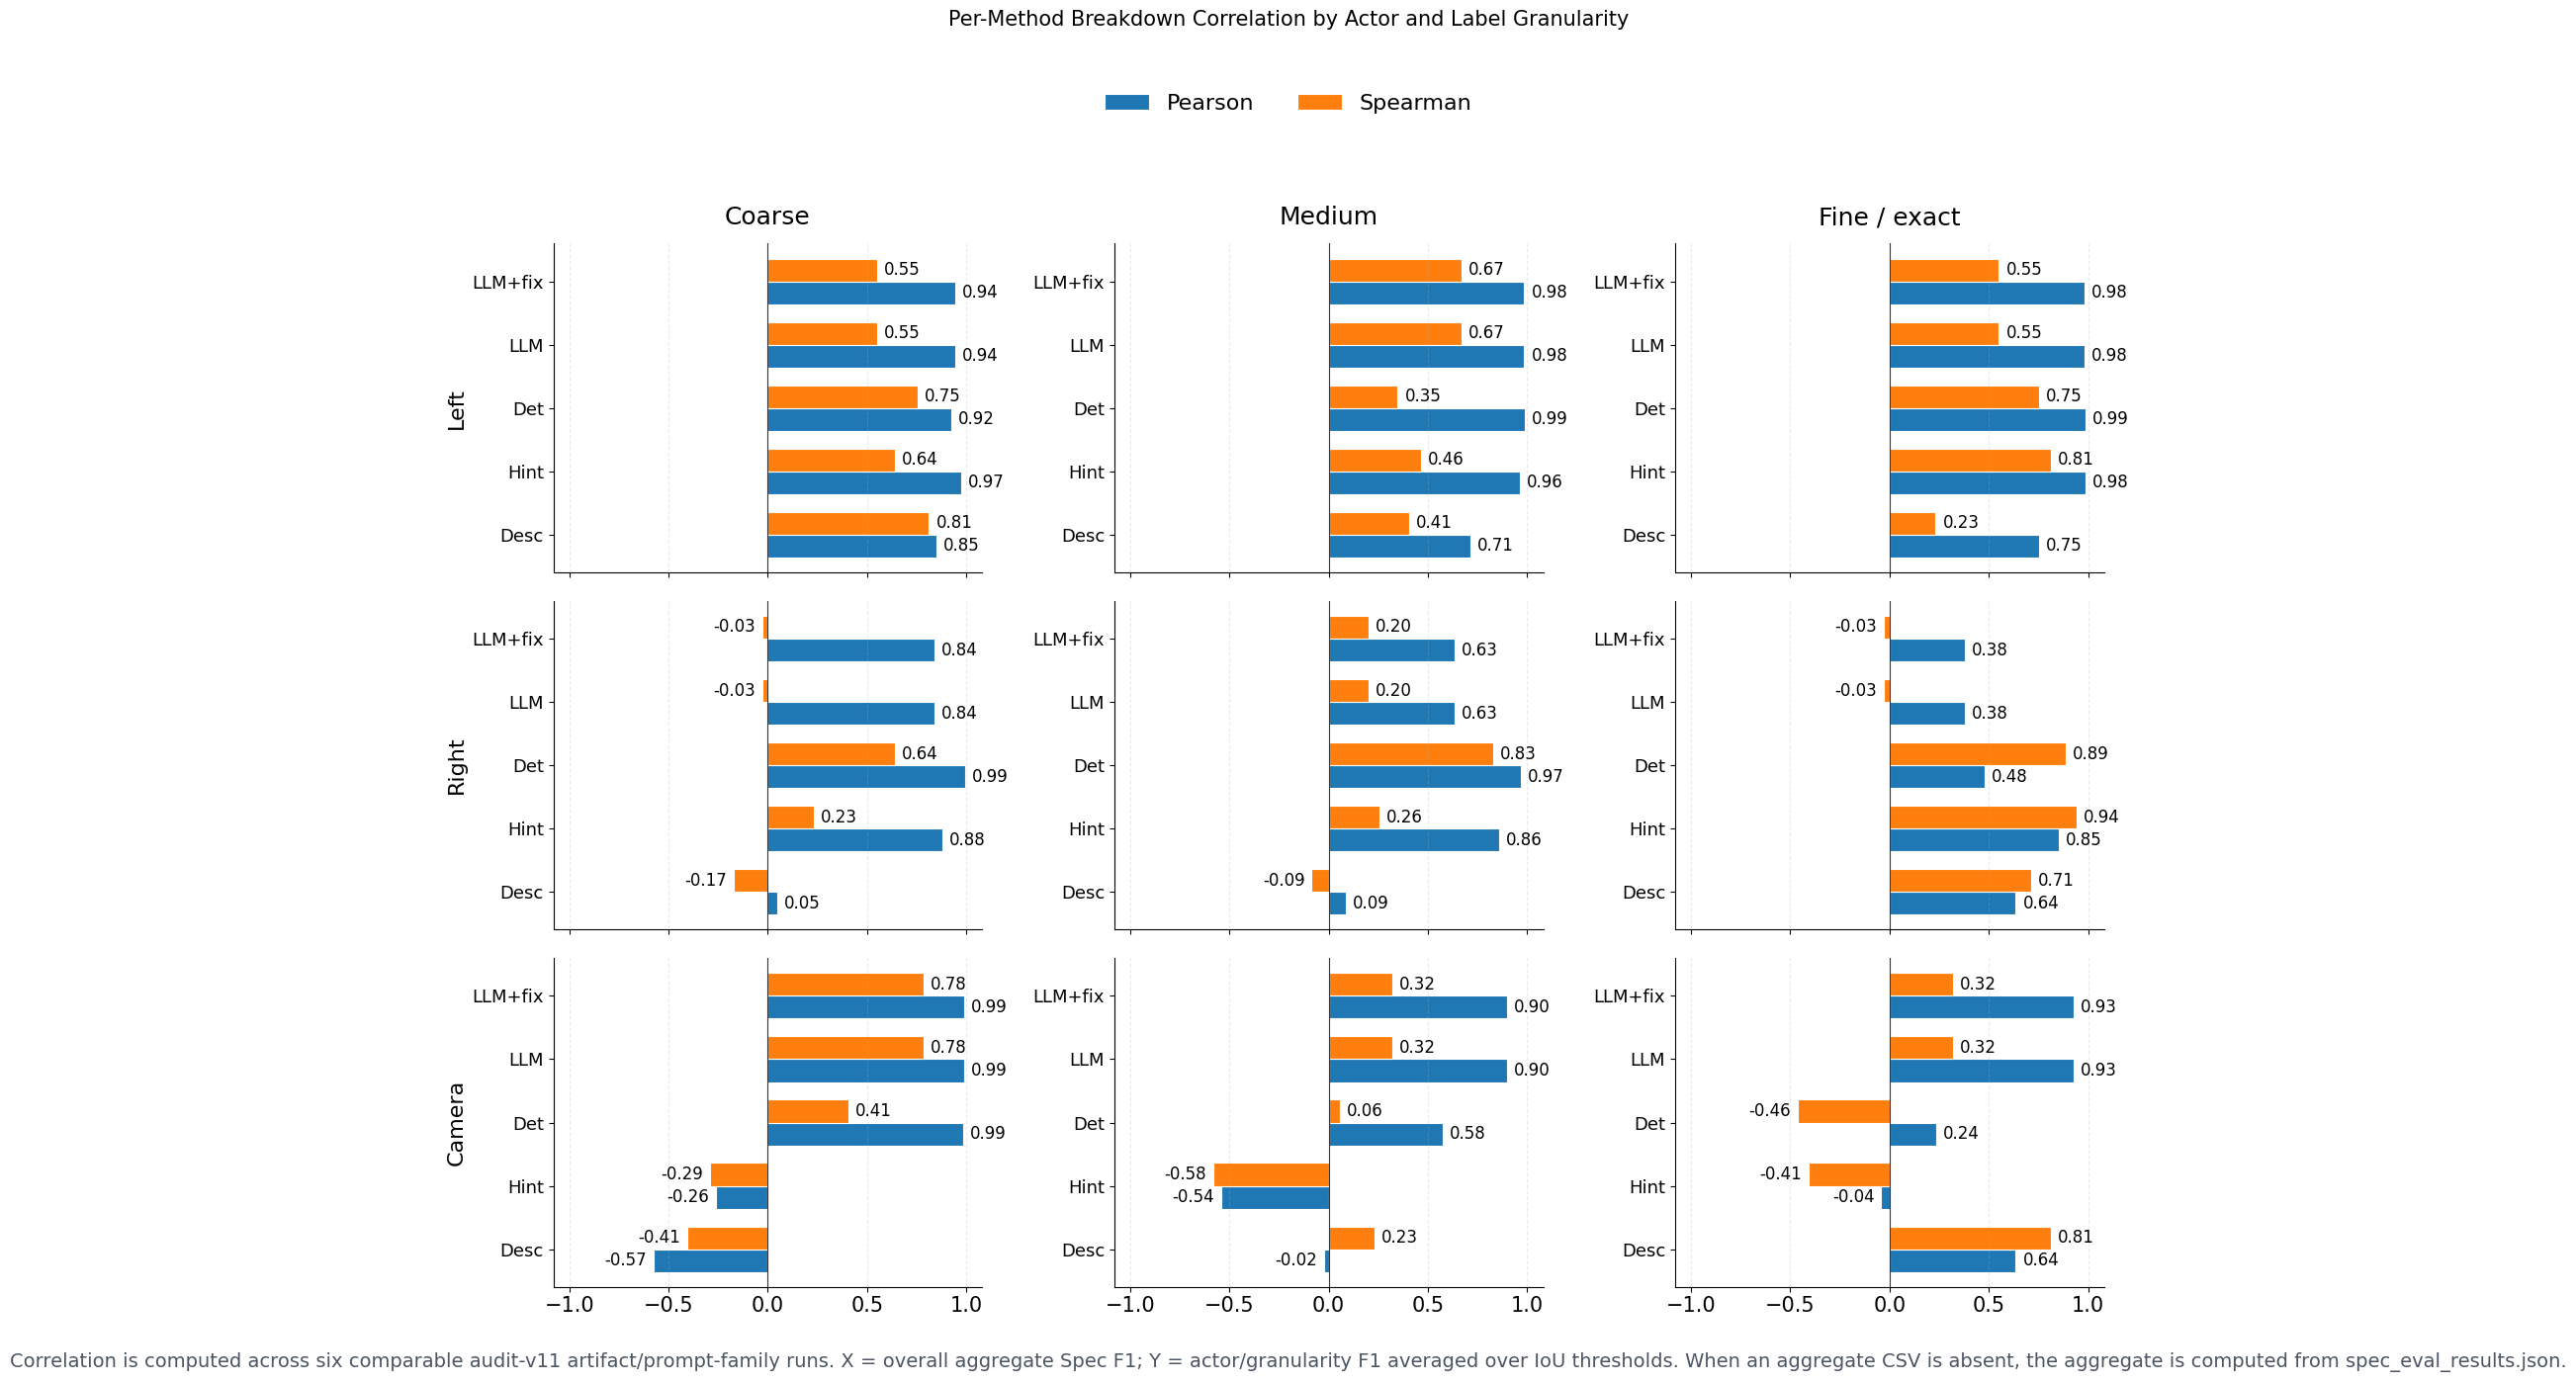

In [10]:
display(Markdown('### 3x3 Per-Method Breakdown Correlation'))

display(Markdown('Same 3x3 actor/granularity layout as the F1 breakdown, but each bar reports correlation instead of F1. For each data-generation/extraction method and each actor/granularity cell, Pearson and Spearman are computed across six comparable audit-v11 artifact/prompt-family runs.'))

import numpy as np

# Six comparable artifact/prompt-family runs that expose the audit-v11 spec-eval method breakdown.
method_corr_artifacts = [
    {
        'artifact_id': 'base',
        'artifact_label': 'Base',
        'artifact_dir': ROOT_DIR / 'notebooks/artifacts/qwen3.5_audit_v11_seg_extract_spec_eval',
    },
    {
        'artifact_id': 'cvs_context',
        'artifact_label': 'CVS context',
        'artifact_dir': ROOT_DIR / 'notebooks/artifacts/qwen3.5_audit_v11_seg_extract_spec_eval_with_cvs_context',
    },
    {
        'artifact_id': 'cvsctx_v2',
        'artifact_label': 'CVS ctx v2',
        'artifact_dir': ROOT_DIR / 'notebooks/artifacts/qwen3.5_audit_v11_seg_extract_spec_eval_cvsctx_v2__baseline',
    },
    {
        'artifact_id': 'cvsctx_v3_debug5',
        'artifact_label': 'CVS ctx v3',
        'artifact_dir': ROOT_DIR / 'notebooks/artifacts/qwen3.5_audit_v11_seg_extract_spec_eval_cvsctx_v3__debug5',
    },
    {
        'artifact_id': 'cvsctx_v3_1',
        'artifact_label': 'CVS ctx v3.1',
        'artifact_dir': ROOT_DIR / 'notebooks/artifacts/qwen3.5_audit_v11_seg_extract_spec_eval_cvsctx_v3_1',
    },
    {
        'artifact_id': 'cvsctx_v4',
        'artifact_label': 'CVS ctx v4',
        'artifact_dir': ROOT_DIR / 'notebooks/artifacts/qwen3.5_audit_v11_seg_extract_spec_eval_cvsctx_v4',
    },
]

method_corr_entries = [
    {'series_id': 'description', 'method': 'description_only', 'method_label': 'Description'},
    {'series_id': 'hint', 'method': 'hint_questions', 'method_label': 'Hint'},
    {'series_id': 'structured_deterministic', 'method': 'structured_prediction_deterministic', 'method_label': 'Structured deterministic'},
    {'series_id': 'structured_llm_extract', 'method': 'structured_prediction', 'method_label': 'Structured LLM extract'},
    {'series_id': 'structured_llm_extract_tool_fix', 'method': 'structured_prediction', 'method_label': 'Structured LLM extract + tool fix'},
]


def read_corr_results_map(artifact_dir):
    raw = json.loads((artifact_dir / 'spec_eval_results.json').read_text())
    return {normalize_method(method): rows for method, rows in raw.items()}


def read_corr_overall(artifact_dir, results_map=None):
    aggregate_path = artifact_dir / 'spec_f1_overall_aggregate.csv'
    if aggregate_path.exists():
        df = pd.read_csv(aggregate_path)
        score_col = 'aggregate mean F1' if 'aggregate mean F1' in df.columns else 'f1_mean_avg'
        return {normalize_method(row['method']): float(row[score_col]) for _, row in df.iterrows()}
    if results_map is None:
        results_map = read_corr_results_map(artifact_dir)
    overall = {}
    for method, rows in results_map.items():
        values = [float(row['f1_mean']) for row in rows if row.get('f1_mean') is not None]
        if values:
            overall[method] = float(np.mean(values))
    return overall


def actor_granularity_mean_from_results(results_map, method, actor, granularity):
    values = []
    for row in results_map.get(method, []):
        if row.get('actor') != actor or row.get('granularity') != granularity:
            continue
        value = row.get('f1_mean')
        if value is not None:
            values.append(float(value))
    return float(np.mean(values)) if values else np.nan

corr_point_rows = []
for artifact in method_corr_artifacts:
    artifact_dir = artifact['artifact_dir']
    if not (artifact_dir / 'spec_eval_results.json').exists():
        continue
    results_map_for_artifact = read_corr_results_map(artifact_dir)
    overall_map_for_artifact = read_corr_overall(artifact_dir, results_map_for_artifact)
    for entry in method_corr_entries:
        method = entry['method']
        if method not in results_map_for_artifact or method not in overall_map_for_artifact:
            continue
        for actor in slide_actors:
            for granularity in slide_granularities:
                cell_f1 = actor_granularity_mean_from_results(results_map_for_artifact, method, actor, granularity)
                if not np.isfinite(cell_f1):
                    continue
                corr_point_rows.append({
                    'method_id': entry['series_id'],
                    'method': method,
                    'method_label': entry['method_label'],
                    'artifact_id': artifact['artifact_id'],
                    'artifact_label': artifact['artifact_label'],
                    'actor': actor,
                    'actor_label': slide_actor_labels[actor],
                    'granularity': granularity,
                    'granularity_label': slide_granularity_labels[granularity],
                    'overall_spec_f1': overall_map_for_artifact[method],
                    'cell_f1_mean_over_iou': cell_f1,
                })

corr_points_df = pd.DataFrame(corr_point_rows)
corr_points_csv = OUT_DIR / 'per_method_actor_granularity_correlation_points.csv'
corr_points_df.to_csv(corr_points_csv, index=False)

corr_rows = []
for (method_id, method_label, actor, granularity), group in corr_points_df.groupby(['method_id', 'method_label', 'actor', 'granularity'], observed=True):
    x = group['overall_spec_f1'].astype(float)
    y = group['cell_f1_mean_over_iou'].astype(float)
    corr_rows.append({
        'method_id': method_id,
        'method_label': method_label,
        'actor': actor,
        'actor_label': slide_actor_labels[actor],
        'granularity': granularity,
        'granularity_label': slide_granularity_labels[granularity],
        'n_artifact_points': len(group),
        'pearson_r': x.corr(y, method='pearson') if len(group) >= 3 and x.nunique() > 1 and y.nunique() > 1 else np.nan,
        'spearman_r': x.corr(y, method='spearman') if len(group) >= 3 and x.nunique() > 1 and y.nunique() > 1 else np.nan,
    })

corr_df = pd.DataFrame(corr_rows)
corr_df['method_id'] = pd.Categorical(corr_df['method_id'], categories=[entry['series_id'] for entry in method_corr_entries], ordered=True)
corr_df['actor'] = pd.Categorical(corr_df['actor'], categories=slide_actors, ordered=True)
corr_df['granularity'] = pd.Categorical(corr_df['granularity'], categories=slide_granularities, ordered=True)
corr_df = corr_df.sort_values(['actor', 'granularity', 'method_id']).reset_index(drop=True)
corr_csv = OUT_DIR / 'per_method_actor_granularity_correlation.csv'
corr_df.to_csv(corr_csv, index=False)

display(corr_df.style.format({'pearson_r': '{:.3f}', 'spearman_r': '{:.3f}'}, na_rep=''))

# Plot Pearson/Spearman as paired bars in each actor x granularity panel.
fig, axes = plt.subplots(len(slide_actors), len(slide_granularities), figsize=(17.5, 13.0), sharex=True)
method_ids = [entry['series_id'] for entry in method_corr_entries]
method_labels_short = {
    'description': 'Desc',
    'hint': 'Hint',
    'structured_deterministic': 'Det',
    'structured_llm_extract': 'LLM',
    'structured_llm_extract_tool_fix': 'LLM+fix',
}
metric_specs = [
    ('pearson_r', 'Pearson', '#1F77B4'),
    ('spearman_r', 'Spearman', '#FF7F0E'),
]
x = np.arange(len(method_ids))
bar_width = 0.36

for row_idx, actor in enumerate(slide_actors):
    for col_idx, granularity in enumerate(slide_granularities):
        ax = axes[row_idx][col_idx]
        sub = corr_df[(corr_df['actor'].astype(str).eq(actor)) & (corr_df['granularity'].astype(str).eq(granularity))].set_index('method_id').reindex(method_ids)
        for metric_idx, (metric_col, metric_label, color) in enumerate(metric_specs):
            values = sub[metric_col].astype(float).tolist()
            ypos = x + (metric_idx - 0.5) * bar_width
            bars = ax.barh(
                ypos,
                values,
                height=bar_width,
                color=color,
                edgecolor='white',
                linewidth=0.8,
                label=metric_label,
            )
            for rect, value in zip(bars, values):
                if not np.isfinite(value):
                    continue
                ha = 'left' if value >= 0 else 'right'
                x_text = value + 0.035 if value >= 0 else value - 0.035
                ax.text(
                    x_text,
                    rect.get_y() + rect.get_height() / 2,
                    f'{value:.2f}',
                    ha=ha,
                    va='center',
                    fontsize=12,
                )
        ax.axvline(0, color='#333333', linewidth=0.8)
        if row_idx == 0:
            ax.set_title(slide_granularity_labels[granularity], fontsize=18, pad=14)
        if col_idx == 0:
            ax.set_ylabel(slide_actor_labels[actor], fontsize=16)
        ax.set_yticks(x)
        ax.set_yticklabels([method_labels_short[mid] for mid in method_ids], fontsize=13)
        ax.set_xlim(-1.08, 1.08)
        ax.grid(axis='x', linestyle='--', alpha=0.25)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, ncols=2, frameon=False, loc='upper center', bbox_to_anchor=(0.5, 1.02), fontsize=16)
fig.suptitle('Per-Method Breakdown Correlation by Actor and Label Granularity', fontsize=15, y=1.07)
fig.text(
    0.5,
    0.01,
    'Correlation is computed across six comparable audit-v11 artifact/prompt-family runs. X = overall aggregate Spec F1; Y = actor/granularity F1 averaged over IoU thresholds. When an aggregate CSV is absent, the aggregate is computed from spec_eval_results.json.',
    ha='center',
    va='bottom',
    fontsize=14,
    color='#4B5563',
)
plt.tight_layout(rect=[0, 0.035, 1, 0.97])
corr_grid_png = OUT_DIR / 'per_method_actor_granularity_correlation_grid.png'
corr_grid_pdf = OUT_DIR / 'per_method_actor_granularity_correlation_grid.pdf'
fig.savefig(corr_grid_png, dpi=300, bbox_inches='tight')
fig.savefig(corr_grid_pdf, bbox_inches='tight')
print('saved', corr_points_csv)
print('saved', corr_csv)
print('saved', corr_grid_png)
print('saved', corr_grid_pdf)
plt.show()




In [11]:
display(Markdown('### Three-Actor Spec F1 Table'))
three_actor_latex = build_three_actor_latex(spec_detail, spec_results_map)
print(three_actor_latex)


### Three-Actor Spec F1 Table

\begin{table*}[t]
\centering
\caption{Actor-specific segment-level F1 for the current best prompt family on audit-v11. For Left, exact uses the full retraction-direction code, medium collapses to direction only, and coarse collapses to maintain versus change. For Right, exact uses tool, action, target, and context together, medium uses tool, action, and target, and coarse uses action and target only. For Camera, exact distinguishes the full camera action code, medium collapses to zoom versus reposition versus no-change, and coarse collapses to change versus no-change. F1@10, F1@25, and F1@50 mean F1 at IoU thresholds 0.10, 0.25, and 0.50 respectively. Across the 27 displayed left/right/camera cells, 1000-sample bootstrap 95\% confidence intervals for each strategy average are: Direct average 0.110 [0.096, 0.126]; Hint-guided average 0.252 [0.234, 0.272]; Structured average 0.322 [0.302, 0.343].}
\label{tab:auditv11_three_actor_f1}
\resizebox{\textwidth}{!}{%
\begin{tabular}{ll ccc ccc 

In [12]:
display(Markdown('## LLM Judge Results'))

judge_agg_table = (
    judge_agg[judge_agg['candidate_kind'].isin(['extracted_json', 'original_text'])]
    .pivot_table(index='candidate', columns='base_method', values='mean_score', aggfunc='mean')
    .reindex(columns=METHOD_ORDER)
)
judge_agg_table.columns = [METHOD_LABELS[c] for c in judge_agg_table.columns]
display(Markdown('### Aggregate Judge Scores'))
display(judge_agg_table)
judge_agg_latex = bold_best_per_row(judge_agg_table)
print('LaTeX: judge aggregate')
print(latex_table(judge_agg_latex, index=True, caption='Aggregate LLM-judge scores for methods within the current best audit-v11 prompt family, evaluated against human-validated ground truth. Rows report the extracted code JSON and original segmentation text views separately. Best result per row is bolded.', label='tab:auditv11_current_best_judge_aggregate'))

for candidate_kind, title in [('extracted_json', 'Extracted code JSON'), ('original_text', 'Original segmentation text')]:
    table = (
        judge_summary[judge_summary['candidate_kind'] == candidate_kind]
        .pivot_table(index='rubric_item', columns='base_method', values='mean_score', aggfunc='mean')
        .reindex(columns=METHOD_ORDER)
    )
    table = table.reindex(sorted(table.index, key=rubric_actor_order_key))
    aggregate_row = (
        judge_agg[judge_agg['candidate_kind'] == candidate_kind]
        .set_index('base_method')
        .reindex(METHOD_ORDER)['mean_score']
    )
    table.loc['aggregate'] = aggregate_row.values
    table.columns = [METHOD_LABELS[c] for c in table.columns]
    display(Markdown(f'### Rubric Scores: {title}'))
    display(table)
    latex_ready = bold_best_per_row(table)
    print(f'LaTeX: judge rubric {candidate_kind}')
    print(latex_table(latex_ready, index=True, caption=f'LLM-judge rubric scores for {title} under the current best audit-v11 prompt family. Rows are grouped by actor and the final row reports the aggregate score across rubric items; best result per row is bolded.', label=f'tab:auditv11_current_best_judge_{candidate_kind}'))


## LLM Judge Results

### Aggregate Judge Scores

,Description,Hint,Structured,Structured Deterministic
candidate,,,,
Extracted code JSON,0.473737,0.497475,0.498990,0.492929
Original segmentation text,0.575077,0.652525,0.547475,0.539394


LaTeX: judge aggregate
\begin{table}
\caption{Aggregate LLM-judge scores for methods within the current best audit-v11 prompt family, evaluated against human-validated ground truth. Rows report the extracted code JSON and original segmentation text views separately. Best result per row is bolded.}
\label{tab:auditv11_current_best_judge_aggregate}
\begin{tabular}{lllll}
\toprule
 & Description & Hint & Structured & Structured Deterministic \\
candidate &  &  &  &  \\
\midrule
Extracted code JSON & 0.474 & 0.497 & \\textbf{0.499} & 0.493 \\
Original segmentation text & 0.575 & \\textbf{0.653} & 0.547 & 0.539 \\
\bottomrule
\end{tabular}
\end{table}



### Rubric Scores: Extracted code JSON

,Description,Hint,Structured,Structured Deterministic
rubric_item,,,,
left_action,0.166667,0.272222,0.472222,0.511111
left_time,0.222222,0.488889,0.544444,0.500000
right_action,0.633333,0.650000,0.627778,0.638889
right_context,0.188889,0.227778,0.144444,0.200000
right_target,0.372222,0.405556,0.350000,0.366667
right_time,0.283333,0.305556,0.338889,0.288889
right_tool,0.522222,0.655556,0.583333,0.583333
camera_action,0.422222,0.272222,0.255556,0.200000
camera_time,0.422222,0.255556,0.238889,0.222222


LaTeX: judge rubric extracted_json
\begin{table}
\caption{LLM-judge rubric scores for Extracted code JSON under the current best audit-v11 prompt family. Rows are grouped by actor and the final row reports the aggregate score across rubric items; best result per row is bolded.}
\label{tab:auditv11_current_best_judge_extracted_json}
\begin{tabular}{lllll}
\toprule
 & Description & Hint & Structured & Structured Deterministic \\
rubric_item &  &  &  &  \\
\midrule
left_action & 0.167 & 0.272 & 0.472 & \\textbf{0.511} \\
left_time & 0.222 & 0.489 & \\textbf{0.544} & 0.500 \\
right_action & 0.633 & \\textbf{0.650} & 0.628 & 0.639 \\
right_context & 0.189 & \\textbf{0.228} & 0.144 & 0.200 \\
right_target & 0.372 & \\textbf{0.406} & 0.350 & 0.367 \\
right_time & 0.283 & 0.306 & \\textbf{0.339} & 0.289 \\
right_tool & 0.522 & \\textbf{0.656} & 0.583 & 0.583 \\
camera_action & \\textbf{0.422} & 0.272 & 0.256 & 0.200 \\
camera_time & \\textbf{0.422} & 0.256 & 0.239 & 0.222 \\
other_action & \\t

### Rubric Scores: Original segmentation text

,Description,Hint,Structured,Structured Deterministic
rubric_item,,,,
left_action,0.297753,0.561111,0.183333,0.188889
left_time,0.258427,0.550000,0.533333,0.500000
right_action,0.780899,0.772222,0.694444,0.705556
right_context,0.443820,0.533333,0.327778,0.322222
right_target,0.606742,0.655556,0.466667,0.450000
right_time,0.556180,0.488889,0.444444,0.438889
right_tool,0.505618,0.772222,0.711111,0.711111
camera_action,0.443820,0.438889,0.350000,0.322222
camera_time,0.443820,0.405556,0.344444,0.316667


LaTeX: judge rubric original_text
\begin{table}
\caption{LLM-judge rubric scores for Original segmentation text under the current best audit-v11 prompt family. Rows are grouped by actor and the final row reports the aggregate score across rubric items; best result per row is bolded.}
\label{tab:auditv11_current_best_judge_original_text}
\begin{tabular}{lllll}
\toprule
 & Description & Hint & Structured & Structured Deterministic \\
rubric_item &  &  &  &  \\
\midrule
left_action & 0.298 & \\textbf{0.561} & 0.183 & 0.189 \\
left_time & 0.258 & \\textbf{0.550} & 0.533 & 0.500 \\
right_action & \\textbf{0.781} & 0.772 & 0.694 & 0.706 \\
right_context & 0.444 & \\textbf{0.533} & 0.328 & 0.322 \\
right_target & 0.607 & \\textbf{0.656} & 0.467 & 0.450 \\
right_time & \\textbf{0.556} & 0.489 & 0.444 & 0.439 \\
right_tool & 0.506 & \\textbf{0.772} & 0.711 & 0.711 \\
camera_action & \\textbf{0.444} & 0.439 & 0.350 & 0.322 \\
camera_time & \\textbf{0.444} & 0.406 & 0.344 & 0.317 \\
other_action 

## Validation/Test Video Split: Method Selection Correlation

The 30 videos are split once by video ID with a fixed seed: 10 validation videos and 20 test videos. Validation is used to inspect F1 as a function of IoU for the five data-generation/extraction methods. Test performance is summarized by the final score: mean(left/exact, right/medium, camera/coarse), with each component averaged over IoU thresholds.

Validation videos: 10; test videos: 20; seed: `20260610`

,split_seed,split,video_id
0,20260610,test,004fa282-7e76-473e-bf34-01fe831368dc
1,20260610,test,021ebd6a-3195-40ac-b86d-99ac5e5ef621
2,20260610,test,06cc10f4-8b31-4112-b024-ea1818c5d096
3,20260610,test,0a094835-5933-4f29-a184-6bfa46579272
4,20260610,test,0e5b6b69-2ddb-497e-bc25-aad5fe062df8
5,20260610,test,0f7ff338-1195-4482-b26b-530858de1811
6,20260610,test,10784ea7-8272-4b76-86c5-0f90cf74c750
7,20260610,test,144fef8d-eaed-48ac-ba3b-a7a214e95f42
8,20260610,test,14d2ecc3-bbdb-42e1-9e69-91b72d1f7cfb
9,20260610,test,1971efbe-2e68-4e13-ba04-2bc6ed76b4f1


### Validation F1 by IoU

iou,0.10,0.25,0.50
method_label,,,
Description,0.205175,0.197000,0.165741
Hint,0.347075,0.322615,0.271713
Structured deterministic,0.336154,0.311530,0.301962
Structured LLM extract,0.439173,0.417360,0.400300
Structured LLM extract + tool fix,0.441642,0.419829,0.402769


saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/validation_f1_by_iou_seed20260610.png
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/validation_f1_by_iou_seed20260610.pdf


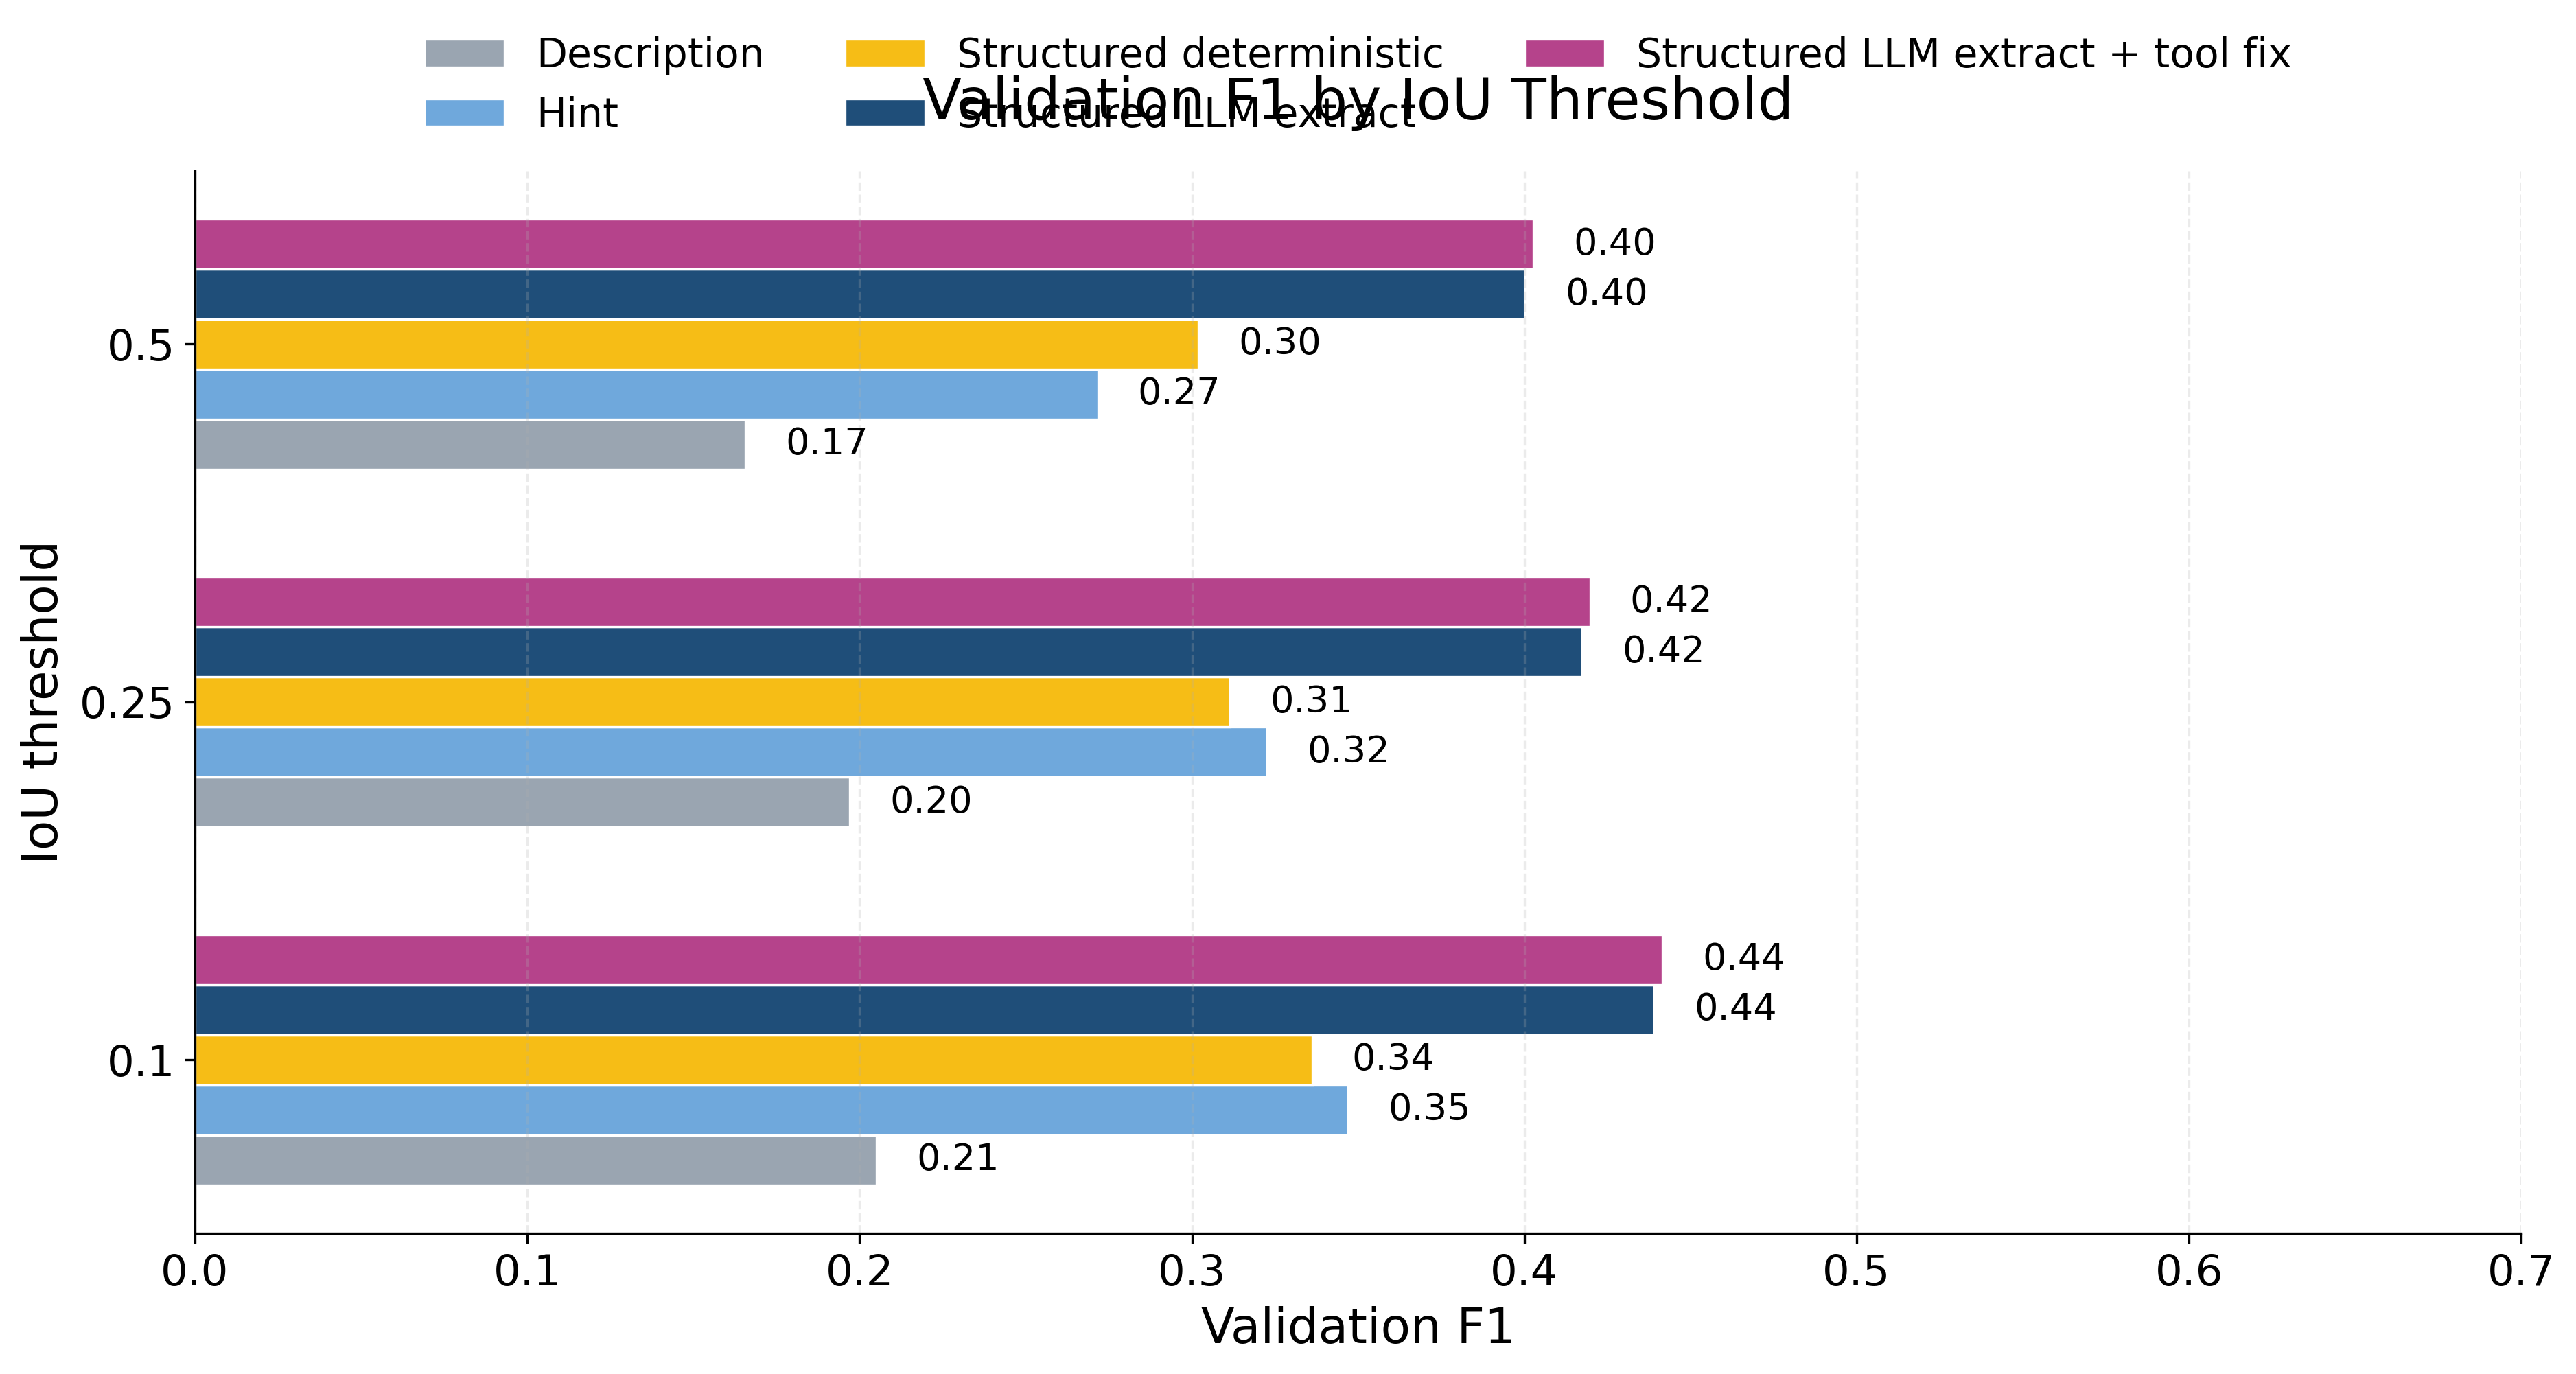

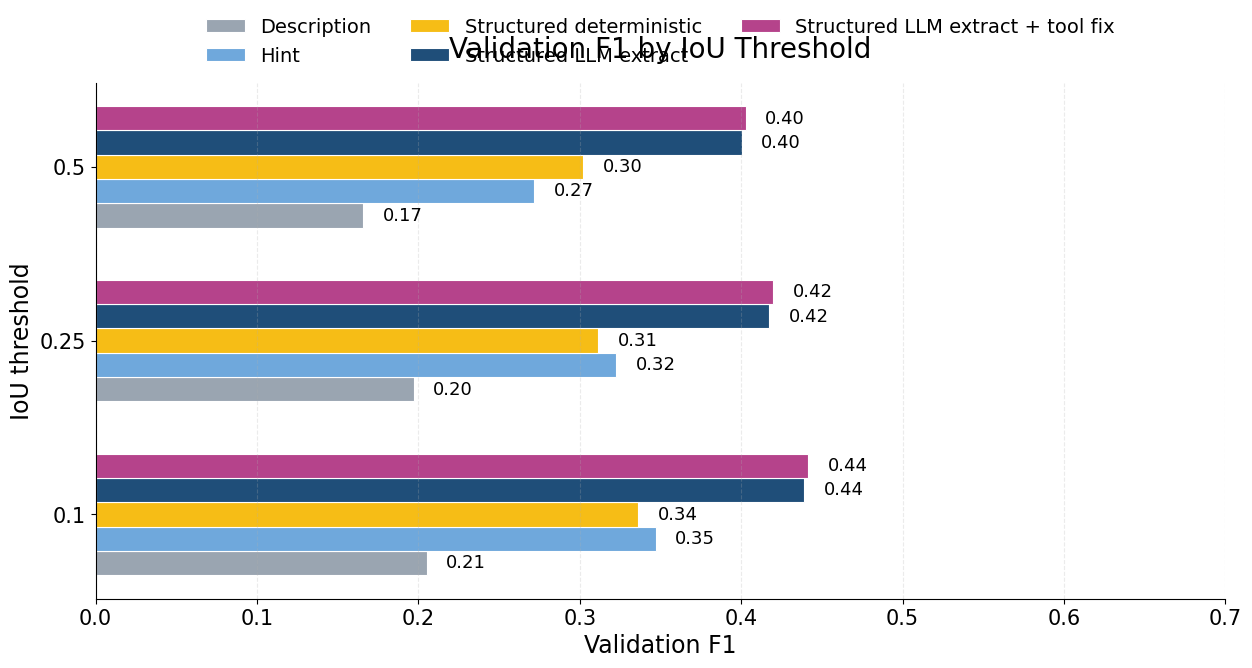

### Test Split: Six-system Synthetic-vs-Human Final Score Correlation

Final score is `mean(left/exact, right/medium, camera/coarse)`. Both axes use the same held-out videos from the seeded test split that are available in both GT tables: 17 of 20 test videos. The dashed crosshair shows a single aggregate majority-label null: left rows always predict the left/exact majority label, right rows the right/medium majority label, camera rows the camera/coarse majority label, then the three component F1s are averaged into the final score.

,split_seed,split,gt_source,model_short,model_name,variant_label,system_label,n_videos_in_split,left_exact,right_medium,camera_coarse,left_exact_n,right_medium_n,camera_coarse_n,final_score,final_score_se,n_components
0,20260610,test,Human GT,claude,Claude-Haiku-4.5,Baseline default,Claude-Haiku-4.5 / Baseline,17,0.144,0.029,0.478,81,80,59,0.217,0.018,3
1,20260610,test,Human GT,claude,Claude-Haiku-4.5,SurGent default,Claude-Haiku-4.5 / SurGent,17,0.145,0.042,0.392,81,80,59,0.193,0.034,3
2,20260610,test,Human GT,gemini,Gemini-2.5-flash,Baseline default,Gemini-2.5-flash / Baseline,17,0.102,0.077,0.306,81,80,59,0.162,0.034,3
3,20260610,test,Human GT,gemini,Gemini-2.5-flash,SurGent default,Gemini-2.5-flash / SurGent,17,0.077,0.066,0.385,81,80,59,0.176,0.036,3
4,20260610,test,Human GT,gpt,GPT-5.4-mini,Baseline default,GPT-5.4-mini / Baseline,17,0.017,0.051,0.443,81,80,59,0.170,0.018,3
5,20260610,test,Human GT,gpt,GPT-5.4-mini,SurGent default,GPT-5.4-mini / SurGent,17,0.056,0.050,0.482,81,80,59,0.196,0.027,3
6,20260610,test,v3.1 structured LLM extract + tool fix synthetic GT,claude,Claude-Haiku-4.5,Baseline default,Claude-Haiku-4.5 / Baseline,17,0.179,0.025,0.476,140,135,22,0.227,0.109,3
7,20260610,test,v3.1 structured LLM extract + tool fix synthetic GT,claude,Claude-Haiku-4.5,SurGent default,Claude-Haiku-4.5 / SurGent,17,0.181,0.040,0.371,140,135,22,0.198,0.042,3
8,20260610,test,v3.1 structured LLM extract + tool fix synthetic GT,gemini,Gemini-2.5-flash,Baseline default,Gemini-2.5-flash / Baseline,17,0.071,0.037,0.353,140,135,22,0.153,0.022,3
9,20260610,test,v3.1 structured LLM extract + tool fix synthetic GT,gemini,Gemini-2.5-flash,SurGent default,Gemini-2.5-flash / SurGent,17,0.132,0.047,0.353,140,135,22,0.177,0.027,3


,split_seed,split,gt_source,component,actor,granularity,majority_label,majority_label_macro_f1,n,n_videos_in_split
2,20260610,test,Human GT,camera_coarse,camera,coarse,change,1.000,354,17
3,20260610,test,Human GT,final_score,aggregate,final,,0.392,1320,17
0,20260610,test,Human GT,left_exact,left,exact,KEEP_RETRACT_LATERAL,0.145,486,17
1,20260610,test,Human GT,right_medium,right,medium,"('Hook', 'DISSECT', 'HepatocysticTriangle')",0.032,480,17
6,20260610,test,v3.1 structured LLM extract + tool fix synthetic GT,camera_coarse,camera,coarse,change,1.000,330,17
7,20260610,test,v3.1 structured LLM extract + tool fix synthetic GT,final_score,aggregate,final,,0.403,4455,17
4,20260610,test,v3.1 structured LLM extract + tool fix synthetic GT,left_exact,left,exact,KEEP_RETRACT_LATERAL,0.181,2100,17
5,20260610,test,v3.1 structured LLM extract + tool fix synthetic GT,right_medium,right,medium,"('Hook', 'DISSECT', 'HepatocysticTriangle')",0.027,2025,17


### Held-out Split Final Score Bar Charts

Each chart shows only the six baseline/SurGent systems on the seeded held-out test split; the dashed line is the aggregate majority-label baseline for that GT source.

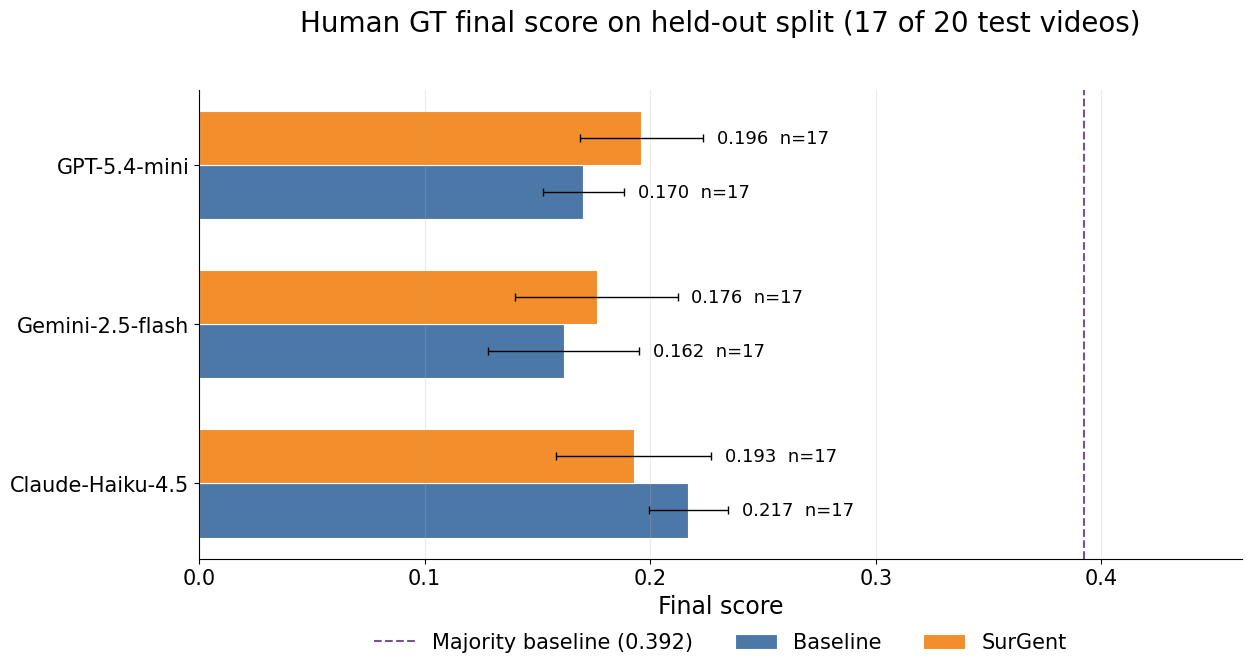

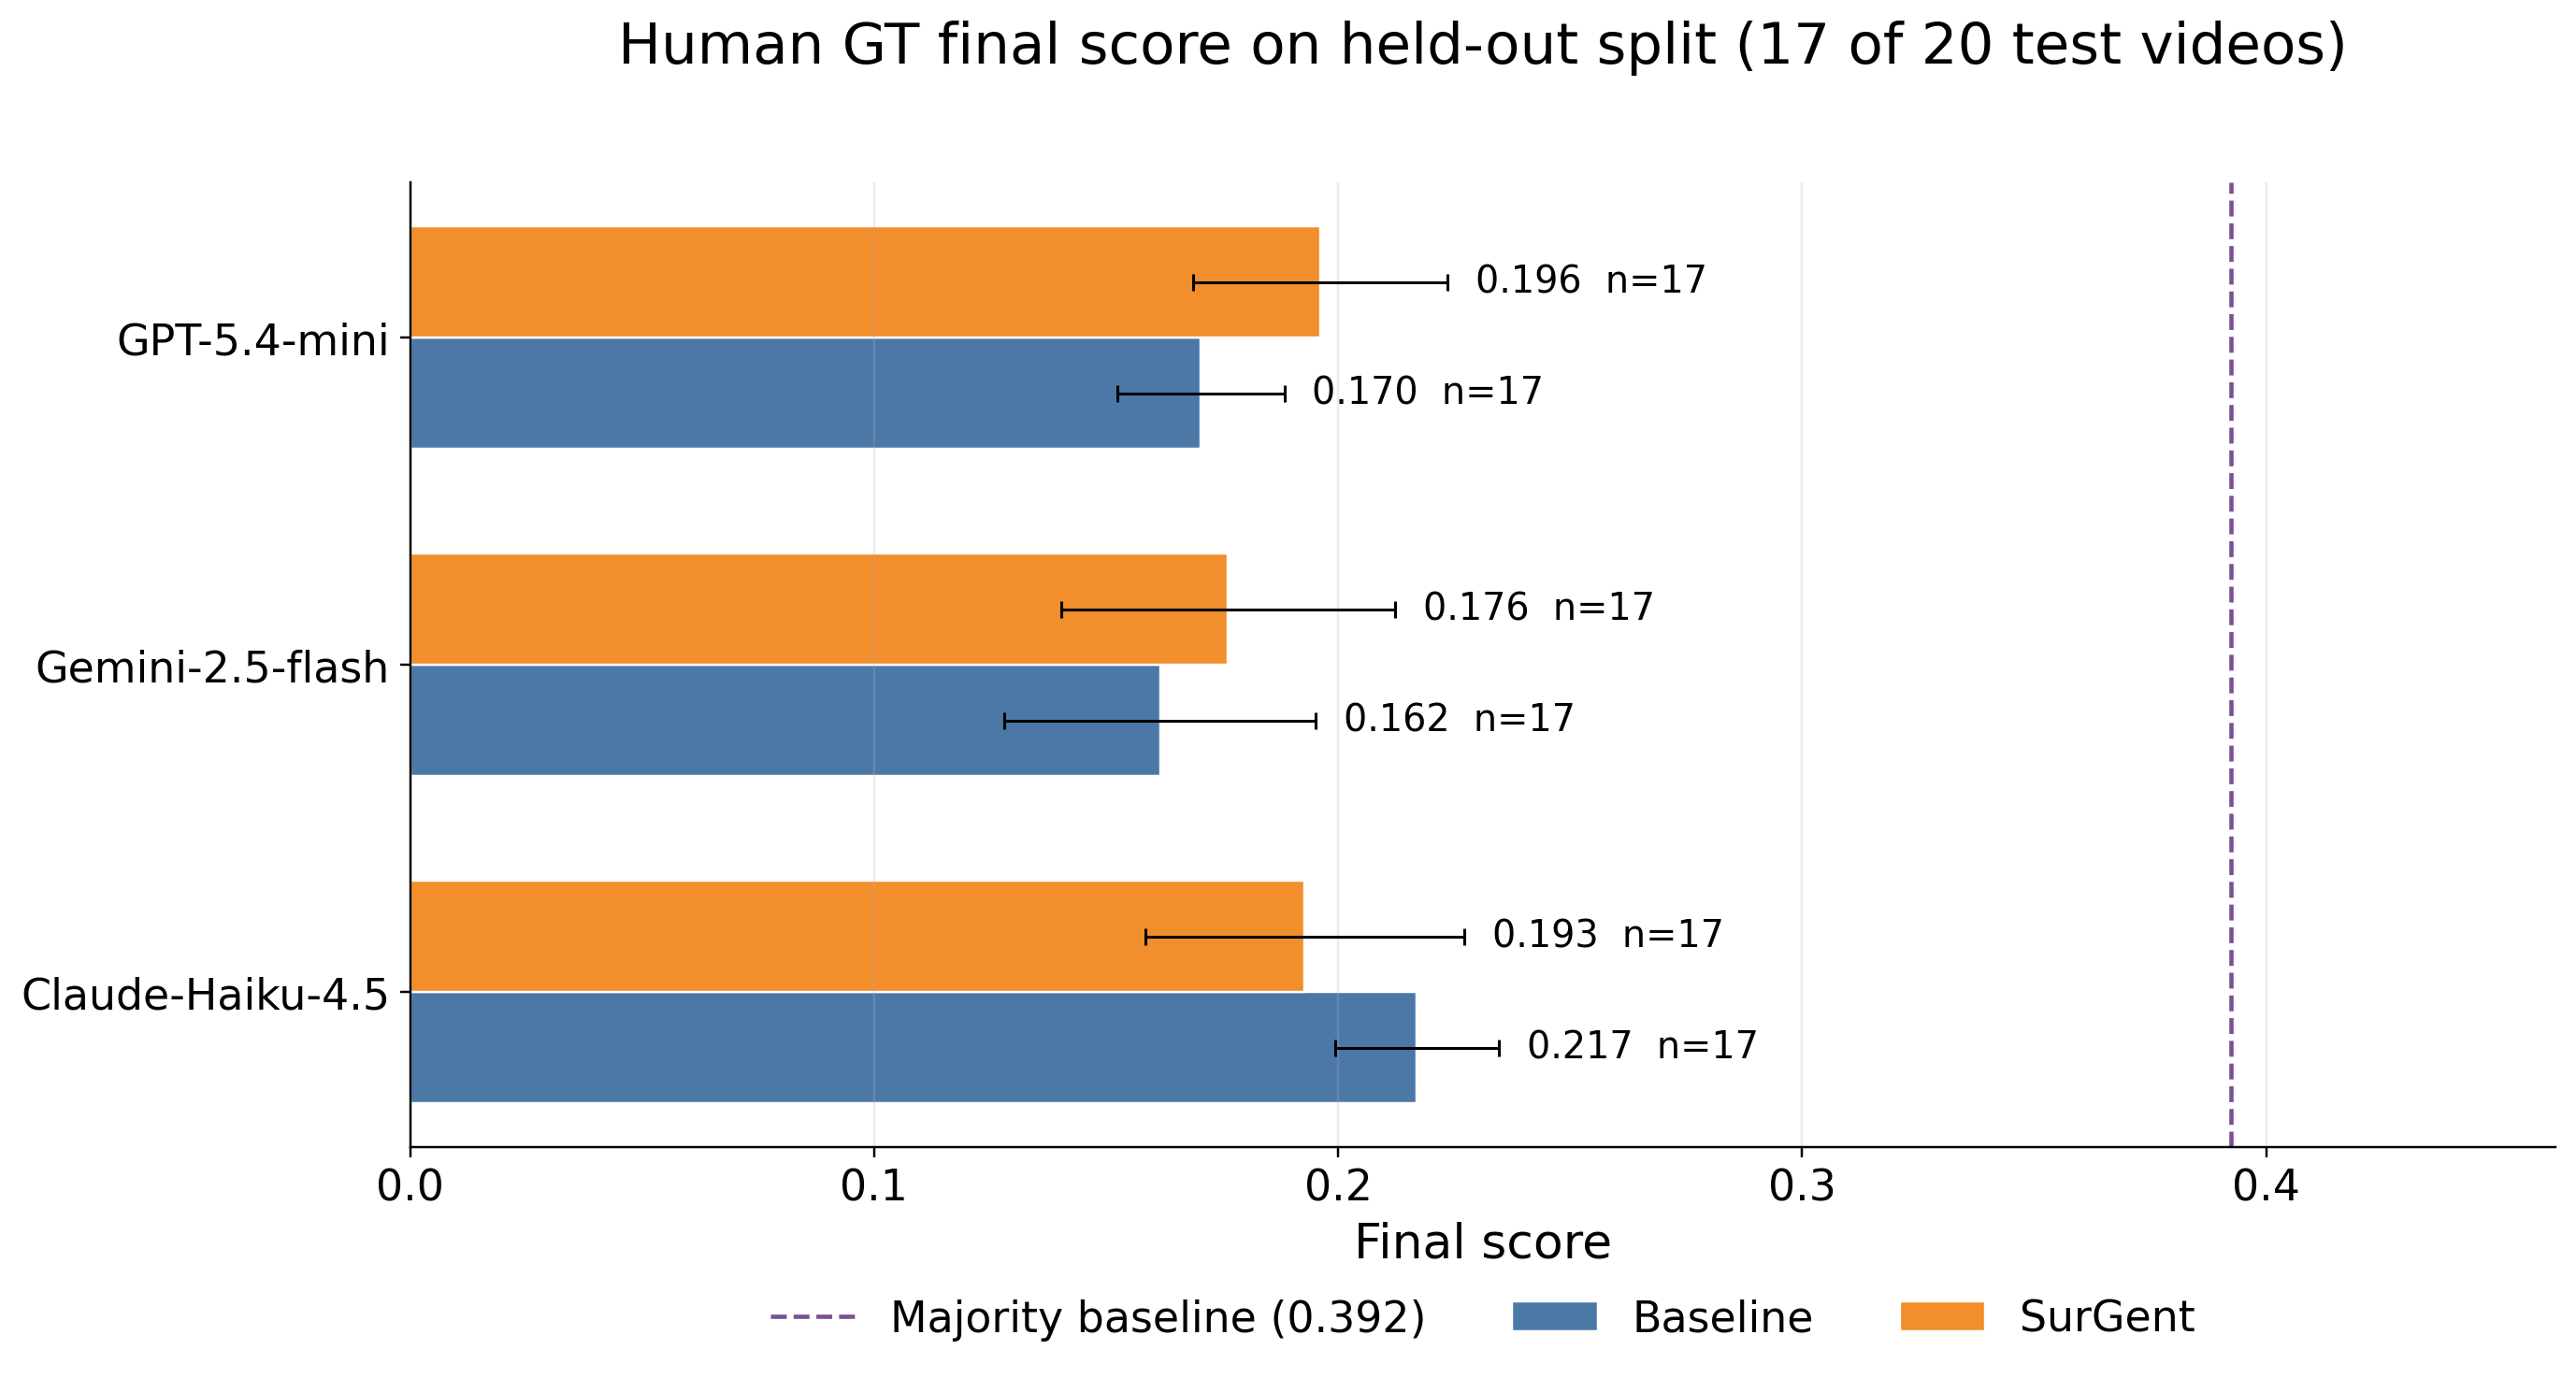

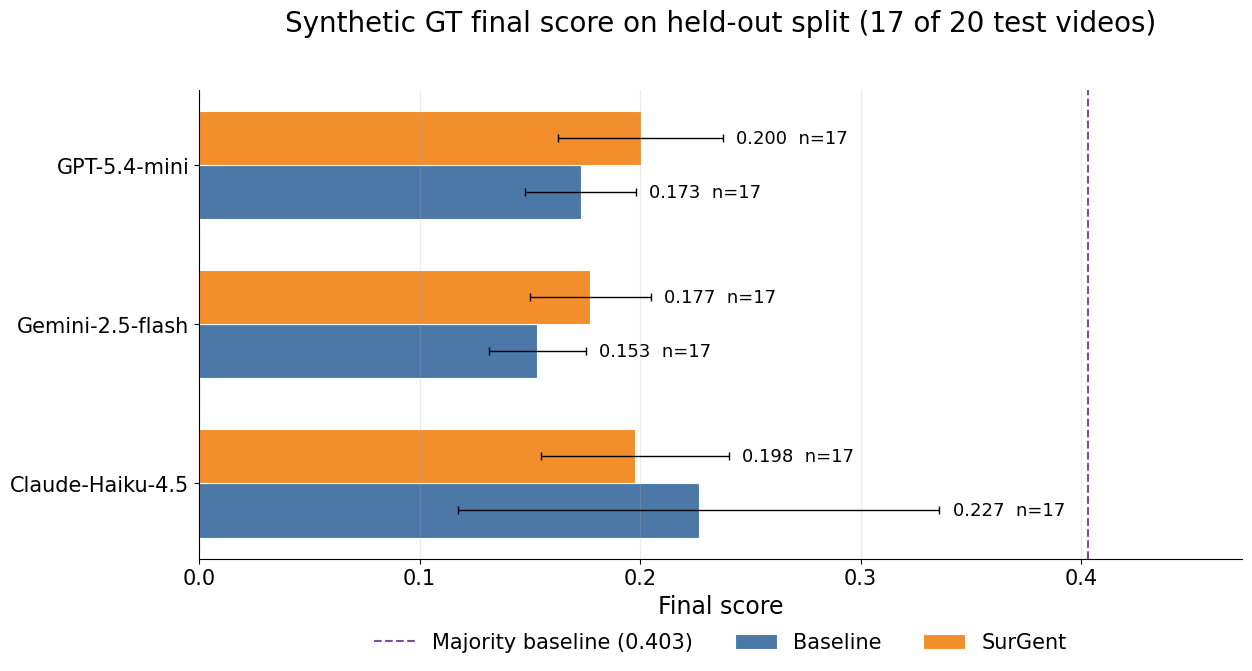

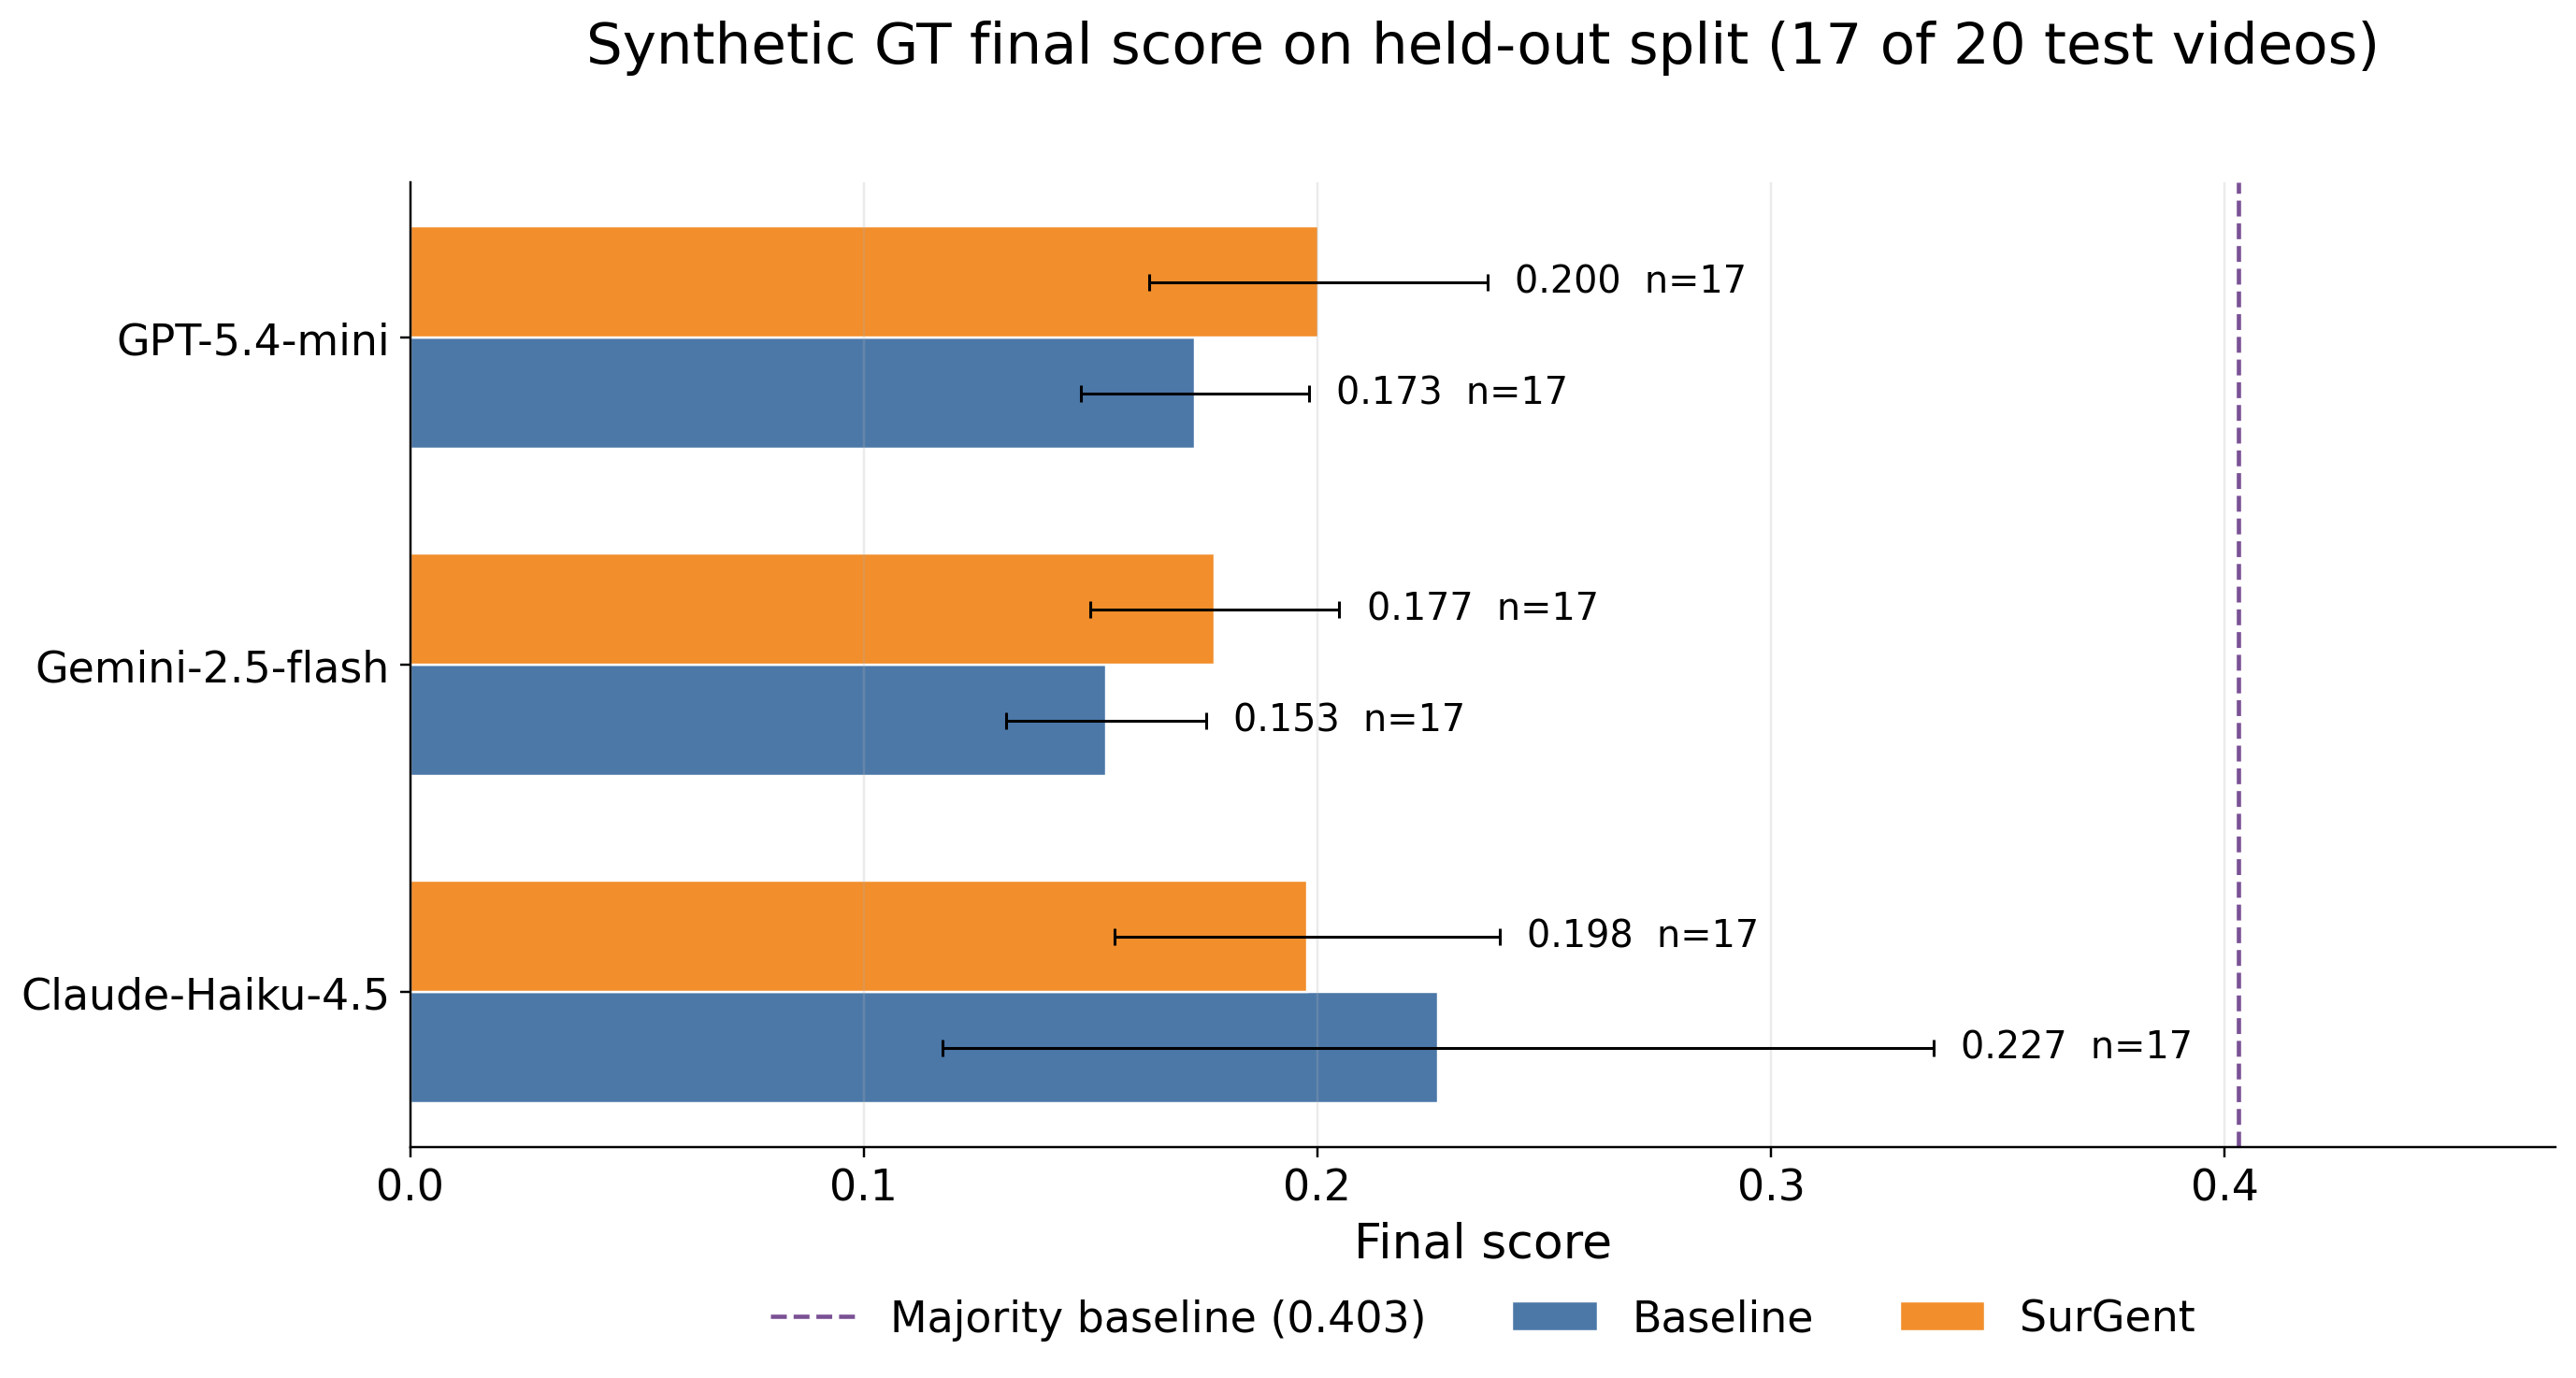

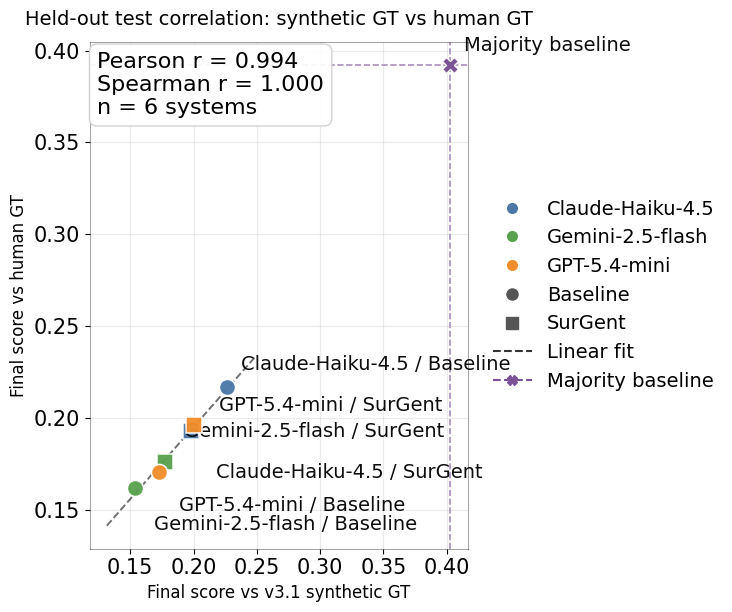

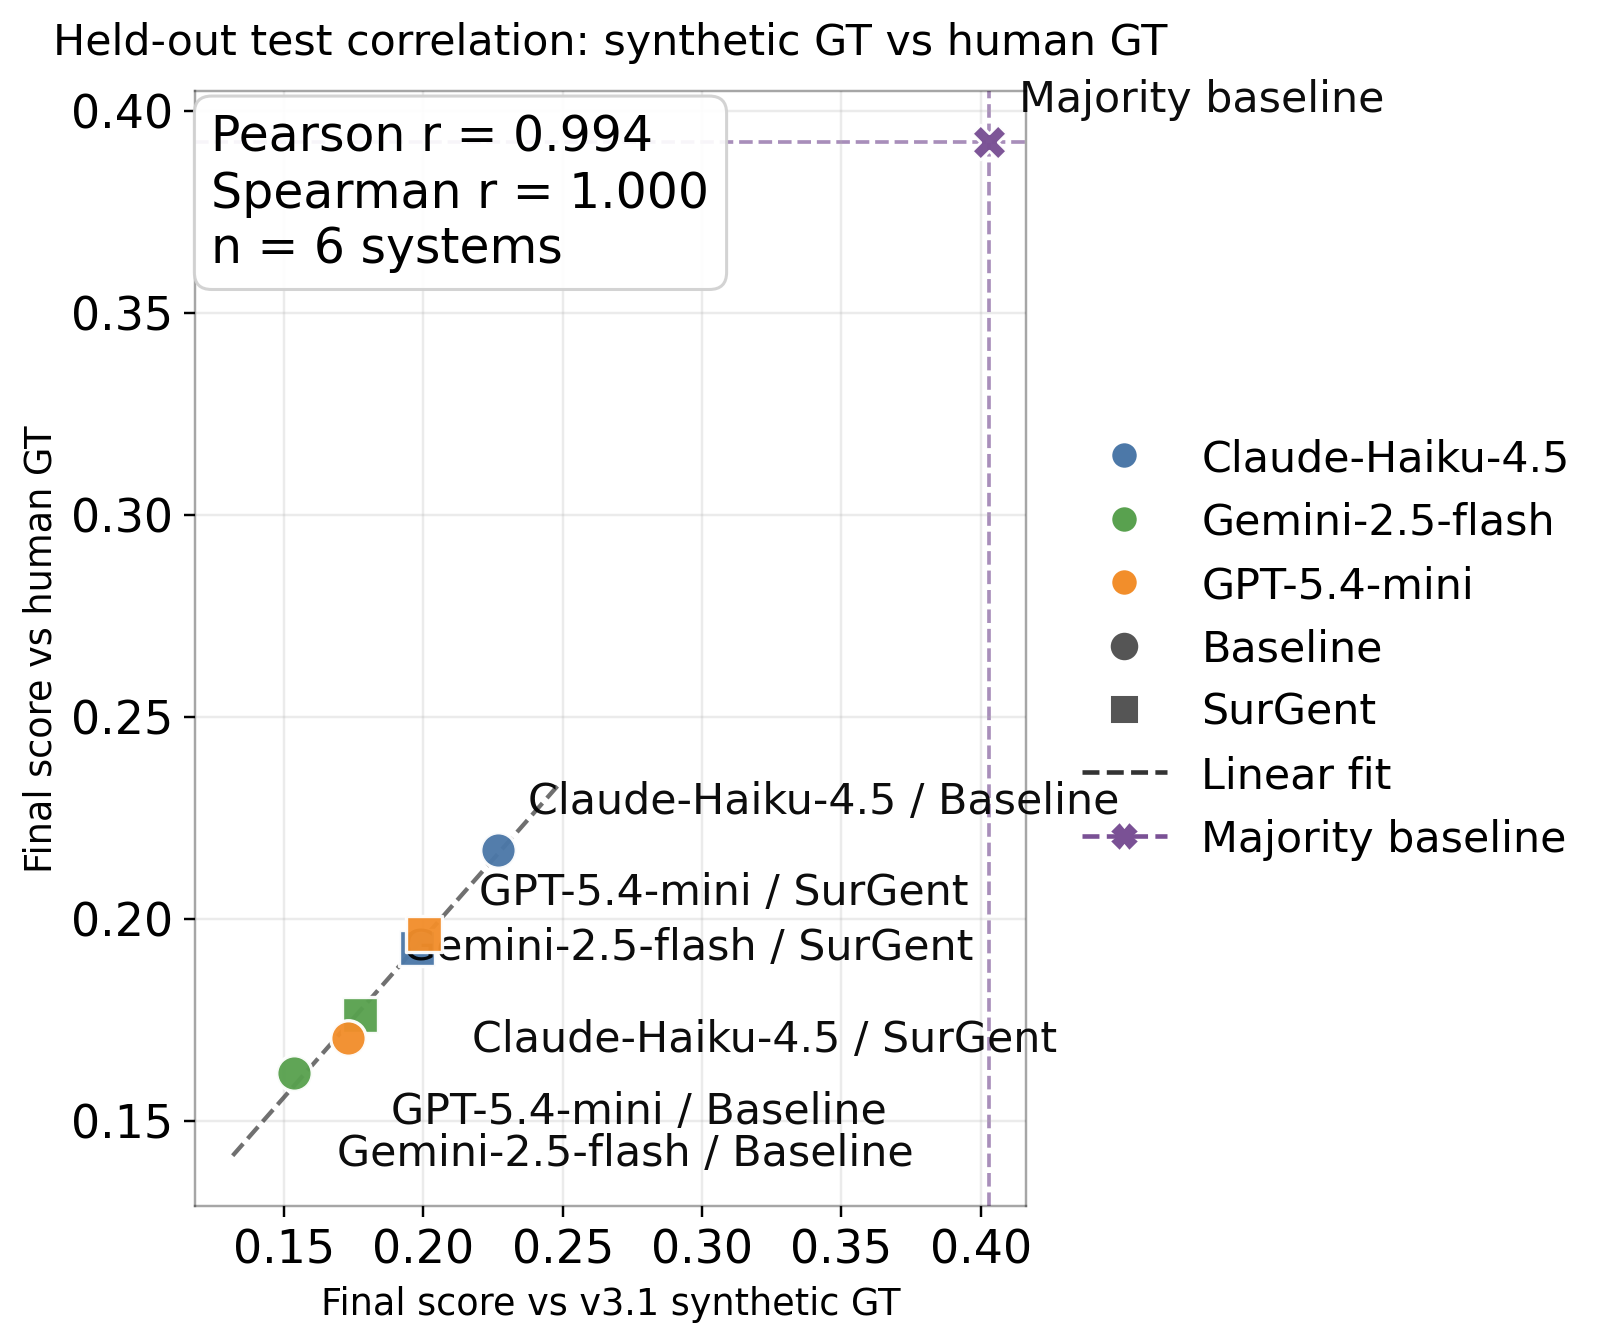

Pearson r: `0.9938`; Spearman r: `1.0000`.

,split_seed,split,n_systems,n_test_videos_in_seed_split,human_test_n_videos_available,synthetic_test_n_videos_available,common_test_n_videos_available,x_axis,y_axis,pearson_r,spearman_r
0,20260610,test,6,20,17,17,17,v3.1 structured LLM extract + tool fix synthet...,Human GT final score,0.993759,1.0


saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/test_six_system_human_synthetic_final_scores_seed20260610.csv
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/test_six_system_human_synthetic_final_score_points_seed20260610.csv
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/test_majority_component_human_synthetic_scores_seed20260610.csv
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/test_six_system_human_synthetic_final_score_correlation_seed20260610.csv
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/test_six_system_human_synthetic_final_score_scatter_seed20260610.png
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/test_six_system_human_synthetic_final_score_scatter_seed20260610.pdf
saved /mnt/md

In [13]:
display(Markdown('## Validation/Test Video Split: Method Selection Correlation'))

display(Markdown('The 30 videos are split once by video ID with a fixed seed: 10 validation videos and 20 test videos. Validation is used to inspect F1 as a function of IoU for the five data-generation/extraction methods. Test performance is summarized by the final score: mean(left/exact, right/medium, camera/coarse), with each component averaged over IoU thresholds.'))

import numpy as np
from matplotlib.lines import Line2D

SPLIT_SEED = 20260610
rng = random.Random(SPLIT_SEED)

split_entries = [
    {
        'id': 'description',
        'method': 'description_only',
        'method_label': 'Description',
        'results_map': spec_results_map,
    },
    {
        'id': 'hint',
        'method': 'hint_questions',
        'method_label': 'Hint',
        'results_map': spec_results_map,
    },
    {
        'id': 'structured_deterministic',
        'method': 'structured_prediction_deterministic',
        'method_label': 'Structured deterministic',
        'results_map': spec_results_map,
    },
    {
        'id': 'structured_llm_extract',
        'method': 'structured_prediction',
        'method_label': 'Structured LLM extract',
        'results_map': spec_results_map,
    },
    {
        'id': 'structured_llm_extract_tool_fix',
        'method': 'structured_prediction',
        'method_label': 'Structured LLM extract + tool fix',
        'results_map': {
            normalize_method(method): rows
            for method, rows in json.loads(
                (ROOT_DIR / 'notebooks/artifacts/qwen3.5_audit_v11_seg_extract_spec_eval_cvsctx_v3_1/spec_eval_results.json').read_text()
            ).items()
        },
    },
]

split_actors = ['left', 'right', 'camera']
split_granularities = ['coarse', 'medium', 'exact']
final_components = [('left', 'exact'), ('right', 'medium'), ('camera', 'coarse')]
BOOTSTRAP_N = 1000

all_split_videos = sorted({
    detail['video_id']
    for entry in split_entries
    for rows in [entry['results_map'].get(entry['method'], [])]
    for row in rows
    for detail in row.get('details', [])
})
assert len(all_split_videos) == 30, f'Expected 30 videos, got {len(all_split_videos)}'
shuffled_videos = all_split_videos[:]
rng.shuffle(shuffled_videos)
validation_videos = set(shuffled_videos[:10])
test_videos = set(shuffled_videos[10:])
assert len(validation_videos) == 10 and len(test_videos) == 20 and not (validation_videos & test_videos)

split_df = pd.DataFrame([
    {'split_seed': SPLIT_SEED, 'split': 'validation' if video_id in validation_videos else 'test', 'video_id': video_id}
    for video_id in all_split_videos
]).sort_values(['split', 'video_id']).reset_index(drop=True)
split_csv = OUT_DIR / 'validation_test_video_split_seed20260610.csv'
split_df.to_csv(split_csv, index=False)
display(Markdown(f'Validation videos: {len(validation_videos)}; test videos: {len(test_videos)}; seed: `{SPLIT_SEED}`'))
display(split_df)


def mean_f1_for_filter(results_map, method, video_ids, *, actor=None, granularity=None, iou=None):
    row_means = []
    for row in results_map.get(method, []):
        if actor is not None and row.get('actor') != actor:
            continue
        if granularity is not None and row.get('granularity') != granularity:
            continue
        if iou is not None and abs(float(row.get('iou')) - float(iou)) > 1e-9:
            continue
        values = [float(detail['f1']) for detail in row.get('details', []) if detail.get('video_id') in video_ids]
        if values:
            row_means.append(float(np.mean(values)))
    return float(np.mean(row_means)) if row_means else np.nan

available_ious = sorted({
    float(row.get('iou'))
    for entry in split_entries
    for row in entry['results_map'].get(entry['method'], [])
    if row.get('actor') in split_actors and row.get('granularity') in split_granularities
})

validation_iou_rows = []
for entry in split_entries:
    for iou in available_ious:
        validation_iou_rows.append({
            'split_seed': SPLIT_SEED,
            'split': 'validation',
            'method_id': entry['id'],
            'method': entry['method'],
            'method_label': entry['method_label'],
            'iou': iou,
            'f1': mean_f1_for_filter(
                entry['results_map'],
                entry['method'],
                validation_videos,
                iou=iou,
            ),
        })

validation_iou_df = pd.DataFrame(validation_iou_rows)
validation_iou_csv = OUT_DIR / 'validation_f1_by_iou_seed20260610.csv'
validation_iou_df.to_csv(validation_iou_csv, index=False)
display(Markdown('### Validation F1 by IoU'))
display(validation_iou_df.pivot_table(index='method_label', columns='iou', values='f1').reindex([entry['method_label'] for entry in split_entries]))

fig, ax = plt.subplots(figsize=(12.8, 7.0))
x = np.arange(len(available_ious))
bar_width = 0.14
offsets = [idx - (len(split_entries) - 1) / 2 for idx in range(len(split_entries))]
for idx, entry in enumerate(split_entries):
    sub = validation_iou_df[validation_iou_df['method_id'].eq(entry['id'])].set_index('iou').reindex(available_ious)
    values = sub['f1'].astype(float).tolist()
    ypos = x + offsets[idx] * bar_width
    bars = ax.barh(
        ypos,
        values,
        height=bar_width,
        label=entry['method_label'],
        color=slide_colors.get(entry['id']),
        edgecolor='white',
        linewidth=0.8,
    )
    for rect, value in zip(bars, values):
        if not np.isfinite(value):
            continue
        ax.text(value + 0.012, rect.get_y() + rect.get_height() / 2, f'{value:.2f}', ha='left', va='center', fontsize=13)
ax.set_yticks(x)
ax.set_yticklabels([f'{iou:g}' for iou in available_ious], fontsize=15)
ax.set_ylabel('IoU threshold', fontsize=17)
ax.set_xlabel('Validation F1', fontsize=17)
ax.set_title('Validation F1 by IoU Threshold', fontsize=20, pad=18)
ax.set_xlim(0, max(0.7, validation_iou_df['f1'].max() + 0.08))
ax.grid(axis='x', linestyle='--', alpha=0.25)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(ncols=3, frameon=False, loc='upper center', bbox_to_anchor=(0.5, 1.16), fontsize=14)
plt.tight_layout()
validation_iou_png = OUT_DIR / 'validation_f1_by_iou_seed20260610.png'
validation_iou_pdf = OUT_DIR / 'validation_f1_by_iou_seed20260610.pdf'
fig.savefig(validation_iou_png, dpi=300, bbox_inches='tight')
fig.savefig(validation_iou_pdf, bbox_inches='tight')
print('saved', validation_iou_png)
print('saved', validation_iou_pdf)
display(__import__('IPython.display', fromlist=['Image']).Image(filename=str(validation_iou_png)))
plt.show()

# Final scatter: six CVS systems evaluated against human GT and v3.1 structured LLM extract + tool-fix synthetic GT.
# The scatter correlates score-vs-synthetic-GT with score-vs-human-GT on the held-out test videos.
HUMAN_ONSET_DETAILS = ROOT_DIR / 'metrics_cvs_act_v1_onset_pointwise/onset_pointwise_details.csv'
SYNTHETIC_ONSET_DETAILS = ROOT_DIR / 'metrics_cvs_act_v1_onset_pointwise/notebook_plots/model_compare_two_axes/synthetic_onset_pointwise/onset_pointwise_details.csv'
human_details = pd.read_csv(HUMAN_ONSET_DETAILS, low_memory=False)
synthetic_details = pd.read_csv(SYNTHETIC_ONSET_DETAILS, low_memory=False)
human_details['video_id_str'] = human_details['video_id'].astype(str)
synthetic_details['video_id_str'] = synthetic_details['video_id'].astype(str)

six_model_order = ['claude', 'gemini', 'gpt']
six_variant_order = ['Baseline default', 'SurGent default']
six_model_display_names = {
    'claude': 'Claude-Haiku-4.5',
    'gemini': 'Gemini-2.5-flash',
    'gpt': 'GPT-5.4-mini',
}
six_variant_display_names = {
    'Baseline default': 'Baseline',
    'SurGent default': 'SurGent',
}
model_color_map = {'claude': '#4C78A8', 'gemini': '#59A14F', 'gpt': '#F28E2B'}
variant_marker_map = {'Baseline default': 'o', 'SurGent default': 's'}

# Keep the original 30-video seed split. Score only videos present in each GT table.
human_available_videos = set(human_details['video_id'].dropna().astype(str).unique())
synthetic_available_videos = set(synthetic_details['video_id'].dropna().astype(str).unique())
human_test_scored_videos = test_videos & human_available_videos
synthetic_test_scored_videos = test_videos & synthetic_available_videos
common_test_scored_videos = test_videos & human_available_videos & synthetic_available_videos


def bool_value(value):
    if isinstance(value, bool):
        return value
    text = str(value).strip().lower()
    if text in {'true', '1', 'yes'}:
        return True
    if text in {'false', '0', 'no', '', 'nan', 'none'}:
        return False
    return bool(value)


def local_multiclass_macro_f1(y_true, y_pred):
    labels = sorted(set(y_true) | set(y_pred))
    if not labels:
        return np.nan
    scores = []
    for label in labels:
        tp = sum((t == label) and (p == label) for t, p in zip(y_true, y_pred))
        fp = sum((t != label) and (p == label) for t, p in zip(y_true, y_pred))
        fn = sum((t == label) and (p != label) for t, p in zip(y_true, y_pred))
        denom = 2 * tp + fp + fn
        scores.append((2 * tp / denom) if denom else 0.0)
    return float(np.mean(scores))


def conditional_label_rows(df, video_ids, model_short, variant_label, actor):
    video_set = {str(video_id) for video_id in video_ids}
    if not video_set:
        return df.iloc[0:0].copy()
    sub = df[
        df['video_id_str'].isin(video_set)
        & df['model_short'].eq(model_short)
        & df['variant_label'].eq(variant_label)
        & df['clip_level'].eq('coarse')
        & df['point_source'].eq('coarse_actor_onset')
        & df['actor'].eq(actor)
    ].copy()
    if sub.empty:
        return sub
    return sub[
        sub['gt_present'].map(bool_value)
        & ~sub['gt_presence_excluded_uncertain'].map(bool_value)
        & ~sub['gt_presence_unknown'].map(bool_value)
    ].copy()


def macro_f1_from_rows(rows, granularity):
    gt_col = f'gt_label_resolved_{granularity}'
    pred_col = f'pred_label_{granularity}'
    usable = rows.dropna(subset=[gt_col, pred_col])
    if usable.empty:
        return np.nan, 0
    y_true = usable[gt_col].astype(str).tolist()
    y_pred = usable[pred_col].astype(str).tolist()
    return local_multiclass_macro_f1(y_true, y_pred), len(usable)


def conditional_label_macro_f1_subset(df, video_ids, model_short, variant_label, actor, granularity):
    rows = conditional_label_rows(df, video_ids, model_short, variant_label, actor)
    if rows.empty:
        return np.nan, 0
    return macro_f1_from_rows(rows, granularity)


def confusion_count_rows(y_true, y_pred):
    rows = []
    for label in sorted(set(y_true) | set(y_pred)):
        tp = sum((t == label) and (p == label) for t, p in zip(y_true, y_pred))
        fp = sum((t != label) and (p == label) for t, p in zip(y_true, y_pred))
        fn = sum((t == label) and (p != label) for t, p in zip(y_true, y_pred))
        rows.append({'label': label, 'tp': tp, 'fp': fp, 'fn': fn})
    return rows


def conditional_label_video_counts(df, video_ids, model_short, variant_label, actor, granularity):
    rows = conditional_label_rows(df, video_ids, model_short, variant_label, actor)
    if rows.empty:
        return pd.DataFrame(columns=['video_id', 'component', 'label', 'tp', 'fp', 'fn'])
    gt_col = f'gt_label_resolved_{granularity}'
    pred_col = f'pred_label_{granularity}'
    usable = rows.dropna(subset=[gt_col, pred_col])
    if usable.empty:
        return pd.DataFrame(columns=['video_id', 'component', 'label', 'tp', 'fp', 'fn'])
    component = f'{actor}_{granularity}'
    per_video = []
    for video_id, video_rows in usable.groupby('video_id_str', sort=True):
        y_true = video_rows[gt_col].astype(str).tolist()
        y_pred = video_rows[pred_col].astype(str).tolist()
        for count_row in confusion_count_rows(y_true, y_pred):
            per_video.append({'video_id': video_id, 'component': component, **count_row})
    return pd.DataFrame(per_video)


def six_system_component_scores(details_df, video_ids, model_short, variant_label):
    component_scores = {}
    component_ns = {}
    values = []
    for actor, granularity in final_components:
        score, n_rows = conditional_label_macro_f1_subset(
            details_df,
            video_ids,
            model_short,
            variant_label,
            actor,
            granularity,
        )
        key = f'{actor}_{granularity}'
        component_scores[key] = score
        component_ns[f'{key}_n'] = n_rows
        values.append(score)
    return component_scores, component_ns, float(np.nanmean(values)), int(np.isfinite(values).sum())


def six_system_video_count_table(details_df, video_ids, model_short, variant_label):
    pieces = [
        conditional_label_video_counts(details_df, video_ids, model_short, variant_label, actor, granularity)
        for actor, granularity in final_components
    ]
    pieces = [piece for piece in pieces if not piece.empty]
    return pd.concat(pieces, ignore_index=True) if pieces else pd.DataFrame(columns=['video_id', 'component', 'label', 'tp', 'fp', 'fn'])


def component_macro_f1_from_counts(counts):
    if counts.empty:
        return np.nan
    grouped = counts.groupby('label', as_index=False)[['tp', 'fp', 'fn']].sum()
    denom = 2 * grouped['tp'] + grouped['fp'] + grouped['fn']
    scores = (2 * grouped['tp'] / denom).where(denom > 0)
    scores = scores.dropna()
    return float(scores.mean()) if len(scores) else np.nan


def final_score_from_count_table(count_table):
    component_scores = []
    component_order = [f'{actor}_{granularity}' for actor, granularity in final_components]
    for component in component_order:
        component_scores.append(component_macro_f1_from_counts(count_table[count_table['component'].eq(component)]))
    return float(np.nanmean(component_scores)) if np.isfinite(component_scores).any() else np.nan


def build_video_count_arrays(video_count_table):
    video_ids = sorted(video_count_table['video_id'].astype(str).unique())
    video_index = {video_id: idx for idx, video_id in enumerate(video_ids)}
    component_order = [f'{actor}_{granularity}' for actor, granularity in final_components]
    arrays = {}
    for component in component_order:
        comp = video_count_table[video_count_table['component'].eq(component)]
        labels = sorted(comp['label'].astype(str).unique()) if not comp.empty else []
        if not labels:
            arrays[component] = None
            continue
        label_index = {label: idx for idx, label in enumerate(labels)}
        tp = np.zeros((len(video_ids), len(labels)), dtype=float)
        fp = np.zeros_like(tp)
        fn = np.zeros_like(tp)
        for row in comp.itertuples(index=False):
            i = video_index[str(row.video_id)]
            j = label_index[str(row.label)]
            tp[i, j] += float(row.tp)
            fp[i, j] += float(row.fp)
            fn[i, j] += float(row.fn)
        arrays[component] = (tp, fp, fn)
    return video_ids, arrays


def macro_f1_from_summed_counts(tp_sum, fp_sum, fn_sum):
    denom = 2 * tp_sum + fp_sum + fn_sum
    valid = denom > 0
    if not np.any(valid):
        return np.nan
    return float(np.mean((2 * tp_sum[valid]) / denom[valid]))


def bootstrap_cached_final_score_se(video_count_table, seed, n_boot=BOOTSTRAP_N):
    if video_count_table.empty:
        return np.nan
    video_ids, arrays = build_video_count_arrays(video_count_table)
    if len(video_ids) < 2:
        return np.nan
    rng = np.random.default_rng(seed)
    scores = []
    for _ in range(n_boot):
        sampled = rng.integers(0, len(video_ids), size=len(video_ids))
        component_scores = []
        for counts in arrays.values():
            if counts is None:
                component_scores.append(np.nan)
                continue
            tp, fp, fn = counts
            component_scores.append(macro_f1_from_summed_counts(
                tp[sampled, :].sum(axis=0),
                fp[sampled, :].sum(axis=0),
                fn[sampled, :].sum(axis=0),
            ))
        scores.append(float(np.nanmean(component_scores)))
    scores = np.asarray(scores, dtype=float)
    scores = scores[np.isfinite(scores)]
    return float(np.std(scores, ddof=1)) if len(scores) > 1 else np.nan


def score_six_systems_against_gt(details_df, video_ids, gt_source_label):
    rows = []
    gt_seed_offset = 0 if gt_source_label == 'Human GT' else 100_000
    for model_index, model_short in enumerate(six_model_order):
        for variant_index, variant_label in enumerate(six_variant_order):
            component_scores, component_ns, final_score, n_components = six_system_component_scores(
                details_df,
                video_ids,
                model_short,
                variant_label,
            )
            video_count_table = six_system_video_count_table(
                details_df,
                video_ids,
                model_short,
                variant_label,
            )
            final_score_se = bootstrap_cached_final_score_se(
                video_count_table,
                SPLIT_SEED + gt_seed_offset + model_index * 100 + variant_index,
            )
            rows.append({
                'split_seed': SPLIT_SEED,
                'split': 'test',
                'gt_source': gt_source_label,
                'model_short': model_short,
                'model_name': six_model_display_names[model_short],
                'variant_label': variant_label,
                'system_label': f'{six_model_display_names[model_short]} / {six_variant_display_names[variant_label]}',
                'n_videos_in_split': len(video_ids),
                **component_scores,
                **component_ns,
                'final_score': final_score,
                'final_score_se': final_score_se,
                'n_components': n_components,
            })
    return pd.DataFrame(rows)


def majority_label_macro_f1_subset(df, video_ids, actor, granularity):
    sub = df[
        df['video_id'].astype(str).isin(video_ids)
        & df['clip_level'].eq('coarse')
        & df['point_source'].eq('coarse_actor_onset')
        & df['actor'].eq(actor)
    ].copy()
    if sub.empty:
        return np.nan, '', 0
    usable = sub[
        sub['gt_present'].map(bool_value)
        & ~sub['gt_presence_excluded_uncertain'].map(bool_value)
        & ~sub['gt_presence_unknown'].map(bool_value)
    ].copy()
    if usable.empty:
        return np.nan, '', 0
    gt_col = f'gt_label_resolved_{granularity}'
    usable = usable.dropna(subset=[gt_col])
    if usable.empty:
        return np.nan, '', 0
    y_true = usable[gt_col].astype(str).tolist()
    majority_label = usable[gt_col].astype(str).mode().iat[0]
    y_pred = [majority_label] * len(y_true)
    return local_multiclass_macro_f1(y_true, y_pred), majority_label, len(usable)


def majority_component_scores_against_gt(details_df, video_ids, gt_source_label):
    rows = []
    values = []
    for actor, granularity in final_components:
        score, majority_label, n_rows = majority_label_macro_f1_subset(details_df, video_ids, actor, granularity)
        component = f'{actor}_{granularity}'
        rows.append({
            'split_seed': SPLIT_SEED,
            'split': 'test',
            'gt_source': gt_source_label,
            'component': component,
            'actor': actor,
            'granularity': granularity,
            'majority_label': majority_label,
            'majority_label_macro_f1': score,
            'n': n_rows,
            'n_videos_in_split': len(video_ids),
        })
        values.append(score)
    rows.append({
        'split_seed': SPLIT_SEED,
        'split': 'test',
        'gt_source': gt_source_label,
        'component': 'final_score',
        'actor': 'aggregate',
        'granularity': 'final',
        'majority_label': '',
        'majority_label_macro_f1': float(np.nanmean(values)),
        'n': int(sum(row['n'] for row in rows if row['component'] != 'final_score')),
        'n_videos_in_split': len(video_ids),
    })
    return pd.DataFrame(rows)

six_human_score_df = score_six_systems_against_gt(human_details, common_test_scored_videos, 'Human GT')
six_synthetic_score_df = score_six_systems_against_gt(synthetic_details, common_test_scored_videos, 'v3.1 structured LLM extract + tool fix synthetic GT')
six_human_synthetic_score_df = pd.concat([six_human_score_df, six_synthetic_score_df], ignore_index=True)
six_human_synthetic_score_csv = OUT_DIR / 'test_six_system_human_synthetic_final_scores_seed20260610.csv'
six_human_synthetic_score_df.to_csv(six_human_synthetic_score_csv, index=False)

majority_human_score_df = majority_component_scores_against_gt(human_details, common_test_scored_videos, 'Human GT')
majority_synthetic_score_df = majority_component_scores_against_gt(synthetic_details, common_test_scored_videos, 'v3.1 structured LLM extract + tool fix synthetic GT')
majority_component_score_df = pd.concat([majority_human_score_df, majority_synthetic_score_df], ignore_index=True)
majority_component_score_csv = OUT_DIR / 'test_majority_component_human_synthetic_scores_seed20260610.csv'
majority_component_score_df.to_csv(majority_component_score_csv, index=False)

majority_component_wide = majority_component_score_df.pivot_table(
    index=['component', 'actor', 'granularity'],
    columns='gt_source',
    values='majority_label_macro_f1',
    aggfunc='first',
).reset_index()

six_human_synthetic_wide = six_human_synthetic_score_df.pivot_table(
    index=['model_short', 'model_name', 'variant_label', 'system_label'],
    columns='gt_source',
    values='final_score',
    aggfunc='first',
).reset_index()
six_human_synthetic_wide['synthetic_minus_human'] = (
    six_human_synthetic_wide['v3.1 structured LLM extract + tool fix synthetic GT'] - six_human_synthetic_wide['Human GT']
)
six_human_synthetic_points_csv = OUT_DIR / 'test_six_system_human_synthetic_final_score_points_seed20260610.csv'
six_human_synthetic_wide.to_csv(six_human_synthetic_points_csv, index=False)

x = six_human_synthetic_wide['v3.1 structured LLM extract + tool fix synthetic GT'].astype(float)
y = six_human_synthetic_wide['Human GT'].astype(float)
pearson_r = x.corr(y, method='pearson') if len(six_human_synthetic_wide) >= 3 and x.nunique() > 1 and y.nunique() > 1 else np.nan
spearman_r = x.corr(y, method='spearman') if len(six_human_synthetic_wide) >= 3 and x.nunique() > 1 and y.nunique() > 1 else np.nan
six_human_synthetic_corr_summary = pd.DataFrame([{
    'split_seed': SPLIT_SEED,
    'split': 'test',
    'n_systems': len(six_human_synthetic_wide),
    'n_test_videos_in_seed_split': len(test_videos),
    'human_test_n_videos_available': len(human_test_scored_videos),
    'synthetic_test_n_videos_available': len(synthetic_test_scored_videos),
    'common_test_n_videos_available': len(common_test_scored_videos),
    'x_axis': 'v3.1 structured LLM extract + tool fix synthetic GT final score',
    'y_axis': 'Human GT final score',
    'pearson_r': pearson_r,
    'spearman_r': spearman_r,
}])
six_human_synthetic_corr_csv = OUT_DIR / 'test_six_system_human_synthetic_final_score_correlation_seed20260610.csv'
six_human_synthetic_corr_summary.to_csv(six_human_synthetic_corr_csv, index=False)

display(Markdown('### Test Split: Six-system Synthetic-vs-Human Final Score Correlation'))
display(Markdown(f'Final score is `mean(left/exact, right/medium, camera/coarse)`. Both axes use the same held-out videos from the seeded test split that are available in both GT tables: {len(common_test_scored_videos)} of {len(test_videos)} test videos. The dashed crosshair shows a single aggregate majority-label null: left rows always predict the left/exact majority label, right rows the right/medium majority label, camera rows the camera/coarse majority label, then the three component F1s are averaged into the final score.'))
display(six_human_synthetic_score_df.sort_values(['gt_source', 'model_short', 'variant_label']).style.format({
    'left_exact': '{:.3f}',
    'right_medium': '{:.3f}',
    'camera_coarse': '{:.3f}',
    'final_score': '{:.3f}',
    'final_score_se': '{:.3f}',
}, na_rep=''))
display(majority_component_score_df.sort_values(['gt_source', 'component']).style.format({
    'majority_label_macro_f1': '{:.3f}',
}, na_rep=''))

def plot_six_system_final_score_bar(score_df, gt_source_label, title, stem):
    plot_df = score_df[score_df['gt_source'].eq(gt_source_label)].copy()
    plot_df['model_name'] = pd.Categorical(plot_df['model_name'], categories=[six_model_display_names[m] for m in six_model_order], ordered=True)
    plot_df = plot_df.sort_values(['model_name', 'variant_label'])
    majority_row = majority_component_score_df[
        majority_component_score_df['gt_source'].eq(gt_source_label)
        & majority_component_score_df['component'].eq('final_score')
    ]
    majority_score = float(majority_row['majority_label_macro_f1'].iloc[0]) if not majority_row.empty else np.nan

    fig, ax = plt.subplots(figsize=(12.8, 7.2))
    x_pos = np.arange(len(six_model_order))
    model_labels = [six_model_display_names[m] for m in six_model_order]
    bar_width = 0.34
    for offset, variant_label, color in [(-bar_width / 2, 'Baseline default', '#4C78A8'), (bar_width / 2, 'SurGent default', '#F28E2B')]:
        vals = []
        ses = []
        labels_n = []
        for model_short in six_model_order:
            row = plot_df[(plot_df['model_short'] == model_short) & (plot_df['variant_label'] == variant_label)]
            vals.append(float(row['final_score'].iloc[0]) if not row.empty else np.nan)
            ses.append(float(row['final_score_se'].iloc[0]) if not row.empty and pd.notna(row['final_score_se'].iloc[0]) else 0.0)
            labels_n.append(int(row['n_videos_in_split'].iloc[0]) if not row.empty else 0)
        bars = ax.barh(
            x_pos + offset,
            vals,
            height=bar_width,
            color=color,
            label=six_variant_display_names[variant_label],
            edgecolor='white',
            linewidth=0.8,
            xerr=ses,
            capsize=3,
            error_kw={'elinewidth': 1.0, 'capthick': 1.0},
        )
        for rect, val, se, n_videos in zip(bars, vals, ses, labels_n):
            if np.isfinite(val):
                ax.text(val + se + 0.006, rect.get_y() + rect.get_height() / 2, f'{val:.3f}  n={n_videos}', ha='left', va='center', fontsize=13)
    if np.isfinite(majority_score):
        ax.axvline(majority_score, color='#7A5195', linestyle='--', linewidth=1.5, label=f'Majority baseline ({majority_score:.3f})')
    ax.set_yticks(x_pos)
    ax.set_yticklabels(model_labels, fontsize=15)
    ax.set_xlabel('Final score', fontsize=17)
    ax.set_title(title, fontsize=20, pad=42)
    ymax = max(float(plot_df['final_score'].max()) if not plot_df.empty else 0, majority_score if np.isfinite(majority_score) else 0)
    ax.set_xlim(0, max(0.32, ymax + 0.07))
    ax.grid(axis='x', alpha=0.25)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(frameon=False, loc='lower center', bbox_to_anchor=(0.5, -0.24), ncols=3, fontsize=15)
    plt.tight_layout()
    png = OUT_DIR / f'{stem}.png'
    pdf = OUT_DIR / f'{stem}.pdf'
    fig.savefig(png, dpi=220, bbox_inches='tight')
    fig.savefig(pdf, bbox_inches='tight')
    plt.show()
    display(__import__('IPython.display', fromlist=['Image']).Image(filename=str(png)))
    return png, pdf


display(Markdown('### Held-out Split Final Score Bar Charts'))
display(Markdown('Each chart shows only the six baseline/SurGent systems on the seeded held-out test split; the dashed line is the aggregate majority-label baseline for that GT source.'))
human_bar_png, human_bar_pdf = plot_six_system_final_score_bar(
    six_human_synthetic_score_df,
    'Human GT',
    f'Human GT final score on held-out split ({len(common_test_scored_videos)} of {len(test_videos)} test videos)',
    'test_six_system_human_gt_final_score_bar_seed20260610',
)
synthetic_bar_png, synthetic_bar_pdf = plot_six_system_final_score_bar(
    six_human_synthetic_score_df,
    'v3.1 structured LLM extract + tool fix synthetic GT',
    f'Synthetic GT final score on held-out split ({len(common_test_scored_videos)} of {len(test_videos)} test videos)',
    'test_six_system_synthetic_gt_final_score_bar_seed20260610',
)

fig, ax = plt.subplots(figsize=(9.6, 6.4))
label_offsets = {
    ('claude', 'Baseline default'): (10, 12),
    ('claude', 'SurGent default'): (18, -34),
    ('gemini', 'Baseline default'): (14, -30),
    ('gemini', 'SurGent default'): (14, 18),
    ('gpt', 'Baseline default'): (14, -28),
    ('gpt', 'SurGent default'): (18, 10),
}
for _, row in six_human_synthetic_wide.iterrows():
    key = (row['model_short'], row['variant_label'])
    ax.scatter(
        row['v3.1 structured LLM extract + tool fix synthetic GT'],
        row['Human GT'],
        color=model_color_map.get(row['model_short'], '#777777'),
        marker=variant_marker_map.get(row['variant_label'], 'o'),
        s=135,
        edgecolor='white',
        linewidth=1.1,
        alpha=0.96,
        zorder=3,
    )
    ax.annotate(
        row['system_label'],
        (row['v3.1 structured LLM extract + tool fix synthetic GT'], row['Human GT']),
        xytext=label_offsets.get(key, (8, 6)),
        textcoords='offset points',
        fontsize=14,
        alpha=0.95,
    )
if len(six_human_synthetic_wide) >= 2 and x.nunique() > 1:
    m, b = np.polyfit(x, y, 1)
    x_pad = max(0.01, (float(x.max()) - float(x.min())) * 0.30)
    xs = np.linspace(float(x.min()) - x_pad, float(x.max()) + x_pad, 100)
    ax.plot(xs, m * xs + b, color='#333333', linewidth=1.4, linestyle='--', alpha=0.70, label='Linear fit')

majority_final_row = majority_component_wide[majority_component_wide['component'].eq('final_score')].iloc[0]
x_majority_final = majority_final_row.get('v3.1 structured LLM extract + tool fix synthetic GT')
y_majority_final = majority_final_row.get('Human GT')
majority_color = '#7A5195'
if not pd.isna(x_majority_final) and not pd.isna(y_majority_final):
    ax.axvline(float(x_majority_final), color=majority_color, linestyle='--', linewidth=1.2, alpha=0.65, zorder=1)
    ax.axhline(float(y_majority_final), color=majority_color, linestyle='--', linewidth=1.2, alpha=0.65, zorder=1)
    ax.scatter(
        float(x_majority_final),
        float(y_majority_final),
        marker='X',
        s=130,
        color=majority_color,
        edgecolor='white',
        linewidth=0.9,
        alpha=0.98,
        zorder=4,
    )
    ax.annotate(
        'Majority baseline',
        (float(x_majority_final), float(y_majority_final)),
        xytext=(10, 10),
        textcoords='offset points',
        fontsize=14,
        alpha=0.95,
    )
ax.set_xlabel('Final score vs v3.1 synthetic GT', fontsize=12)
ax.set_ylabel('Final score vs human GT', fontsize=12)
ax.set_title('Held-out test correlation: synthetic GT vs human GT', fontsize=14, pad=12)
ax.text(
    0.02,
    0.98,
    f'Pearson r = {pearson_r:.3f}\nSpearman r = {spearman_r:.3f}\nn = {len(six_human_synthetic_wide)} systems',
    transform=ax.transAxes,
    va='top',
    ha='left',
    fontsize=16,
    bbox=dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor='#D0D0D0', alpha=0.92),
)
legend_handles = []
for model_short, model_name in six_model_display_names.items():
    legend_handles.append(Line2D([0], [0], marker='o', color='w', label=model_name, markerfacecolor=model_color_map[model_short], markersize=9))
for variant_label, marker in variant_marker_map.items():
    legend_handles.append(Line2D([0], [0], marker=marker, color='#555555', label=six_variant_display_names[variant_label], markerfacecolor='#555555', linestyle='None', markersize=8))
legend_handles.append(Line2D([0], [0], color='#333333', linestyle='--', label='Linear fit'))
legend_handles.append(Line2D([0], [0], color=majority_color, linestyle='--', marker='X', label='Majority baseline', markersize=7))
ax.legend(handles=legend_handles, loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=14, ncols=1)
ax.grid(True, alpha=0.25)
for spine in ax.spines.values():
    spine.set_alpha(0.35)
plt.tight_layout(rect=[0, 0, 0.80, 1])
six_human_synthetic_scatter_png = OUT_DIR / 'test_six_system_human_synthetic_final_score_scatter_seed20260610.png'
six_human_synthetic_scatter_pdf = OUT_DIR / 'test_six_system_human_synthetic_final_score_scatter_seed20260610.pdf'
fig.savefig(six_human_synthetic_scatter_png, dpi=220, bbox_inches='tight')
fig.savefig(six_human_synthetic_scatter_pdf, bbox_inches='tight')
plt.show()
display(__import__('IPython.display', fromlist=['Image']).Image(filename=str(six_human_synthetic_scatter_png)))

display(Markdown(f'Pearson r: `{pearson_r:.4f}`; Spearman r: `{spearman_r:.4f}`.'))
display(six_human_synthetic_corr_summary)
for path in [six_human_synthetic_score_csv, six_human_synthetic_points_csv, majority_component_score_csv, six_human_synthetic_corr_csv, six_human_synthetic_scatter_png, six_human_synthetic_scatter_pdf, human_bar_png, human_bar_pdf, synthetic_bar_png, synthetic_bar_pdf]:
    print(f'saved {path}')

## Synthetic GT Final Score: 30 Human-GT Videos and Larger Baseline Runs

/mnt/md0/weiqiuy/surgent/.venv/lib/python3.12/site-packages/fuzzywuzzy/fuzz.py:11: UserWarning: Using slow pure-python SequenceMatcher. Install python-Levenshtein to remove this warning
  warnings.warn('Using slow pure-python SequenceMatcher. Install python-Levenshtein to remove this warning')


Baseline vs SurGent uses `30` requested human-GT videos and `90` synthetic GT records. Prediction coverage is `30`-`30` videos across the six systems.

,analysis,gt_source,method,variant,variant_label,model,model_name,system_label,n_videos,left_exact,right_medium,camera_coarse,left_exact_n,right_medium_n,camera_coarse_n,final_score,final_score_se,n_components,requested_video_set_n,synthetic_gt_records_n
0,baseline_vs_surgent_human30,v3.1 structured LLM extract + tool fix synthetic GT,cot_fixedk3_norecdescs_fmeta/claude-haiku-4-5-20251001/cvs_act_current_simple_v1,cot_fixedk3_norecdescs_fmeta,Baseline,claude-haiku-4-5-20251001,Claude-Haiku-4.5,Claude-Haiku-4.5 / Baseline,30,0.184,0.025,0.469,221,222,34,0.226,0.043,3,30,90
3,baseline_vs_surgent_human30,v3.1 structured LLM extract + tool fix synthetic GT,pref-cvs_arec_steps5_fixedk3_norecdescs_fmeta/claude-haiku-4-5-20251001/cvs_act_current_simple_v1,pref-cvs_arec_steps5_fixedk3_norecdescs_fmeta,SurGent,claude-haiku-4-5-20251001,Claude-Haiku-4.5,Claude-Haiku-4.5 / SurGent,30,0.187,0.033,0.382,221,222,34,0.201,0.024,3,30,90
2,baseline_vs_surgent_human30,v3.1 structured LLM extract + tool fix synthetic GT,cot_fixedk3_norecdescs_fmeta/gpt-5.4-mini/cvs_act_current_simple_v1,cot_fixedk3_norecdescs_fmeta,Baseline,gpt-5.4-mini,GPT-5.4-mini,GPT-5.4-mini / Baseline,30,0.043,0.032,0.424,221,222,34,0.166,0.014,3,30,90
5,baseline_vs_surgent_human30,v3.1 structured LLM extract + tool fix synthetic GT,pref-cvs_arec_steps5_fixedk3_norecdescs_fmeta/gpt-5.4-mini/cvs_act_current_simple_v1,pref-cvs_arec_steps5_fixedk3_norecdescs_fmeta,SurGent,gpt-5.4-mini,GPT-5.4-mini,GPT-5.4-mini / SurGent,30,0.069,0.033,0.460,221,222,34,0.188,0.023,3,30,90
1,baseline_vs_surgent_human30,v3.1 structured LLM extract + tool fix synthetic GT,cot_fixedk3_norecdescs_fmeta/gemini-2.5-flash/cvs_act_current_simple_v1,cot_fixedk3_norecdescs_fmeta,Baseline,gemini-2.5-flash,Gemini-2.5-flash,Gemini-2.5-flash / Baseline,30,0.083,0.033,0.320,221,222,34,0.145,0.019,3,30,90
4,baseline_vs_surgent_human30,v3.1 structured LLM extract + tool fix synthetic GT,pref-cvs_arec_steps5_fixedk3_norecdescs_fmeta/gemini-2.5-flash/cvs_act_current_simple_v1,pref-cvs_arec_steps5_fixedk3_norecdescs_fmeta,SurGent,gemini-2.5-flash,Gemini-2.5-flash,Gemini-2.5-flash / SurGent,30,0.100,0.038,0.292,221,222,34,0.143,0.025,3,30,90


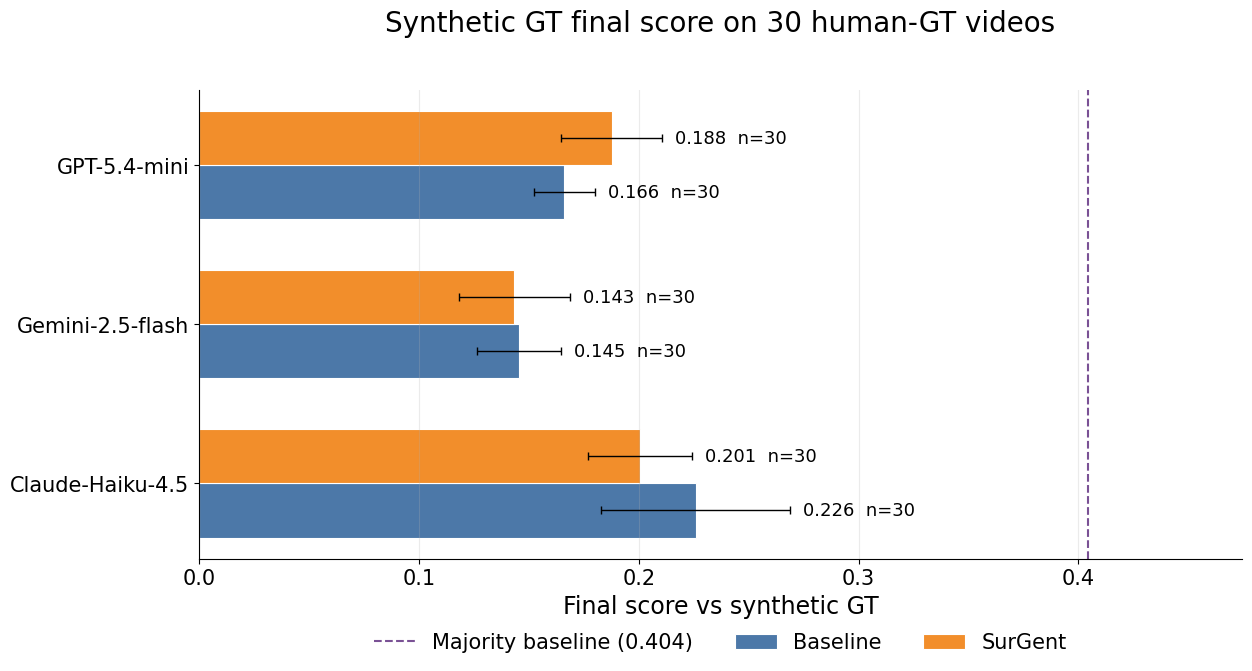

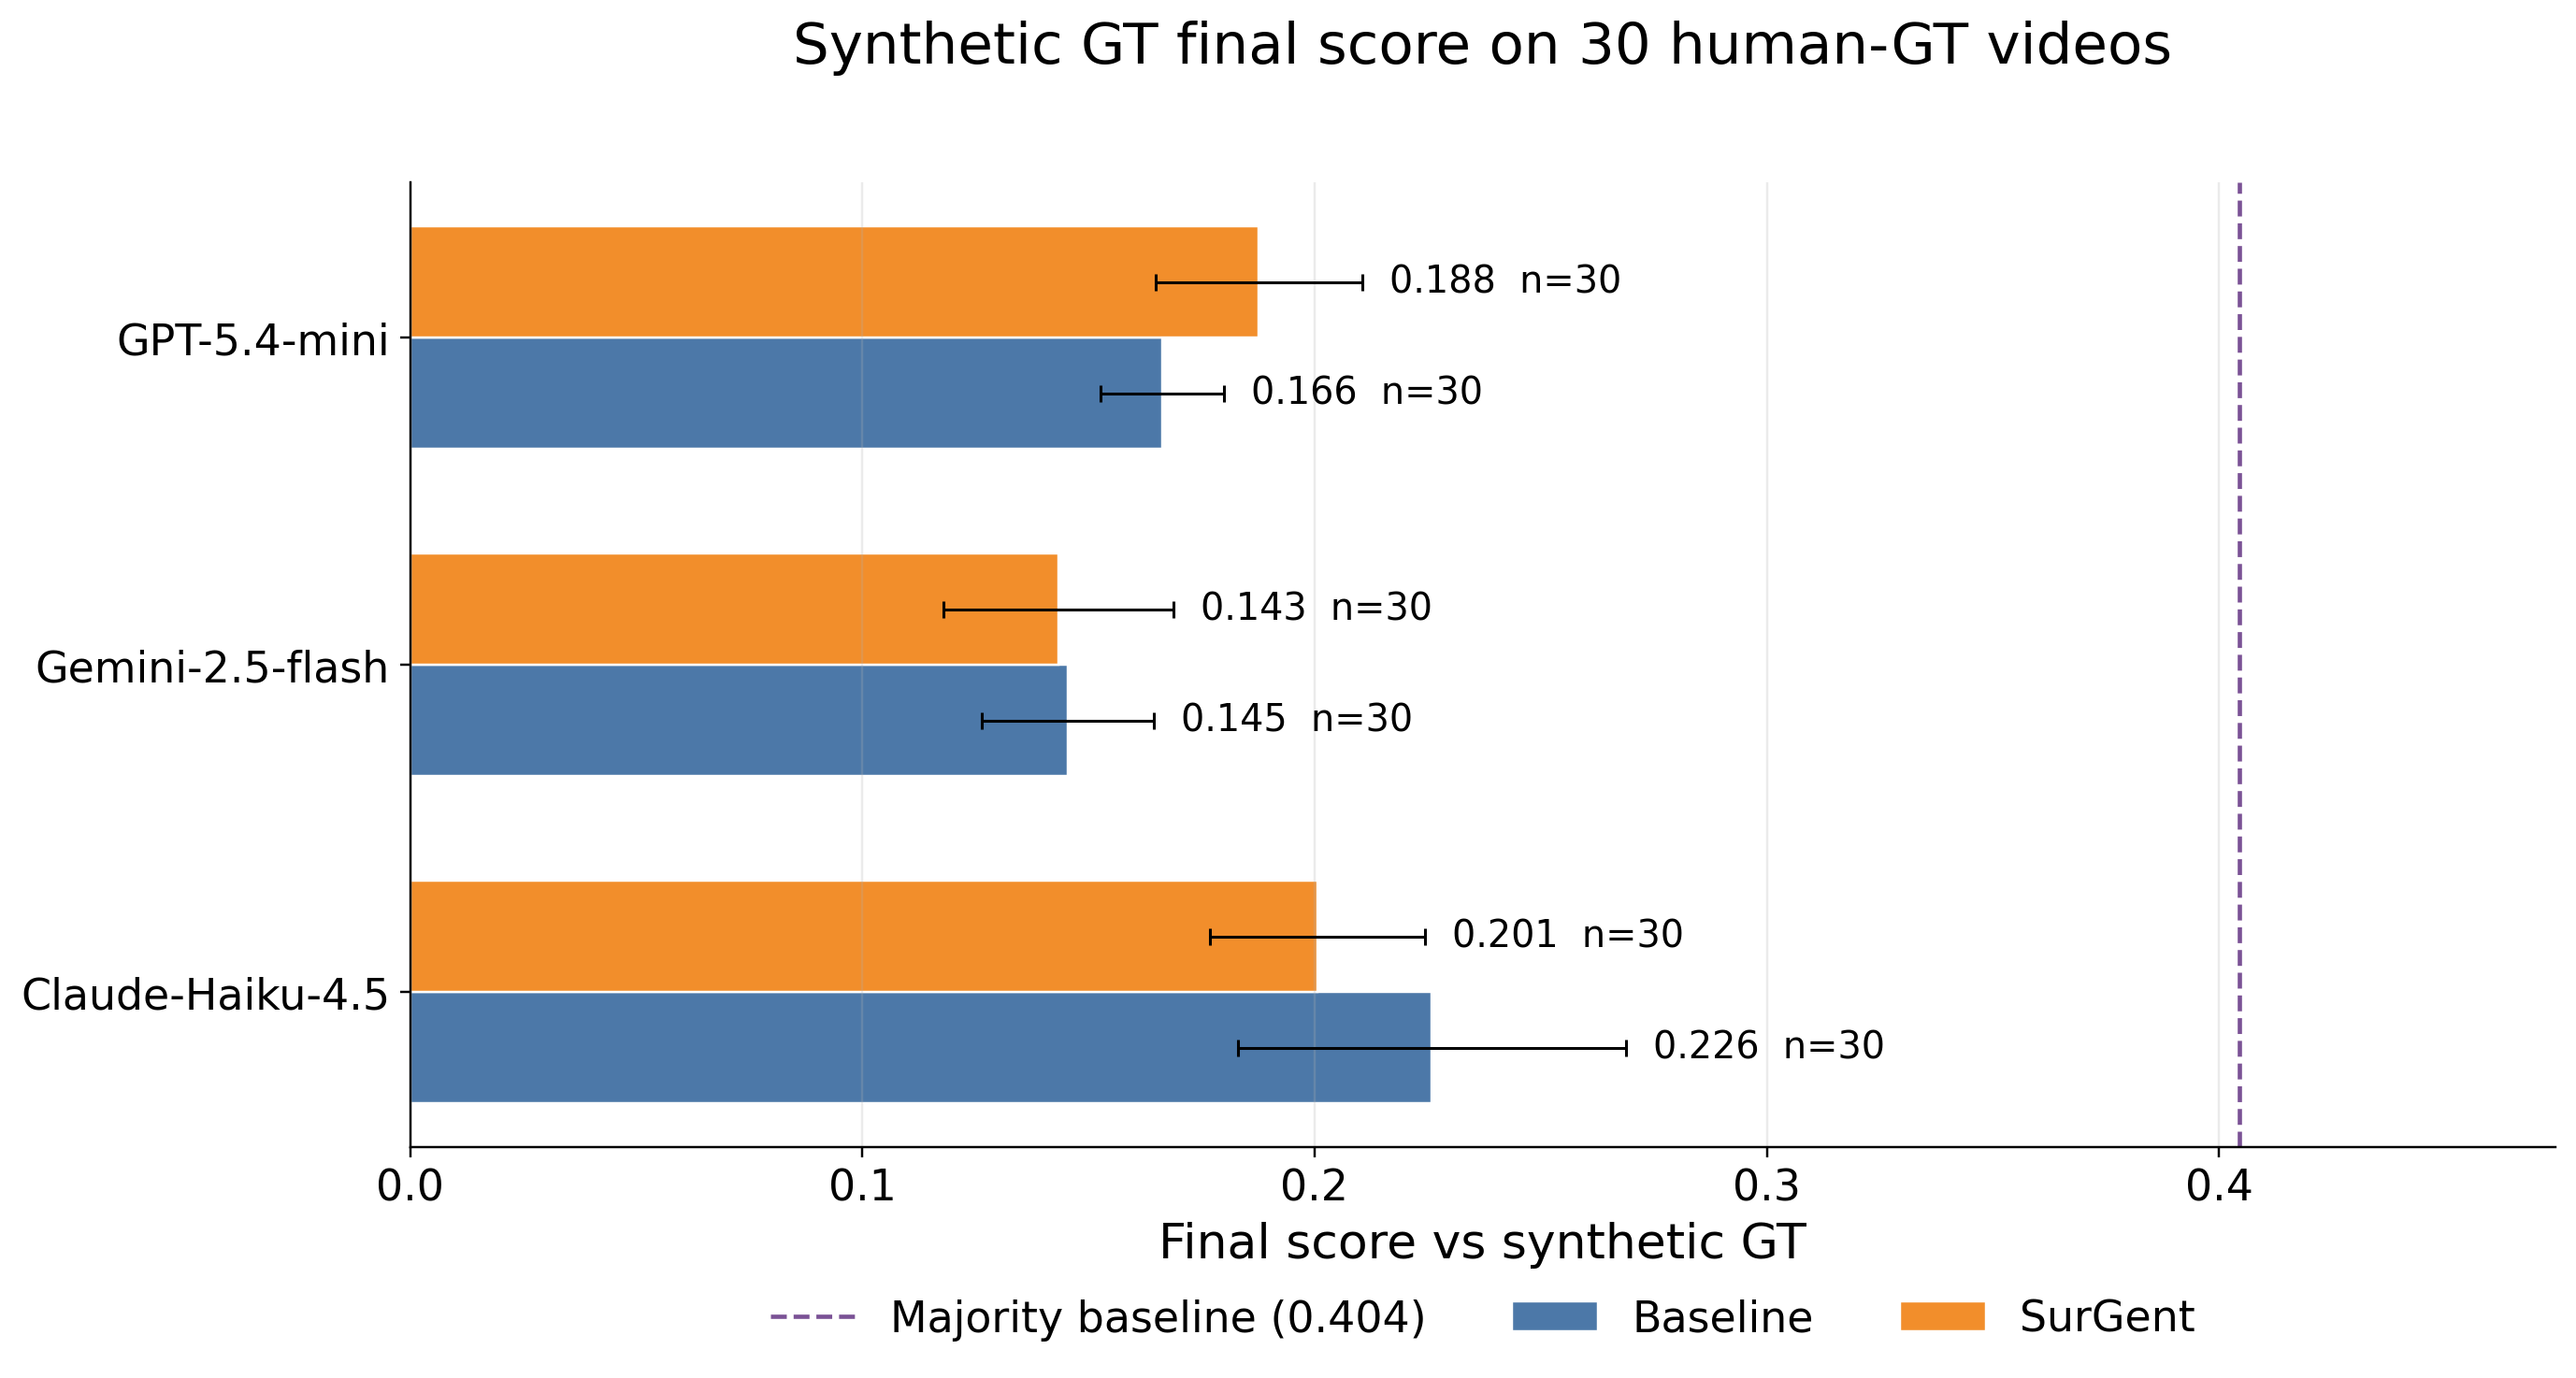

### Baseline-only larger synthetic-GT runs

This view uses the plain baseline method for Claude/Gemini/GPT on its available larger synthetic-test prediction videos. Coverage is `65`-`65` videos.

,analysis,gt_source,method,variant,variant_label,model,model_name,system_label,n_videos,left_exact,right_medium,camera_coarse,left_exact_n,right_medium_n,camera_coarse_n,final_score,final_score_se,n_components,synthetic_gt_records_n
9,baseline_only_larger_synthetic,v3.1 structured LLM extract + tool fix synthetic GT,cot_fixedk3_norecdescs_fmeta/claude-haiku-4-5-20251001/cvs_act_current_simple_v1,cot_fixedk3_norecdescs_fmeta,Baseline,claude-haiku-4-5-20251001,Claude-Haiku-4.5,Claude-Haiku-4.5 / Baseline,65,0.142,0.016,0.461,466,458,89,0.206,0.006,3,481
11,baseline_only_larger_synthetic,v3.1 structured LLM extract + tool fix synthetic GT,cot_fixedk3_norecdescs_fmeta/gpt-5.4-mini/cvs_act_current_simple_v1,cot_fixedk3_norecdescs_fmeta,Baseline,gpt-5.4-mini,GPT-5.4-mini,GPT-5.4-mini / Baseline,65,0.022,0.021,0.390,466,458,89,0.144,0.009,3,481
10,baseline_only_larger_synthetic,v3.1 structured LLM extract + tool fix synthetic GT,cot_fixedk3_norecdescs_fmeta/gemini-2.5-flash/cvs_act_current_simple_v1,cot_fixedk3_norecdescs_fmeta,Baseline,gemini-2.5-flash,Gemini-2.5-flash,Gemini-2.5-flash / Baseline,65,0.070,0.027,0.270,466,458,89,0.123,0.014,3,481


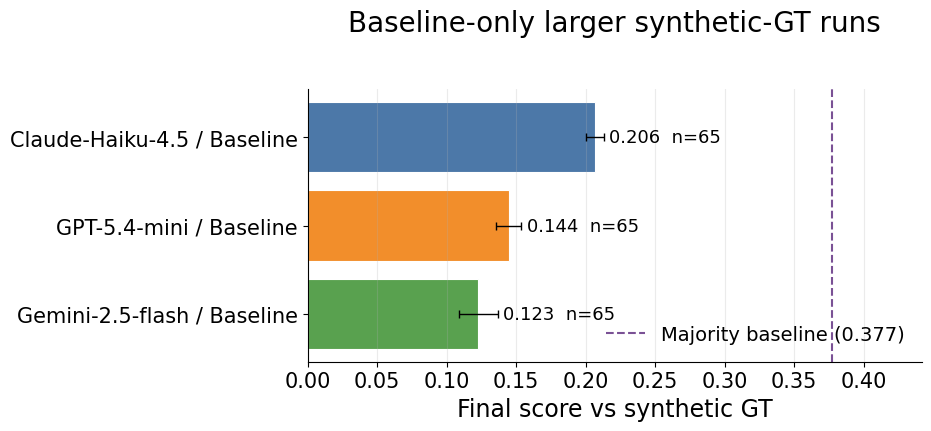

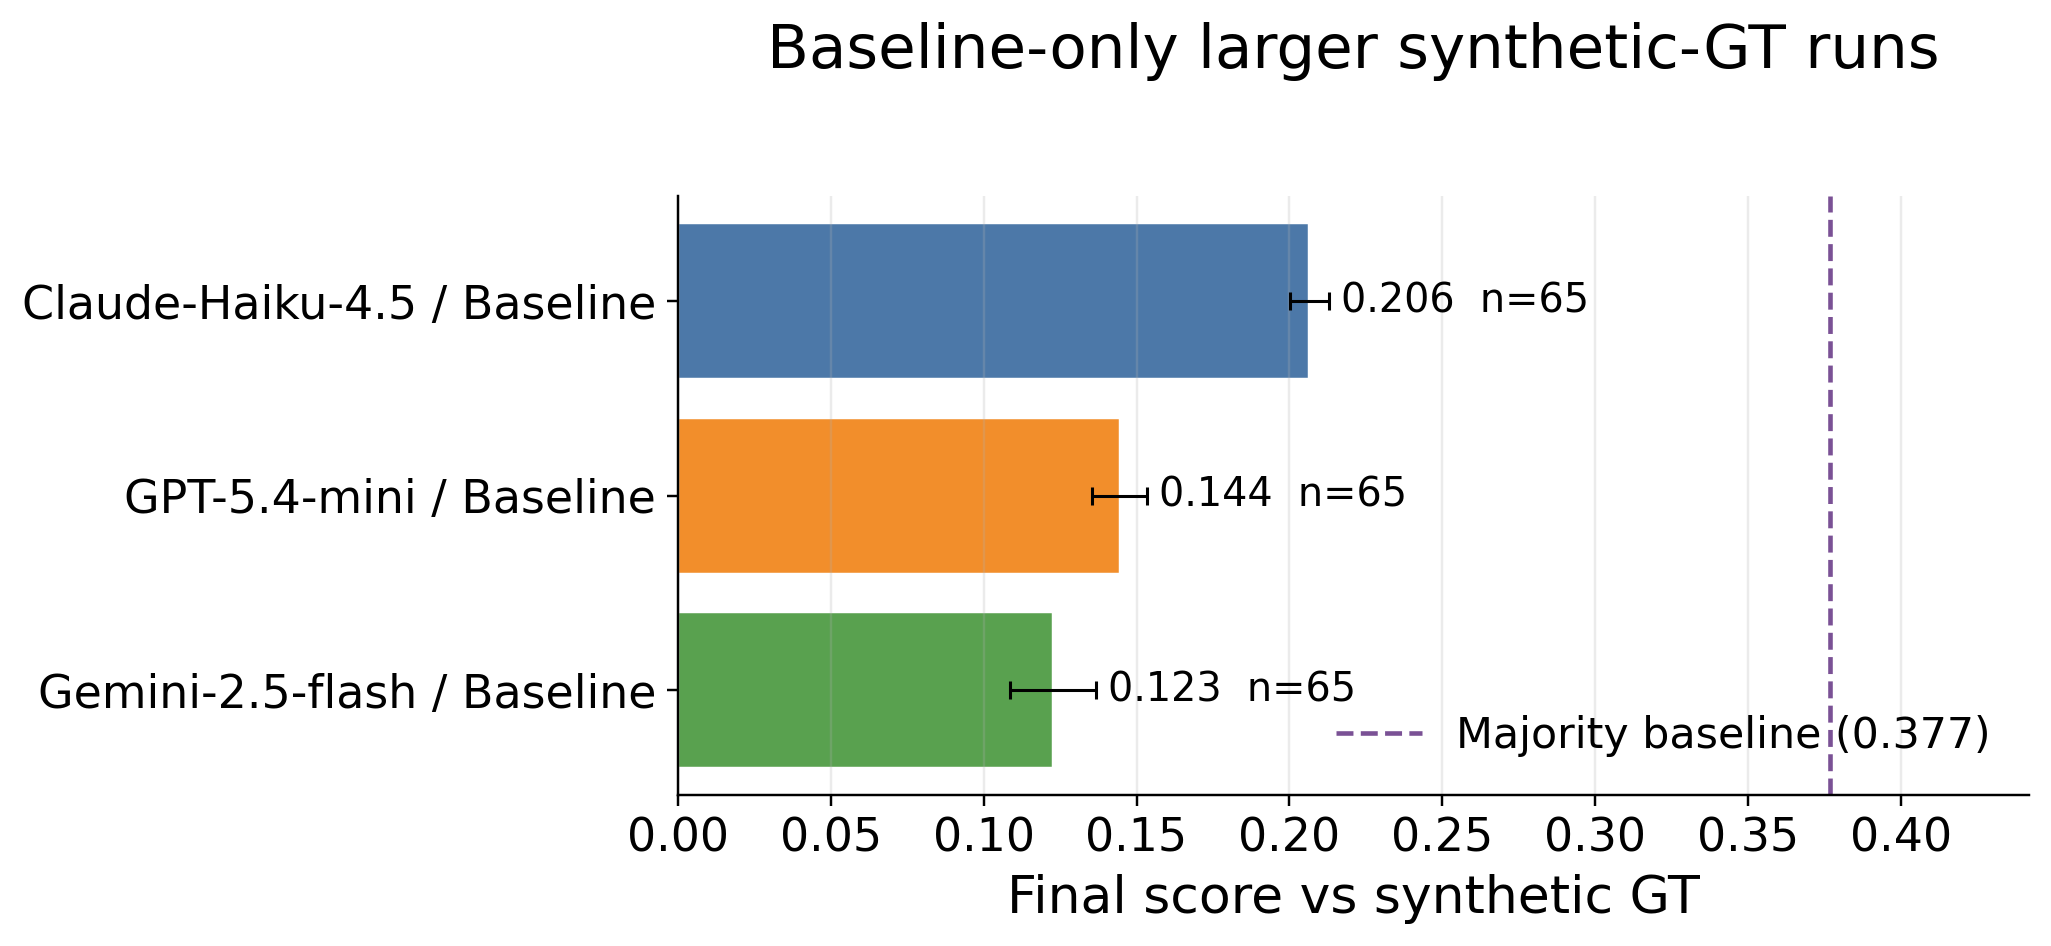

### Baseline-only larger synthetic-GT runs, 65+30 coverage

This companion chart includes both the 65-video plain Baseline runs and the 30-video baseline ablation/action-rule runs.

,analysis,gt_source,method,variant,variant_label,model,model_name,system_label,n_videos,left_exact,right_medium,camera_coarse,left_exact_n,right_medium_n,camera_coarse_n,final_score,final_score_se,n_components,synthetic_gt_records_n
5,baseline_only_larger_synthetic,v3.1 structured LLM extract + tool fix synthetic GT,cot_fixedk3_no_cvs_no_guideline_norecdescs_fmeta/gpt-5.4-mini/cvs_act_current_simple_v1,cot_fixedk3_no_cvs_no_guideline_norecdescs_fmeta,Baseline no-CVS no-guideline,gpt-5.4-mini,GPT-5.4-mini,GPT-5.4-mini / Baseline no-CVS no-guideline,30,0.111,0.027,1.000,221,222,34,0.379,0.009,3,481
3,baseline_only_larger_synthetic,v3.1 structured LLM extract + tool fix synthetic GT,cot_fixedk3_no_cvs_no_guideline_norecdescs_fmeta/claude-haiku-4-5-20251001/cvs_act_current_simple_v1,cot_fixedk3_no_cvs_no_guideline_norecdescs_fmeta,Baseline no-CVS no-guideline,claude-haiku-4-5-20251001,Claude-Haiku-4.5,Claude-Haiku-4.5 / Baseline no-CVS no-guideline,30,0.187,0.031,0.433,221,222,34,0.217,0.024,3,481
9,baseline_only_larger_synthetic,v3.1 structured LLM extract + tool fix synthetic GT,cot_fixedk3_norecdescs_fmeta/claude-haiku-4-5-20251001/cvs_act_current_simple_v1,cot_fixedk3_norecdescs_fmeta,Baseline,claude-haiku-4-5-20251001,Claude-Haiku-4.5,Claude-Haiku-4.5 / Baseline,65,0.142,0.016,0.461,466,458,89,0.206,0.006,3,481
6,baseline_only_larger_synthetic,v3.1 structured LLM extract + tool fix synthetic GT,cot_fixedk3_no_cvs_norecdescs_fmeta/claude-haiku-4-5-20251001/cvs_act_current_simple_v1,cot_fixedk3_no_cvs_norecdescs_fmeta,Baseline no-CVS,claude-haiku-4-5-20251001,Claude-Haiku-4.5,Claude-Haiku-4.5 / Baseline no-CVS,65,0.133,0.026,0.411,466,458,89,0.190,0.010,3,481
4,baseline_only_larger_synthetic,v3.1 structured LLM extract + tool fix synthetic GT,cot_fixedk3_no_cvs_no_guideline_norecdescs_fmeta/gemini-2.5-flash/cvs_act_current_simple_v1,cot_fixedk3_no_cvs_no_guideline_norecdescs_fmeta,Baseline no-CVS no-guideline,gemini-2.5-flash,Gemini-2.5-flash,Gemini-2.5-flash / Baseline no-CVS no-guideline,30,0.147,0.030,0.358,221,222,34,0.178,0.021,3,481
8,baseline_only_larger_synthetic,v3.1 structured LLM extract + tool fix synthetic GT,cot_fixedk3_no_cvs_norecdescs_fmeta/gpt-5.4-mini/cvs_act_current_simple_v1,cot_fixedk3_no_cvs_norecdescs_fmeta,Baseline no-CVS,gpt-5.4-mini,GPT-5.4-mini,GPT-5.4-mini / Baseline no-CVS,30,0.099,0.022,0.414,221,222,34,0.178,0.017,3,481
7,baseline_only_larger_synthetic,v3.1 structured LLM extract + tool fix synthetic GT,cot_fixedk3_no_cvs_norecdescs_fmeta/gemini-2.5-flash/cvs_act_current_simple_v1,cot_fixedk3_no_cvs_norecdescs_fmeta,Baseline no-CVS,gemini-2.5-flash,Gemini-2.5-flash,Gemini-2.5-flash / Baseline no-CVS,30,0.119,0.036,0.346,221,222,34,0.167,0.020,3,481
2,baseline_only_larger_synthetic,v3.1 structured LLM extract + tool fix synthetic GT,cot_fixedk3_no_cvs_no_desc_norecdescs_fmeta/gpt-5.4-mini/cvs_act_current_simple_v1,cot_fixedk3_no_cvs_no_desc_norecdescs_fmeta,Baseline no-CVS no-desc,gpt-5.4-mini,GPT-5.4-mini,GPT-5.4-mini / Baseline no-CVS no-desc,30,0.024,0.030,0.424,221,222,34,0.159,0.011,3,481
12,baseline_only_larger_synthetic,v3.1 structured LLM extract + tool fix synthetic GT,cot_fixedk3_norecdescs_fmeta_arecrules-conservative-visible/claude-haiku-4-5-20251001/cvs_act_current_simple_v1,cot_fixedk3_norecdescs_fmeta_arecrules-conservative-visible,Baseline + action rules,claude-haiku-4-5-20251001,Claude-Haiku-4.5,Claude-Haiku-4.5 / Baseline + action rules,30,0.187,0.042,0.244,221,222,34,0.158,0.021,3,481
1,baseline_only_larger_synthetic,v3.1 structured LLM extract + tool fix synthetic GT,cot_fixedk3_no_cvs_no_desc_norecdescs_fmeta/gemini-2.5-flash/cvs_act_current_simple_v1,cot_fixedk3_no_cvs_no_desc_norecdescs_fmeta,Baseline no-CVS no-desc,gemini-2.5-flash,Gemini-2.5-flash,Gemini-2.5-flash / Baseline no-CVS no-desc,30,0.068,0.018,0.358,221,222,34,0.148,0.016,3,481


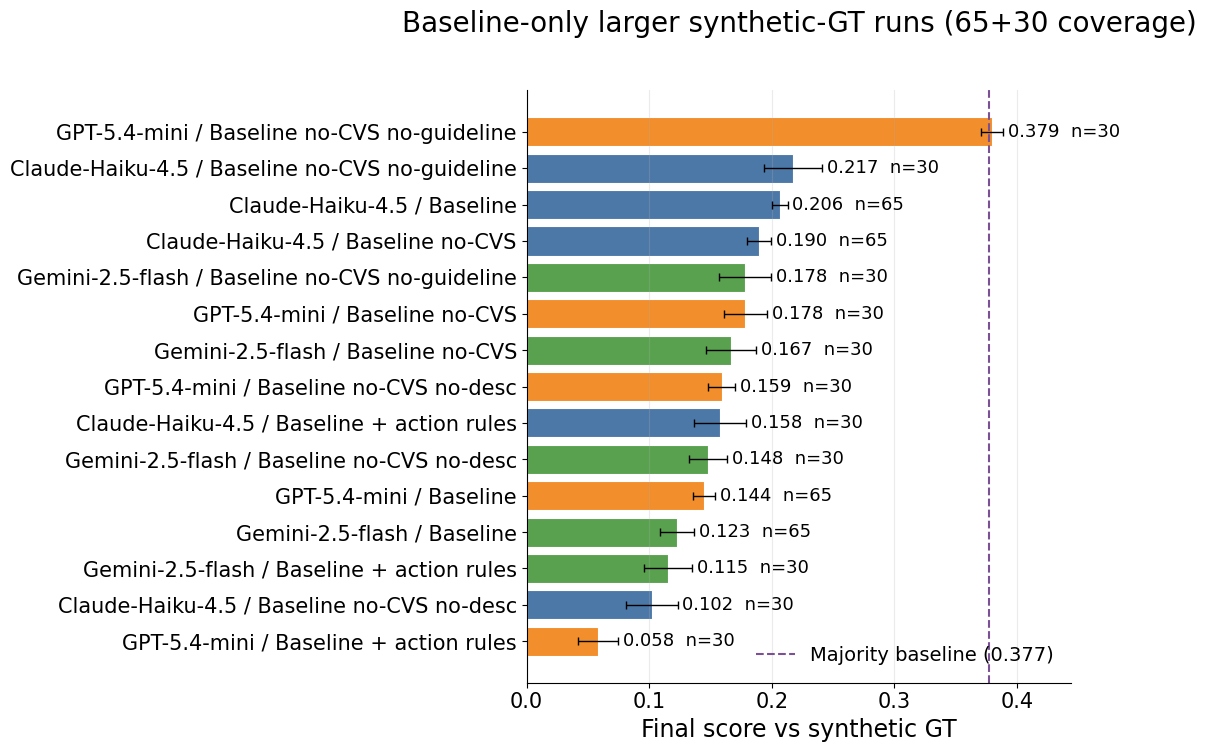

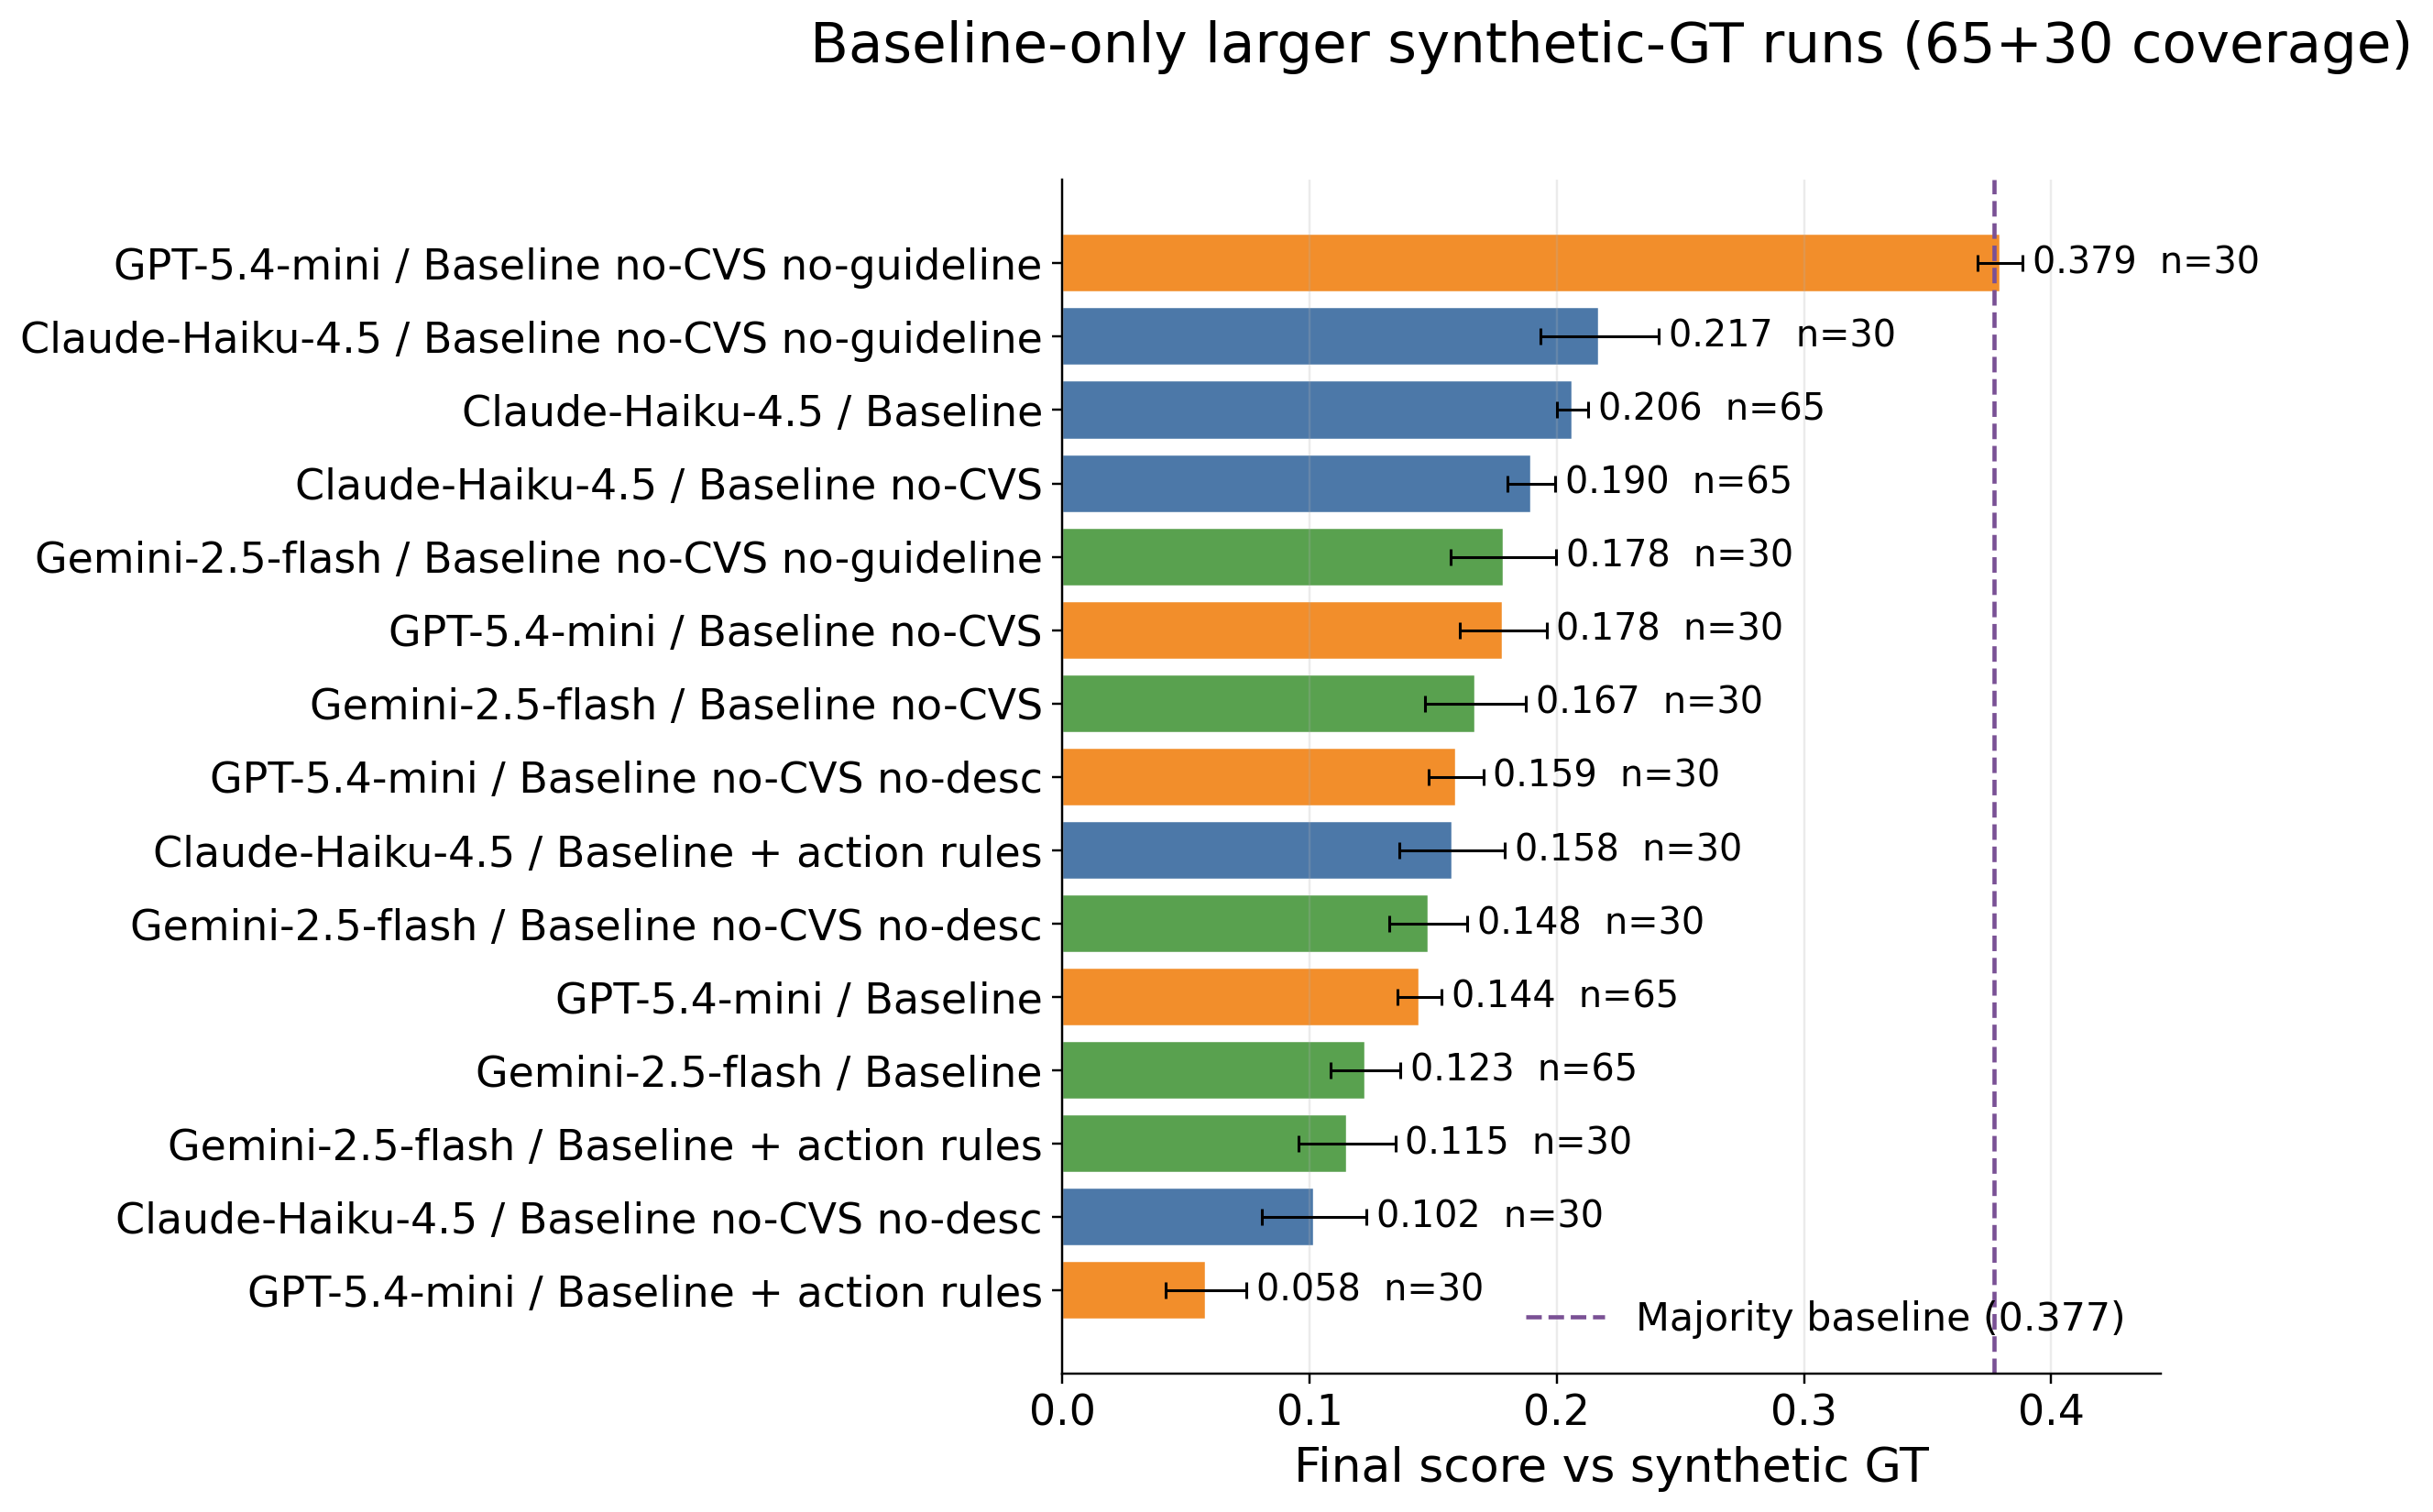

### Baseline pooled synthetic-GT run: 65 larger + 30 human-GT videos

This view pools the plain Baseline score samples from the larger synthetic-GT run (`65` videos) and the human-30 synthetic-GT run (`30` videos). Bootstrap resamples the `95` cached video-level samples, so the baseline error bars use the combined 65+30 evidence.

,analysis,gt_source,method,variant,variant_label,model,model_name,system_label,n_videos,left_exact,right_medium,camera_coarse,left_exact_n,right_medium_n,camera_coarse_n,final_score,final_score_se,n_components,pooled_larger_n_videos,pooled_human30_n_videos,pooled_total_n_videos
0,baseline_pooled_larger65_plus_human30,v3.1 structured LLM extract + tool fix synthetic GT,cot_fixedk3_norecdescs_fmeta/claude-haiku-4-5-20251001/cvs_act_current_simple_v1,cot_fixedk3_norecdescs_fmeta,Baseline,claude-haiku-4-5-20251001,Claude-Haiku-4.5,Claude-Haiku-4.5 / Baseline,95,0.139,0.017,0.463,687,680,123,0.206,0.005,3,65,30,95
2,baseline_pooled_larger65_plus_human30,v3.1 structured LLM extract + tool fix synthetic GT,cot_fixedk3_norecdescs_fmeta/gpt-5.4-mini/cvs_act_current_simple_v1,cot_fixedk3_norecdescs_fmeta,Baseline,gpt-5.4-mini,GPT-5.4-mini,GPT-5.4-mini / Baseline,95,0.024,0.021,0.400,687,680,123,0.149,0.008,3,65,30,95
1,baseline_pooled_larger65_plus_human30,v3.1 structured LLM extract + tool fix synthetic GT,cot_fixedk3_norecdescs_fmeta/gemini-2.5-flash/cvs_act_current_simple_v1,cot_fixedk3_norecdescs_fmeta,Baseline,gemini-2.5-flash,Gemini-2.5-flash,Gemini-2.5-flash / Baseline,95,0.069,0.026,0.285,687,680,123,0.126,0.011,3,65,30,95


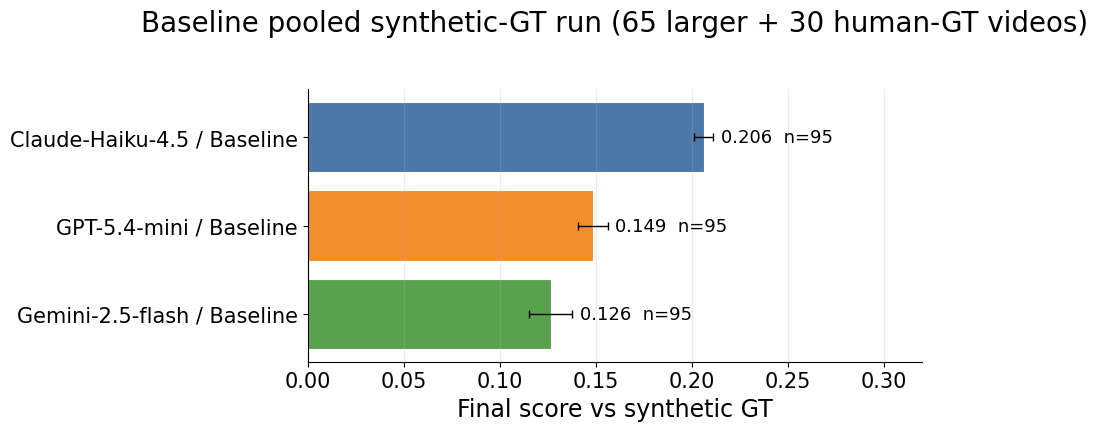

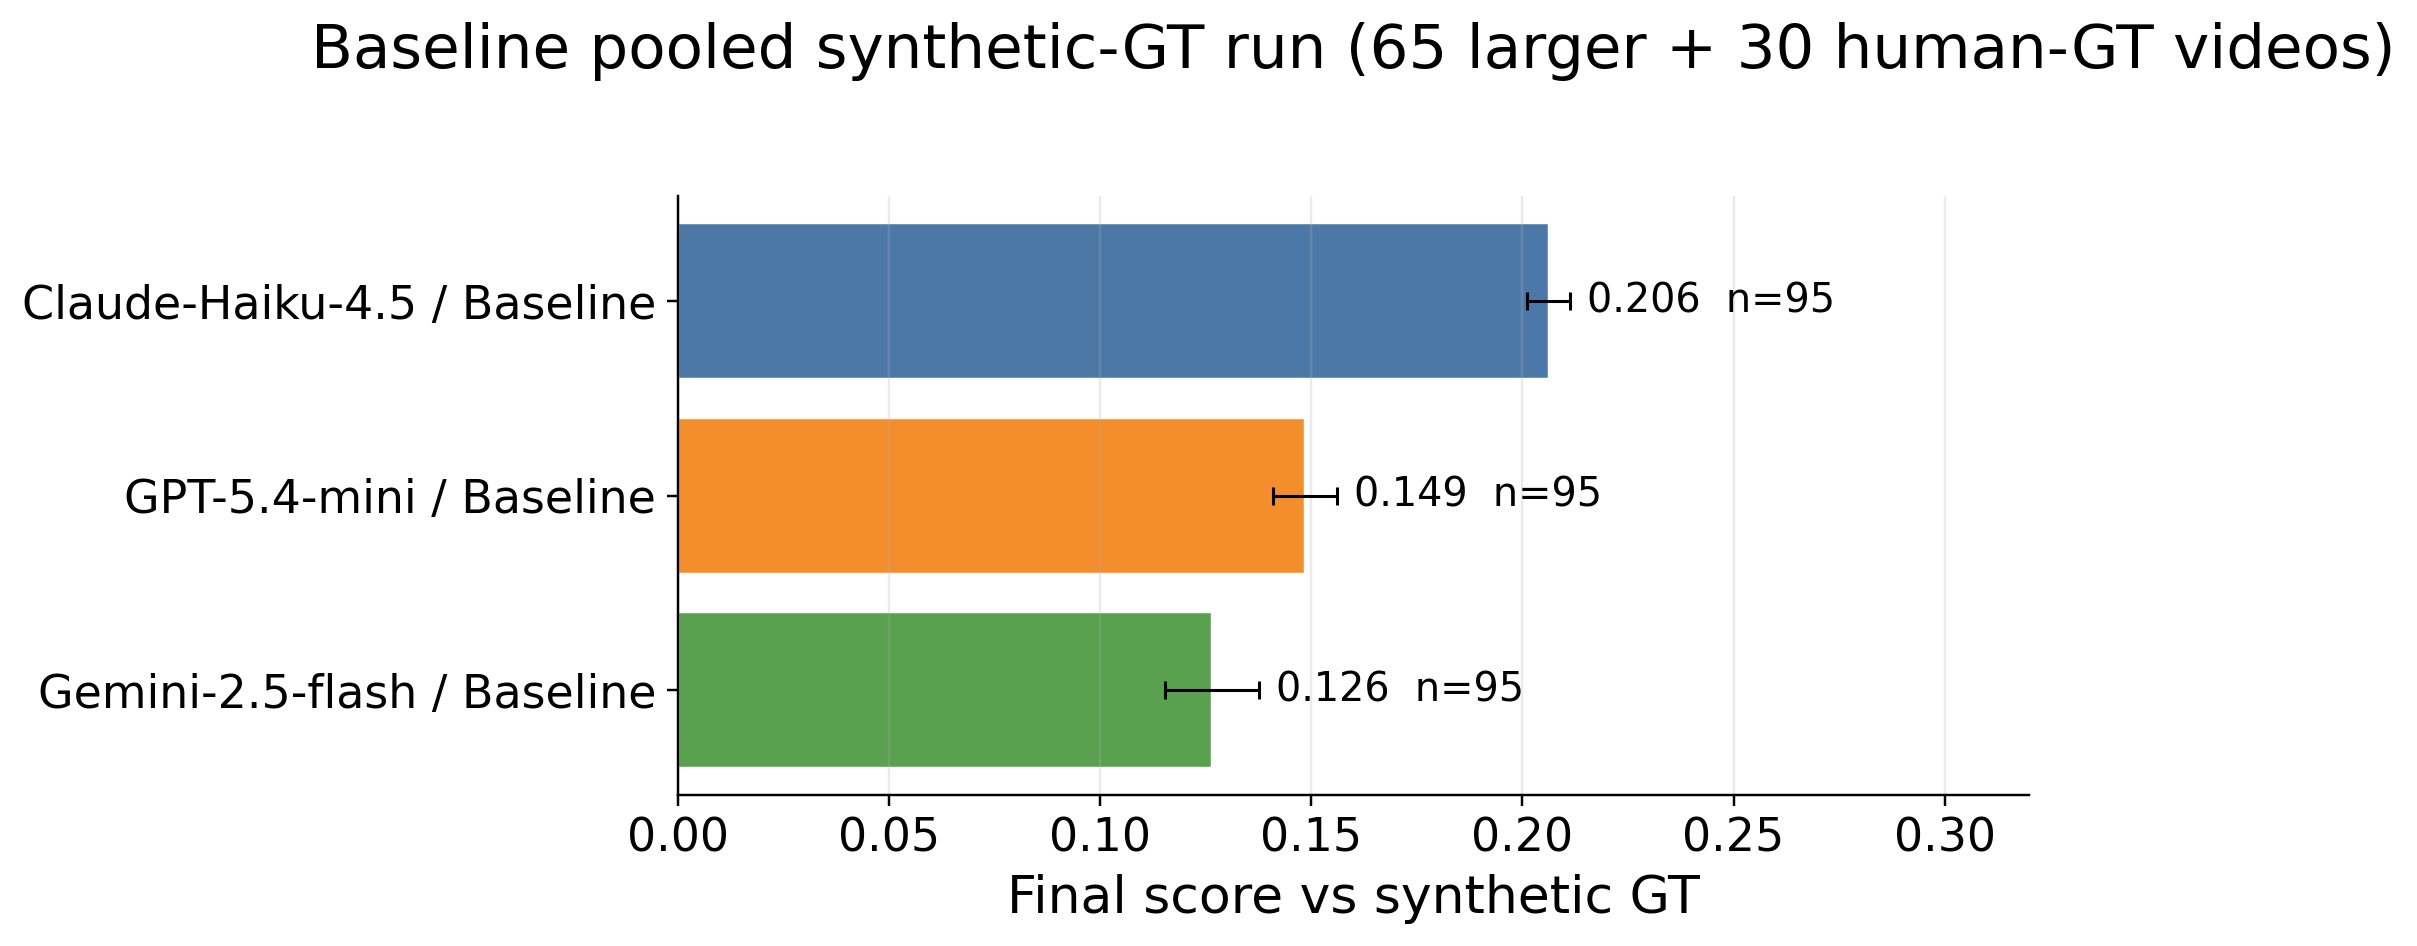

saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/synthetic_gt_baseline_vs_surgent_human30_final_scores.csv
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/synthetic_gt_baseline_vs_surgent_human30_inventory.csv
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/synthetic_gt_majority_baseline_final_scores.csv
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/synthetic_gt_baseline_vs_surgent_human30_final_scores.png
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/synthetic_gt_baseline_vs_surgent_human30_final_scores.pdf
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_summary/synthetic_gt_baseline_only_larger_final_scores.csv
saved /mnt/md0/weiqiuy/surgent/notebooks/artifacts/qwen3.5_audit_v11_current_best_prompt_s

In [14]:

display(Markdown('## Synthetic GT Final Score: 30 Human-GT Videos and Larger Baseline Runs'))

# This section evaluates predictions directly against the v3.1 synthetic GT source, not human GT.
# It has two views:
# 1. Baseline vs SurGent on the 30 videos that define the human-GT analysis set.
# 2. Baseline-only runs on the larger available synthetic-GT coverage.
import sys
for path in [ROOT_DIR / 'scripts/eval', ROOT_DIR / 'src']:
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from evaluate_cvs_act_v1_combined import load_synthetic_action_records, collect_prediction_groups
from evaluate_audit_v11_simple_recommendation import gt_records_by_video
from evaluate_cvs_act_v1_onset_pointwise import collect_eval_points, evaluate_points, resolve_gt_rows, present_label_rows, label_value, label_text

SYNTHETIC_TEST_JSONL = ROOT_DIR / 'hf_repos/cvs-act/sages_synthetic/test.jsonl'
synthetic_records_all = load_synthetic_action_records(SYNTHETIC_TEST_JSONL)
for record in synthetic_records_all:
    record.setdefault('clip_level', 'coarse')

human_gt_video_ids_30 = set(all_split_videos)
synthetic_records_human30 = [record for record in synthetic_records_all if str(record.get('video_id')) in human_gt_video_ids_30]

synthetic_model_filter = {'claude-haiku-4-5-20251001', 'gemini-2.5-flash', 'gpt-5.4-mini'}
synthetic_taxonomy_filter = {'cvs_act_current_simple_v1'}

variant_display = {
    'cot_fixedk3_norecdescs_fmeta': 'Baseline',
    'pref-cvs_arec_steps5_fixedk3_norecdescs_fmeta': 'SurGent',
    'cot_fixedk3_no_cvs_norecdescs_fmeta': 'Baseline no-CVS',
    'cot_fixedk3_no_cvs_no_desc_norecdescs_fmeta': 'Baseline no-CVS no-desc',
    'cot_fixedk3_no_cvs_no_guideline_norecdescs_fmeta': 'Baseline no-CVS no-guideline',
    'cot_fixedk3_norecdescs_fmeta_arecrules-conservative-visible': 'Baseline + action rules',
}
model_display = {
    'claude-haiku-4-5-20251001': 'Claude-Haiku-4.5',
    'gemini-2.5-flash': 'Gemini-2.5-flash',
    'gpt-5.4-mini': 'GPT-5.4-mini',
}
model_order_full = ['Claude-Haiku-4.5', 'Gemini-2.5-flash', 'GPT-5.4-mini']


def variant_from_method(method):
    return str(method).split('/')[0]


def model_from_method(method):
    parts = str(method).split('/')
    return parts[1] if len(parts) > 1 else ''


def score_eval_method_rows(method_rows):
    component_scores = {}
    component_ns = {}
    values = []
    for actor, granularity in final_components:
        usable = [
            row for row in method_rows
            if row.get('clip_level') == 'coarse'
            and row.get('point_source') == 'coarse_actor_onset'
            and row.get('actor') == actor
            and bool_value(row.get('gt_present'))
            and not bool_value(row.get('gt_presence_excluded_uncertain'))
            and not bool_value(row.get('gt_presence_unknown'))
        ]
        gt_col = f'gt_label_resolved_{granularity}'
        pred_col = f'pred_label_{granularity}'
        y_true = [str(row[gt_col]) for row in usable if row.get(gt_col) is not None and row.get(pred_col) is not None]
        y_pred = [str(row[pred_col]) for row in usable if row.get(gt_col) is not None and row.get(pred_col) is not None]
        score = local_multiclass_macro_f1(y_true, y_pred) if y_true else np.nan
        key = f'{actor}_{granularity}'
        component_scores[key] = score
        component_ns[f'{key}_n'] = len(y_true)
        values.append(score)
    return component_scores, component_ns, float(np.nanmean(values)), int(np.isfinite(values).sum())


def confusion_count_rows(y_true, y_pred):
    rows = []
    for label in sorted(set(y_true) | set(y_pred)):
        tp = sum((t == label) and (p == label) for t, p in zip(y_true, y_pred))
        fp = sum((t != label) and (p == label) for t, p in zip(y_true, y_pred))
        fn = sum((t == label) and (p != label) for t, p in zip(y_true, y_pred))
        rows.append({'label': label, 'tp': tp, 'fp': fp, 'fn': fn})
    return rows


def score_eval_method_video_counts(method_rows):
    rows = []
    for actor, granularity in final_components:
        component = f'{actor}_{granularity}'
        usable = [
            row for row in method_rows
            if row.get('clip_level') == 'coarse'
            and row.get('point_source') == 'coarse_actor_onset'
            and row.get('actor') == actor
            and bool_value(row.get('gt_present'))
            and not bool_value(row.get('gt_presence_excluded_uncertain'))
            and not bool_value(row.get('gt_presence_unknown'))
        ]
        gt_col = f'gt_label_resolved_{granularity}'
        pred_col = f'pred_label_{granularity}'
        by_video = {}
        for row in usable:
            if row.get(gt_col) is None or row.get(pred_col) is None:
                continue
            by_video.setdefault(str(row.get('video_id')), []).append(row)
        for video_id, video_rows in by_video.items():
            y_true = [str(row[gt_col]) for row in video_rows]
            y_pred = [str(row[pred_col]) for row in video_rows]
            for count_row in confusion_count_rows(y_true, y_pred):
                rows.append({'video_id': video_id, 'component': component, **count_row})
    return pd.DataFrame(rows)


def component_macro_f1_from_counts(counts):
    if counts.empty:
        return np.nan
    grouped = counts.groupby('label', as_index=False)[['tp', 'fp', 'fn']].sum()
    denom = 2 * grouped['tp'] + grouped['fp'] + grouped['fn']
    scores = (2 * grouped['tp'] / denom).where(denom > 0)
    scores = scores.dropna()
    return float(scores.mean()) if len(scores) else np.nan


def final_score_from_count_table(count_table):
    component_scores = []
    component_order = [f'{actor}_{granularity}' for actor, granularity in final_components]
    for component in component_order:
        component_scores.append(component_macro_f1_from_counts(count_table[count_table['component'].eq(component)]))
    return float(np.nanmean(component_scores)) if np.isfinite(component_scores).any() else np.nan


def build_video_count_arrays(video_count_table):
    video_ids = sorted(video_count_table['video_id'].astype(str).unique())
    video_index = {video_id: idx for idx, video_id in enumerate(video_ids)}
    component_order = [f'{actor}_{granularity}' for actor, granularity in final_components]
    arrays = {}
    for component in component_order:
        comp = video_count_table[video_count_table['component'].eq(component)]
        labels = sorted(comp['label'].astype(str).unique()) if not comp.empty else []
        if not labels:
            arrays[component] = None
            continue
        label_index = {label: idx for idx, label in enumerate(labels)}
        tp = np.zeros((len(video_ids), len(labels)), dtype=float)
        fp = np.zeros_like(tp)
        fn = np.zeros_like(tp)
        for row in comp.itertuples(index=False):
            i = video_index[str(row.video_id)]
            j = label_index[str(row.label)]
            tp[i, j] += float(row.tp)
            fp[i, j] += float(row.fp)
            fn[i, j] += float(row.fn)
        arrays[component] = (tp, fp, fn)
    return video_ids, arrays


def macro_f1_from_summed_counts(tp_sum, fp_sum, fn_sum):
    denom = 2 * tp_sum + fp_sum + fn_sum
    valid = denom > 0
    if not np.any(valid):
        return np.nan
    return float(np.mean((2 * tp_sum[valid]) / denom[valid]))


def bootstrap_eval_method_final_score_se(method_rows, seed, n_boot=BOOTSTRAP_N):
    video_count_table = score_eval_method_video_counts(method_rows)
    if video_count_table.empty:
        return np.nan
    video_ids, arrays = build_video_count_arrays(video_count_table)
    if len(video_ids) < 2:
        return np.nan
    rng = np.random.default_rng(seed)
    scores = []
    for _ in range(n_boot):
        sampled = rng.integers(0, len(video_ids), size=len(video_ids))
        component_scores = []
        for counts in arrays.values():
            if counts is None:
                component_scores.append(np.nan)
                continue
            tp, fp, fn = counts
            component_scores.append(macro_f1_from_summed_counts(
                tp[sampled, :].sum(axis=0),
                fp[sampled, :].sum(axis=0),
                fn[sampled, :].sum(axis=0),
            ))
        scores.append(float(np.nanmean(component_scores)))
    scores = np.asarray(scores, dtype=float)
    scores = scores[np.isfinite(scores)]
    return float(np.std(scores, ddof=1)) if len(scores) > 1 else np.nan


def score_eval_rows(eval_rows, *, title):
    rows = []
    for method_index, method in enumerate(sorted({row['method'] for row in eval_rows})):
        method_rows = [row for row in eval_rows if row['method'] == method]
        variant = variant_from_method(method)
        model = model_from_method(method)
        component_scores, component_ns, final_score, n_components = score_eval_method_rows(method_rows)
        final_score_se = bootstrap_eval_method_final_score_se(method_rows, 50_000 + method_index)
        video_count = len({str(row.get('video_id')) for row in method_rows})
        rows.append({
            'analysis': title,
            'gt_source': 'v3.1 structured LLM extract + tool fix synthetic GT',
            'method': method,
            'variant': variant,
            'variant_label': variant_display.get(variant, variant),
            'model': model,
            'model_name': model_display.get(model, model),
            'system_label': f'{model_display.get(model, model)} / {variant_display.get(variant, variant)}',
            'n_videos': video_count,
            **component_scores,
            **component_ns,
            'final_score': final_score,
            'final_score_se': final_score_se,
            'n_components': n_components,
        })
    return pd.DataFrame(rows)


def evaluate_synthetic_records(records, output_dirs):
    gt_by_video = gt_records_by_video(records)
    frames_by_method, paths_by_method, skipped = collect_prediction_groups(
        [path if path.is_absolute() else ROOT_DIR / path for path in output_dirs],
        gt_by_video,
        True,
        None,
        synthetic_model_filter,
        synthetic_taxonomy_filter,
        False,
    )
    eval_rows = evaluate_points(frames_by_method, collect_eval_points(records))
    inventory = pd.DataFrame([
        {
            'method': method,
            'variant': variant_from_method(method),
            'variant_label': variant_display.get(variant_from_method(method), variant_from_method(method)),
            'model': model_from_method(method),
            'model_name': model_display.get(model_from_method(method), model_from_method(method)),
            'n_prediction_videos': len(by_video),
        }
        for method, by_video in sorted(frames_by_method.items())
    ])
    return eval_rows, inventory, skipped

def majority_component_scores_from_synthetic_records(records, analysis_label):
    points = collect_eval_points(records)
    rows = []
    values = []
    for actor, granularity in final_components:
        labels = []
        for point in points:
            if point.get('actor') != actor:
                continue
            record = point['record']
            if record.get('clip_level', 'coarse') != 'coarse' or point.get('point_source') != 'coarse_actor_onset':
                continue
            gt_rows = present_label_rows(resolve_gt_rows(point, actor, int(point['point_frame'])), actor)
            if not gt_rows:
                continue
            gt_labels = [label_text(label_value(row, actor, granularity)) for row in gt_rows if label_value(row, actor, granularity) is not None]
            if not gt_labels:
                continue
            labels.append(sorted(gt_labels)[0])
        if labels:
            majority_label = pd.Series(labels).mode().iat[0]
            score = local_multiclass_macro_f1(labels, [majority_label] * len(labels))
        else:
            majority_label = ''
            score = np.nan
        component = f'{actor}_{granularity}'
        rows.append({
            'analysis': analysis_label,
            'gt_source': 'v3.1 structured LLM extract + tool fix synthetic GT',
            'component': component,
            'actor': actor,
            'granularity': granularity,
            'majority_label': majority_label,
            'majority_label_macro_f1': score,
            'n': len(labels),
            'n_videos': len({str(record.get('video_id')) for record in records}),
            'synthetic_gt_records_n': len(records),
        })
        values.append(score)
    rows.append({
        'analysis': analysis_label,
        'gt_source': 'v3.1 structured LLM extract + tool fix synthetic GT',
        'component': 'final_score',
        'actor': 'aggregate',
        'granularity': 'final',
        'majority_label': '',
        'majority_label_macro_f1': float(np.nanmean(values)),
        'n': int(sum(row['n'] for row in rows)),
        'n_videos': len({str(record.get('video_id')) for record in records}),
        'synthetic_gt_records_n': len(records),
    })
    return pd.DataFrame(rows)


def final_majority_score(majority_df):
    if majority_df is None or majority_df.empty or 'component' not in majority_df.columns:
        return np.nan
    row = majority_df[majority_df['component'].eq('final_score')]
    return float(row['majority_label_macro_f1'].iloc[0]) if not row.empty else np.nan

baseline_surgent_dirs = [
    ROOT_DIR / 'outputs/cot_audit_v11_simple/cot_fixedk3_norecdescs_fmeta',
    ROOT_DIR / 'outputs/surgent_sequential_agent_audit_v11_simple/cot/pref-cvs_arec_steps5_fixedk3_norecdescs_fmeta',
]
bs_eval_rows, bs_inventory, bs_skipped = evaluate_synthetic_records(synthetic_records_human30, baseline_surgent_dirs)
bs_score_df = score_eval_rows(bs_eval_rows, title='baseline_vs_surgent_human30')
bs_score_df['requested_video_set_n'] = len(human_gt_video_ids_30)
bs_score_df['synthetic_gt_records_n'] = len(synthetic_records_human30)

baseline_only_dirs = [
    ROOT_DIR / 'outputs/cot_audit_v11_simple/cot_fixedk3_norecdescs_fmeta',
    ROOT_DIR / 'outputs/cot_audit_v11_simple/cot_fixedk3_no_cvs_norecdescs_fmeta',
    ROOT_DIR / 'outputs/cot_audit_v11_simple/cot_fixedk3_no_cvs_no_desc_norecdescs_fmeta',
    ROOT_DIR / 'outputs/cot_audit_v11_simple/cot_fixedk3_no_cvs_no_guideline_norecdescs_fmeta',
    ROOT_DIR / 'outputs/cot_audit_v11_simple/cot_fixedk3_norecdescs_fmeta_arecrules-conservative-visible',
]
bo_eval_rows, bo_inventory, bo_skipped = evaluate_synthetic_records(synthetic_records_all, baseline_only_dirs)
bo_score_df = score_eval_rows(bo_eval_rows, title='baseline_only_larger_synthetic')
bo_score_df['synthetic_gt_records_n'] = len(synthetic_records_all)

def prefix_eval_video_ids(rows, source_label):
    out = []
    for row in rows:
        copied = dict(row)
        copied['original_video_id'] = str(row.get('video_id'))
        copied['video_id'] = f'{source_label}::{row.get("video_id")}'
        copied['pooled_source'] = source_label
        out.append(copied)
    return out


plain_baseline_variant = 'cot_fixedk3_norecdescs_fmeta'
bs_plain_baseline_eval_rows = [
    row for row in bs_eval_rows
    if variant_from_method(row.get('method')) == plain_baseline_variant
]
bo_plain_baseline_eval_rows = [
    row for row in bo_eval_rows
    if variant_from_method(row.get('method')) == plain_baseline_variant
]
bo_combined_eval_rows = (
    prefix_eval_video_ids(bo_plain_baseline_eval_rows, 'larger65')
    + prefix_eval_video_ids(bs_plain_baseline_eval_rows, 'human30')
)
bo_combined_inventory = pd.DataFrame([
    {'pooled_source': 'larger65', 'n_eval_rows': len(bo_plain_baseline_eval_rows), 'n_videos': len({str(row.get('video_id')) for row in bo_plain_baseline_eval_rows})},
    {'pooled_source': 'human30', 'n_eval_rows': len(bs_plain_baseline_eval_rows), 'n_videos': len({str(row.get('video_id')) for row in bs_plain_baseline_eval_rows})},
])
bo_combined_score_df = score_eval_rows(bo_combined_eval_rows, title='baseline_pooled_larger65_plus_human30')
bo_combined_score_df['pooled_larger_n_videos'] = int(bo_combined_inventory.loc[bo_combined_inventory['pooled_source'].eq('larger65'), 'n_videos'].iloc[0])
bo_combined_score_df['pooled_human30_n_videos'] = int(bo_combined_inventory.loc[bo_combined_inventory['pooled_source'].eq('human30'), 'n_videos'].iloc[0])
bo_combined_score_df['pooled_total_n_videos'] = bo_combined_score_df['pooled_larger_n_videos'] + bo_combined_score_df['pooled_human30_n_videos']

bs_majority_df = majority_component_scores_from_synthetic_records(synthetic_records_human30, 'baseline_vs_surgent_human30')
bo_majority_df = majority_component_scores_from_synthetic_records(synthetic_records_all, 'baseline_only_larger_synthetic')
bo_combined_majority_df = majority_component_scores_from_synthetic_records(
    synthetic_records_all + synthetic_records_human30,
    'baseline_pooled_larger65_plus_human30',
)
synthetic_majority_df = pd.concat([bs_majority_df, bo_majority_df, bo_combined_majority_df], ignore_index=True)

bs_score_csv = OUT_DIR / 'synthetic_gt_baseline_vs_surgent_human30_final_scores.csv'
bs_inventory_csv = OUT_DIR / 'synthetic_gt_baseline_vs_surgent_human30_inventory.csv'
bo_score_csv = OUT_DIR / 'synthetic_gt_baseline_only_larger_final_scores.csv'
bo_inventory_csv = OUT_DIR / 'synthetic_gt_baseline_only_larger_inventory.csv'
bo_combined_score_csv = OUT_DIR / 'synthetic_gt_baseline_only_larger_plus_human30_final_scores.csv'
bo_combined_inventory_csv = OUT_DIR / 'synthetic_gt_baseline_only_larger_plus_human30_inventory.csv'
synthetic_majority_csv = OUT_DIR / 'synthetic_gt_majority_baseline_final_scores.csv'
bs_score_df.to_csv(bs_score_csv, index=False)
bs_inventory.to_csv(bs_inventory_csv, index=False)
bo_score_df.to_csv(bo_score_csv, index=False)
bo_inventory.to_csv(bo_inventory_csv, index=False)
bo_combined_score_df.to_csv(bo_combined_score_csv, index=False)
bo_combined_inventory.to_csv(bo_combined_inventory_csv, index=False)
synthetic_majority_df.to_csv(synthetic_majority_csv, index=False)

display(Markdown(f'Baseline vs SurGent uses `{len(human_gt_video_ids_30)}` requested human-GT videos and `{len(synthetic_records_human30)}` synthetic GT records. Prediction coverage is `{int(bs_score_df["n_videos"].min())}`-`{int(bs_score_df["n_videos"].max())}` videos across the six systems.'))
display(bs_score_df.sort_values(['model_name', 'variant_label']).style.format({
    'left_exact': '{:.3f}',
    'right_medium': '{:.3f}',
    'camera_coarse': '{:.3f}',
    'final_score': '{:.3f}',
    'final_score_se': '{:.3f}',
}, na_rep=''))

fig, ax = plt.subplots(figsize=(12.8, 7.2))
plot_df = bs_score_df.copy()
bs_majority_score = final_majority_score(bs_majority_df)
plot_df['model_name'] = pd.Categorical(plot_df['model_name'], categories=model_order_full, ordered=True)
plot_df = plot_df.sort_values(['model_name', 'variant_label'])
x_pos = np.arange(len(model_order_full))
bar_width = 0.34
for offset, variant_label, color in [(-bar_width / 2, 'Baseline', '#4C78A8'), (bar_width / 2, 'SurGent', '#F28E2B')]:
    vals = []
    ses = []
    labels_n = []
    for model_name in model_order_full:
        row = plot_df[(plot_df['model_name'].astype(str) == model_name) & (plot_df['variant_label'] == variant_label)]
        vals.append(float(row['final_score'].iloc[0]) if not row.empty else np.nan)
        ses.append(float(row['final_score_se'].iloc[0]) if not row.empty and pd.notna(row['final_score_se'].iloc[0]) else 0.0)
        labels_n.append(int(row['n_videos'].iloc[0]) if not row.empty else 0)
    bars = ax.barh(
        x_pos + offset,
        vals,
        height=bar_width,
        color=color,
        label=variant_label,
        edgecolor='white',
        linewidth=0.8,
        xerr=ses,
        capsize=3,
        error_kw={'elinewidth': 1.0, 'capthick': 1.0},
    )
    for rect, val, se, n_videos in zip(bars, vals, ses, labels_n):
        if np.isfinite(val):
            ax.text(val + se + 0.006, rect.get_y() + rect.get_height() / 2, f'{val:.3f}  n={n_videos}', ha='left', va='center', fontsize=13)
ax.set_yticks(x_pos)
ax.set_yticklabels(model_order_full, fontsize=15)
if np.isfinite(bs_majority_score):
    ax.axvline(bs_majority_score, color='#7A5195', linestyle='--', linewidth=1.5, label=f'Majority baseline ({bs_majority_score:.3f})')
ax.set_xlabel('Final score vs synthetic GT', fontsize=17)
ax.set_title('Synthetic GT final score on 30 human-GT videos', fontsize=20, pad=42)
ymax = max(float(plot_df['final_score'].max()), bs_majority_score if np.isfinite(bs_majority_score) else 0)
ax.set_xlim(0, max(0.32, ymax + 0.07))
ax.grid(axis='x', alpha=0.25)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(frameon=False, loc='lower center', bbox_to_anchor=(0.5, -0.24), ncols=3, fontsize=15)
plt.tight_layout()
bs_png = OUT_DIR / 'synthetic_gt_baseline_vs_surgent_human30_final_scores.png'
bs_pdf = OUT_DIR / 'synthetic_gt_baseline_vs_surgent_human30_final_scores.pdf'
fig.savefig(bs_png, dpi=220, bbox_inches='tight')
fig.savefig(bs_pdf, bbox_inches='tight')
plt.show()
display(__import__('IPython.display', fromlist=['Image']).Image(filename=str(bs_png)))

display(Markdown('### Baseline-only larger synthetic-GT runs'))
bo_plain_score_df = bo_score_df[bo_score_df['variant_label'].eq('Baseline')].copy()
display(Markdown(f'This view uses the plain baseline method for Claude/Gemini/GPT on its available larger synthetic-test prediction videos. Coverage is `{int(bo_plain_score_df["n_videos"].min())}`-`{int(bo_plain_score_df["n_videos"].max())}` videos.'))
display(bo_plain_score_df.sort_values('final_score', ascending=False).style.format({
    'left_exact': '{:.3f}',
    'right_medium': '{:.3f}',
    'camera_coarse': '{:.3f}',
    'final_score': '{:.3f}',
    'final_score_se': '{:.3f}',
}, na_rep=''))


def plot_larger_synthetic_bar(score_df, title, stem, figsize, majority_df=None):
    fig, ax = plt.subplots(figsize=figsize)
    plot = score_df.sort_values('final_score', ascending=True).copy()
    majority_score = final_majority_score(majority_df if majority_df is not None else bo_majority_df)
    y_pos = np.arange(len(plot))
    colors = plot['model_name'].map({'Claude-Haiku-4.5': '#4C78A8', 'Gemini-2.5-flash': '#59A14F', 'GPT-5.4-mini': '#F28E2B'}).fillna('#777777')
    xerr = plot['final_score_se'].fillna(0.0) if 'final_score_se' in plot.columns else 0.0
    ax.barh(
        y_pos,
        plot['final_score'],
        color=colors,
        edgecolor='white',
        linewidth=0.8,
        xerr=xerr,
        capsize=3,
        error_kw={'elinewidth': 1.0, 'capthick': 1.0},
    )
    ax.set_yticks(y_pos)
    ax.set_yticklabels([f'{row.model_name} / {row.variant_label}' for row in plot.itertuples()], fontsize=15)
    if np.isfinite(majority_score):
        ax.axvline(majority_score, color='#7A5195', linestyle='--', linewidth=1.5, label=f'Majority baseline ({majority_score:.3f})')
    ax.set_xlabel('Final score vs synthetic GT', fontsize=17)
    ax.set_title(title, fontsize=20, pad=42)
    xmax = max(float(plot['final_score'].max()), majority_score if np.isfinite(majority_score) else 0)
    ax.set_xlim(0, max(0.32, xmax + 0.065))
    for idx, row in enumerate(plot.itertuples()):
        se = row.final_score_se if pd.notna(row.final_score_se) else 0.0
        ax.text(row.final_score + se + 0.004, idx, f'{row.final_score:.3f}  n={row.n_videos}', va='center', fontsize=13)
    ax.grid(axis='x', alpha=0.25)
    if np.isfinite(majority_score):
        ax.legend(frameon=False, loc='lower right')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    png = OUT_DIR / f'{stem}.png'
    pdf = OUT_DIR / f'{stem}.pdf'
    fig.savefig(png, dpi=220, bbox_inches='tight')
    fig.savefig(pdf, bbox_inches='tight')
    plt.show()
    display(__import__('IPython.display', fromlist=['Image']).Image(filename=str(png)))
    return png, pdf


bo_png, bo_pdf = plot_larger_synthetic_bar(
    bo_plain_score_df,
    'Baseline-only larger synthetic-GT runs',
    'synthetic_gt_baseline_only_larger_final_scores',
    (9.6, 4.6),
)

display(Markdown('### Baseline-only larger synthetic-GT runs, 65+30 coverage'))
display(Markdown('This companion chart includes both the 65-video plain Baseline runs and the 30-video baseline ablation/action-rule runs.'))
display(bo_score_df.sort_values('final_score', ascending=False).style.format({
    'left_exact': '{:.3f}',
    'right_medium': '{:.3f}',
    'camera_coarse': '{:.3f}',
    'final_score': '{:.3f}',
    'final_score_se': '{:.3f}',
}, na_rep=''))
bo_all_png, bo_all_pdf = plot_larger_synthetic_bar(
    bo_score_df,
    'Baseline-only larger synthetic-GT runs (65+30 coverage)',
    'synthetic_gt_baseline_only_larger_65plus30_final_scores',
    (11.2, 7.8),
)

display(Markdown('### Baseline pooled synthetic-GT run: 65 larger + 30 human-GT videos'))
display(Markdown(f'This view pools the plain Baseline score samples from the larger synthetic-GT run (`{int(bo_combined_score_df["pooled_larger_n_videos"].iloc[0])}` videos) and the human-30 synthetic-GT run (`{int(bo_combined_score_df["pooled_human30_n_videos"].iloc[0])}` videos). Bootstrap resamples the `{int(bo_combined_score_df["pooled_total_n_videos"].iloc[0])}` cached video-level samples, so the baseline error bars use the combined 65+30 evidence.'))
display(bo_combined_score_df.sort_values('final_score', ascending=False).style.format({
    'left_exact': '{:.3f}',
    'right_medium': '{:.3f}',
    'camera_coarse': '{:.3f}',
    'final_score': '{:.3f}',
    'final_score_se': '{:.3f}',
}, na_rep=''))
bo_combined_png, bo_combined_pdf = plot_larger_synthetic_bar(
    bo_combined_score_df,
    'Baseline pooled synthetic-GT run (65 larger + 30 human-GT videos)',
    'synthetic_gt_baseline_only_larger_plus_human30_final_scores',
    (9.6, 4.6),
    majority_df=bo_combined_majority_df,
)

for path in [bs_score_csv, bs_inventory_csv, synthetic_majority_csv, bs_png, bs_pdf, bo_score_csv, bo_inventory_csv, bo_png, bo_pdf, bo_all_png, bo_all_pdf, bo_combined_score_csv, bo_combined_inventory_csv, bo_combined_png, bo_combined_pdf]:
    print(f'saved {path}')
